Section 1 - Libraries and configuration

In [1]:

# ============================================================
# SECTION 1 — CONFIGURATION
# ============================================================

from pathlib import Path
import random
import warnings
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_DIR = Path.cwd()

OUTPUT_DIR = PROJECT_DIR / "Expanded_LSTM_Results"
MODEL_DIR = OUTPUT_DIR / "Models"
RESULTS_DIR = OUTPUT_DIR / "Anomaly_Results"
EVENT_DIR = OUTPUT_DIR / "Anomaly_Events"
PLOTS_DIR = OUTPUT_DIR / "Plots"
INJECTION_DIR = OUTPUT_DIR / "Fault_Injection"

for directory in [
    OUTPUT_DIR, MODEL_DIR, RESULTS_DIR,
    EVENT_DIR, PLOTS_DIR, INJECTION_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

DATA_FILES = {
    "Client1": PROJECT_DIR / "Client1(all).csv",
    "Client2": PROJECT_DIR / "Client2(all).csv",
    "Client3": PROJECT_DIR / "Client3(all).csv",
    "Switch": PROJECT_DIR / "Switch(all).csv"
}

DEVICES = ["Client1", "Client2", "Client3", "Switch"]

SEED = 42
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

SEQUENCE_LENGTH = 30
SEQUENCE_STRIDE = 1

BATCH_SIZE = 32
EPOCHS = 50
LEARNING_RATE = 0.001
EARLY_STOPPING_PATIENCE = 7

ANOMALY_PERCENTILE = 99
PREDICTION_BATCH_SIZE = 256

MAX_GAP_SECONDS = {
    "Client1": 30,
    "Client2": 30,
    "Client3": 30,
    "Switch": 20
}

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

CLIENT_METRICS = [
    "cpu_pct",
    "temperature_c",
    "latency_ms",
    "packet_loss_pct",
    "disk_usage_pct",
    "throughput_bytes_per_sec",
    "packet_error_rate_pct",
    "reachability",
    "cpu_voltage_v",
    "power_supply_low_voltage",
    "cpu_speed_capped",
    "cpu_throttled",
    "cpu_clock_mhz",
    "est_power_draw_w"
]

SWITCH_SYSTEM_METRICS = [
    "cpu_pct",
    "free_memory",
    "temperature",
    "power_supply_state"
]

SWITCH_RATE_METRICS = [
    f"interface_{port}_{direction}_{counter}_rate"
    for port in range(1, 5)
    for direction in ["in", "out"]
    for counter in ["bytes", "errors"]
]

SWITCH_METRICS = (
    SWITCH_SYSTEM_METRICS + SWITCH_RATE_METRICS
)

device_metrics = {
    "Client1": CLIENT_METRICS.copy(),
    "Client2": CLIENT_METRICS.copy(),
    "Client3": CLIENT_METRICS.copy(),
    "Switch": SWITCH_METRICS.copy()
}

assert len(CLIENT_METRICS) == 14
assert len(SWITCH_METRICS) == 20

print("=" * 65)
print("SECTION 1 COMPLETE")
print("=" * 65)
print("TensorFlow version:", tf.__version__)
print("Project directory:", PROJECT_DIR)
print("Results directory:", OUTPUT_DIR)

for device, metrics in device_metrics.items():
    print(f"{device}: {len(metrics)} features")


SECTION 1 COMPLETE
TensorFlow version: 2.21.0
Project directory: c:\Users\alwyn\OneDrive\Documents\Year 3 - Semester 2\Capstone
Results directory: c:\Users\alwyn\OneDrive\Documents\Year 3 - Semester 2\Capstone\Expanded_LSTM_Results
Client1: 14 features
Client2: 14 features
Client3: 14 features
Switch: 20 features


Section 2 - Data Loading and preprocessing

In [2]:
# ============================================================
# SECTION 2 — DATA LOADING AND PREPROCESSING
# ============================================================

datasets = {}
original_datasets = {}
dataset_summary = []

def read_wide_csv(path):

    if not path.exists():
        raise FileNotFoundError(
            f"Dataset not found: {path}"
        )

    df = pd.read_csv(path, low_memory=False)
    df.columns = [str(col).strip() for col in df.columns]

    time_candidates = [
        "timestamp", "_time", "time", "Timestamp"
    ]

    time_column = next(
        (col for col in time_candidates if col in df.columns),
        None
    )

    if time_column is None:
        raise ValueError(
            f"Missing timestamp column in {path.name}. "
            f"Available: {df.columns.tolist()}"
        )

    df = df.rename(columns={time_column: "timestamp"})

    df["timestamp"] = pd.to_datetime(
        df["timestamp"],
        utc=True,
        errors="coerce"
    )

    df = (
        df.dropna(subset=["timestamp"])
        .sort_values("timestamp")
        .drop_duplicates("timestamp", keep="last")
        .reset_index(drop=True)
    )

    return df


def standardise_columns(df, device):

    df = df.copy()

    if device == "Switch":
        aliases = {
            "cpu_load": "cpu_pct",
            "free_ram": "free_memory",
            "temp": "temperature",
            "power_supply_status": "power_supply_state"
        }
    else:
        aliases = {
            "temp_c": "temperature_c",
            "temperature": "temperature_c"
        }

    for old, new in aliases.items():

        if old in df.columns and new not in df.columns:
            df = df.rename(columns={old: new})

    return df


def engineer_switch_rates(df):

    df = df.copy()

    elapsed = (
        df["timestamp"]
        .diff()
        .dt.total_seconds()
    )

    valid_interval = (
        (elapsed > 0)
        & (elapsed <= MAX_GAP_SECONDS["Switch"])
    )

    for port in range(1, 5):
        for direction in ["in", "out"]:
            for counter_type in ["bytes", "errors"]:

                counter_name = (
                    f"interface_{port}_"
                    f"{direction}_{counter_type}"
                )

                rate_name = f"{counter_name}_rate"

                if rate_name in df.columns:
                    df[rate_name] = pd.to_numeric(
                        df[rate_name],
                        errors="coerce"
                    )
                    continue

                if counter_name not in df.columns:
                    raise ValueError(
                        f"Missing switch counter: {counter_name}"
                    )

                counter = pd.to_numeric(
                    df[counter_name],
                    errors="coerce"
                )

                difference = counter.diff()
                rate = difference / elapsed

                df[rate_name] = rate.where(
                    valid_interval
                    & (difference >= 0)
                    & np.isfinite(rate)
                )

    return df


for device, file_path in DATA_FILES.items():

    print("\n" + "=" * 65)
    print("DEVICE:", device)
    print("=" * 65)

    df = read_wide_csv(file_path)
    df = standardise_columns(df, device)

    original_datasets[device] = df.copy()

    initial_rows = len(df)

    if device == "Switch":
        df = engineer_switch_rates(df)

    metrics = device_metrics[device]

    missing = [
        metric for metric in metrics
        if metric not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{device}: Missing metrics: {missing}\n"
            f"Available: {df.columns.tolist()}"
        )

    for metric in metrics:
        df[metric] = pd.to_numeric(
            df[metric],
            errors="coerce"
        )

    selected = df[["timestamp"] + metrics].copy()

    selected[metrics] = selected[metrics].replace(
        [np.inf, -np.inf], np.nan
    )

    complete_mask = selected[metrics].notna().all(axis=1)

    if not complete_mask.any():
        raise ValueError(
            f"{device}: No complete observations."
        )

    first_complete = int(
        np.flatnonzero(complete_mask.to_numpy())[0]
    )

    selected = (
        selected.iloc[first_complete:]
        .reset_index(drop=True)
    )

    before_drop = len(selected)

    selected = (
        selected.dropna(subset=metrics)
        .reset_index(drop=True)
    )

    if len(selected) < 100:
        raise ValueError(
            f"{device}: Insufficient complete data."
        )

    datasets[device] = selected

    intervals = (
        selected["timestamp"]
        .diff()
        .dt.total_seconds()
        .dropna()
    )

    dataset_summary.append({
        "Device": device,
        "Original_Rows": initial_rows,
        "Removed_Initial_Rows": first_complete,
        "Removed_Incomplete_Rows": (
            before_drop - len(selected)
        ),
        "Remaining_Rows": len(selected),
        "Features": len(metrics),
        "Start": selected["timestamp"].iloc[0],
        "End": selected["timestamp"].iloc[-1],
        "Median_Interval_Seconds": intervals.median(),
        "Max_Interval_Seconds": intervals.max()
    })

    print("Original rows:", initial_rows)
    print("Remaining rows:", len(selected))
    print("Features:", len(metrics))
    print("Start:", selected["timestamp"].iloc[0])
    print("End:", selected["timestamp"].iloc[-1])
    print("Median interval:", intervals.median())
    print("Maximum interval:", intervals.max())

    print("\nSelected metrics:")
    for metric in metrics:
        print(" -", metric)


dataset_summary_df = pd.DataFrame(dataset_summary)

dataset_summary_df.to_csv(
    OUTPUT_DIR / "Dataset_Summary.csv",
    index=False
)

print("\n" + "=" * 65)
print("SECTION 2 COMPLETE")
print("=" * 65)
print(dataset_summary_df.to_string(index=False))


# ============================================================
#EXPANDED SWITCH FEATURE VERIFICATION
# ============================================================

switch_df = datasets["Switch"]

expected_rates = SWITCH_RATE_METRICS

missing = [
    metric
    for metric in expected_rates
    if metric not in switch_df.columns
]

assert not missing, (
    f"Missing switch rate features: {missing}"
)

assert len(device_metrics["Switch"]) == 20

audit_rows = []

for metric in expected_rates:

    values = pd.to_numeric(
        switch_df[metric],
        errors="coerce"
    )

    audit_rows.append({
        "Metric": metric,
        "Samples": len(values),
        "Missing": int(values.isna().sum()),
        "Negative": int((values < 0).sum()),
        "Mean": float(values.mean()),
        "Median": float(values.median()),
        "P95": float(values.quantile(0.95)),
        "Maximum": float(values.max())
    })

audit_df = pd.DataFrame(audit_rows)

audit_df.to_csv(
    OUTPUT_DIR / "Switch_Rate_Feature_Audit.csv",
    index=False
)

print(audit_df.to_string(index=False))

assert audit_df["Missing"].sum() == 0, (
    "Missing switch-rate values remain."
)

assert audit_df["Negative"].sum() == 0, (
    "Negative interface rates found."
)

print("\nSwitch rate verification complete.")




DEVICE: Client1
Original rows: 78304
Remaining rows: 78301
Features: 14
Start: 2026-10-12 07:36:37.454292+00:00
End: 2026-10-24 04:39:01.829934+00:00
Median interval: 13.088095
Maximum interval: 58.478871

Selected metrics:
 - cpu_pct
 - temperature_c
 - latency_ms
 - packet_loss_pct
 - disk_usage_pct
 - throughput_bytes_per_sec
 - packet_error_rate_pct
 - reachability
 - cpu_voltage_v
 - power_supply_low_voltage
 - cpu_speed_capped
 - cpu_throttled
 - cpu_clock_mhz
 - est_power_draw_w

DEVICE: Client2
Original rows: 78129
Remaining rows: 78125
Features: 14
Start: 2026-10-12 08:19:50.996247+00:00
End: 2026-10-24 04:44:56.705048+00:00
Median interval: 13.088115
Maximum interval: 100.690805

Selected metrics:
 - cpu_pct
 - temperature_c
 - latency_ms
 - packet_loss_pct
 - disk_usage_pct
 - throughput_bytes_per_sec
 - packet_error_rate_pct
 - reachability
 - cpu_voltage_v
 - power_supply_low_voltage
 - cpu_speed_capped
 - cpu_throttled
 - cpu_clock_mhz
 - est_power_draw_w

DEVICE: Client

Section 3 - Chronological Splitting and Standardisation

In [3]:
# ============================================================
# SECTION 3 — CHRONOLOGICAL SPLITTING AND SCALING
# ============================================================

split_data = {}
scalers = {}
split_summary = []

for device, df in datasets.items():

    print("\n" + "=" * 65)
    print("DATA SPLITTING:", device)
    print("=" * 65)

    metrics = device_metrics[device]
    total = len(df)

    train_end = int(total * TRAIN_RATIO)
    val_end = int(
        total * (TRAIN_RATIO + VAL_RATIO)
    )

    train_df = df.iloc[:train_end].copy()
    val_df = df.iloc[train_end:val_end].copy()
    test_df = df.iloc[val_end:].copy()

    X_train_raw = train_df[metrics].to_numpy(
        dtype=np.float64
    )

    X_val_raw = val_df[metrics].to_numpy(
        dtype=np.float64
    )

    X_test_raw = test_df[metrics].to_numpy(
        dtype=np.float64
    )

    scaler = StandardScaler()

    X_train = scaler.fit_transform(
        X_train_raw
    ).astype(np.float32)

    X_val = scaler.transform(
        X_val_raw
    ).astype(np.float32)

    X_test = scaler.transform(
        X_test_raw
    ).astype(np.float32)

    for name, array in [
        ("train", X_train),
        ("val", X_val),
        ("test", X_test)
    ]:
        if not np.isfinite(array).all():
            raise ValueError(
                f"{device}: Invalid values in {name}."
            )

    scalers[device] = scaler

    split_data[device] = {
        "train": X_train,
        "val": X_val,
        "test": X_test,
        "train_timestamps": pd.DatetimeIndex(
            train_df["timestamp"]
        ),
        "val_timestamps": pd.DatetimeIndex(
            val_df["timestamp"]
        ),
        "test_timestamps": pd.DatetimeIndex(
            test_df["timestamp"]
        ),
        "metrics": metrics
    }

    joblib.dump(
        {
            "scaler": scaler,
            "features": metrics,
            "device": device
        },
        MODEL_DIR / f"{device}_scaler.joblib"
    )

    split_summary.append({
        "Device": device,
        "Total": total,
        "Train": len(X_train),
        "Validation": len(X_val),
        "Test": len(X_test),
        "Features": len(metrics)
    })

    print("Train:", X_train.shape)
    print("Validation:", X_val.shape)
    print("Test:", X_test.shape)


split_summary_df = pd.DataFrame(split_summary)

split_summary_df.to_csv(
    OUTPUT_DIR / "Data_Split_Summary.csv",
    index=False
)

print("\n" + "=" * 65)
print("SECTION 3 COMPLETE")
print("=" * 65)
print(split_summary_df.to_string(index=False))



DATA SPLITTING: Client1
Train: (54810, 14)
Validation: (11745, 14)
Test: (11746, 14)

DATA SPLITTING: Client2
Train: (54687, 14)
Validation: (11719, 14)
Test: (11719, 14)

DATA SPLITTING: Client3
Train: (51251, 14)
Validation: (10982, 14)
Test: (10983, 14)

DATA SPLITTING: Switch
Train: (67088, 20)
Validation: (14376, 20)
Test: (14376, 20)

SECTION 3 COMPLETE
 Device  Total  Train  Validation  Test  Features
Client1  78301  54810       11745 11746        14
Client2  78125  54687       11719 11719        14
Client3  73216  51251       10982 10983        14
 Switch  95840  67088       14376 14376        20


Section 4 - LSTM Sequence Generation

In [4]:
# ============================================================
# SECTION 4 — CREATE LSTM SEQUENCES
# EXPANDED MODEL — CORRECTED
# ============================================================

from numpy.lib.stride_tricks import sliding_window_view

SEQUENCE_LENGTH = 30
SEQUENCE_STRIDE = 1

MAX_GAP_SECONDS = {
    "Client1": 30,
    "Client2": 30,
    "Client3": 30,
    "Switch": 20
}

sequence_data = {}
sequence_summary = []


# ------------------------------------------------------------
# 4.1 Create valid chronological sequences
# ------------------------------------------------------------

def create_sequences(
    values,
    timestamps,
    length,
    max_gap,
    stride=1
):
    """
    Create overlapping sequences.

    Reject sequences containing:
      - Non-positive timestamp differences
      - Timestamp differences exceeding max_gap

    Returns:
      sequences
      sequence ending timestamps
      number of discarded sequences
    """

    values = np.asarray(
        values,
        dtype=np.float32
    )

    timestamps = pd.DatetimeIndex(
        pd.to_datetime(
            timestamps,
            utc=True
        )
    )

    if len(values) != len(timestamps):
        raise ValueError(
            "Values and timestamps do not match."
        )

    if len(values) < length:
        raise ValueError(
            "Insufficient observations for sequences."
        )

    if stride < 1:
        raise ValueError(
            "Sequence stride must be positive."
        )

    # --------------------------------------------------------
    # Identify invalid timestamp intervals
    # --------------------------------------------------------

    time_differences = (
        pd.Series(timestamps)
        .diff()
        .dt.total_seconds()
        .to_numpy()
    )

    invalid_gaps = (
        ~np.isfinite(time_differences)
        | (time_differences <= 0)
        | (time_differences > max_gap)
    )

    invalid_gaps[0] = False

    # --------------------------------------------------------
    # Identify candidate sequence start positions
    # --------------------------------------------------------

    total_candidates = (
        len(values) - length + 1
    )

    starts = np.arange(
        0,
        total_candidates,
        stride
    )

    cumulative_gaps = np.concatenate([
        [0],
        np.cumsum(
            invalid_gaps.astype(np.int64)
        )
    ])

    # Each sequence contains the differences
    # between its observations, not the interval
    # preceding its first observation.

    gap_counts = (
        cumulative_gaps[starts + length]
        - cumulative_gaps[starts + 1]
    )

    valid_starts = starts[
        gap_counts == 0
    ]

    discarded = (
        len(starts) - len(valid_starts)
    )

    if len(valid_starts) == 0:
        raise ValueError(
            "No sequences remain after timestamp-gap filtering."
        )

    # --------------------------------------------------------
    # Create sequence windows
    # --------------------------------------------------------

    all_windows = sliding_window_view(
        values,
        window_shape=length,
        axis=0
    )

    # Shape:
    # (samples, features, timesteps)
    # becomes
    # (samples, timesteps, features)

    all_windows = all_windows.transpose(
        0, 2, 1
    )

    sequences = np.ascontiguousarray(
        all_windows[valid_starts],
        dtype=np.float32
    )

    sequence_times = timestamps[
        valid_starts + length - 1
    ]

    return sequences, sequence_times, discarded


# ------------------------------------------------------------
# 4.2 Generate sequences independently by split
# ------------------------------------------------------------

for device, data in split_data.items():

    print("\n" + "=" * 65)
    print(f"DEVICE: {device}")
    print("=" * 65)

    device_sequences = {
        "metrics": list(data["metrics"])
    }

    row = {
        "Device": device,
        "Features": len(data["metrics"])
    }

    for split in ["train", "val", "test"]:

        X, times, discarded = create_sequences(
            values=data[split],
            timestamps=data[f"{split}_timestamps"],
            length=SEQUENCE_LENGTH,
            max_gap=MAX_GAP_SECONDS[device],
            stride=SEQUENCE_STRIDE
        )

        if X.ndim != 3:
            raise ValueError(
                f"{device}: Invalid sequence dimensions."
            )

        if X.shape[1] != SEQUENCE_LENGTH:
            raise ValueError(
                f"{device}: Invalid sequence length."
            )

        if X.shape[2] != len(data["metrics"]):
            raise ValueError(
                f"{device}: Incorrect feature count."
            )

        if not np.isfinite(X).all():
            raise ValueError(
                f"{device}: Invalid numerical values."
            )

        device_sequences[split] = X
        device_sequences[
            f"{split}_timestamps"
        ] = times

        row[f"{split}_sequences"] = len(X)
        row[f"{split}_discarded"] = discarded

        print(f"\n{split.upper()}")
        print("Shape:", X.shape)
        print("Discarded due to gaps:", discarded)
        print("First:", times[0])
        print("Last:", times[-1])

    sequence_data[device] = device_sequences

    sequence_summary.append(row)


# ------------------------------------------------------------
# 4.3 Save summary
# ------------------------------------------------------------

sequence_summary_df = pd.DataFrame(
    sequence_summary
)

sequence_summary_df.to_csv(
    OUTPUT_DIR / "Sequence_Summary.csv",
    index=False
)

print("\n" + "=" * 65)
print("SECTION 4 COMPLETE")
print("=" * 65)

print(
    sequence_summary_df.to_string(index=False)
)


# ------------------------------------------------------------
#4.4 — ORIGINAL EXPANDED RUN COMPARISON
# ------------------------------------------------------------

EXPECTED_SEQUENCE_COUNTS = {
    "Client1": {
        "train": 54752,
        "val": 11716,
        "test": 11717
    },
    "Client2": {
        "train": 54625,
        "val": 11690,
        "test": 11690
    },
    "Client3": {
        "train": 51200,
        "val": 10953,
        "test": 10954
    },
    "Switch": {
        "train": 67052,
        "val": 14347,
        "test": 14290
    }
}

comparison_rows = []

for device in DEVICES:

    for split in ["train", "val", "test"]:

        expected = (
            EXPECTED_SEQUENCE_COUNTS[device][split]
        )

        actual = len(
            sequence_data[device][split]
        )

        comparison_rows.append({
            "Device": device,
            "Split": split,
            "Expected": expected,
            "Actual": actual,
            "Difference": actual - expected,
            "Matches": actual == expected
        })

comparison_df = pd.DataFrame(comparison_rows)

comparison_df.to_csv(
    OUTPUT_DIR / "Original_Run_Sequence_Comparison.csv",
    index=False
)

print(comparison_df.to_string(index=False))

if comparison_df["Matches"].all():

    print(
        "\nSUCCESS: All sequence counts match "
        "the previous expanded model run."
    )

else:

    print(
        "\nWARNING: Sequence counts differ "
        "from the previous expanded run."
    )

    print(
        "Investigate preprocessing, source files, "
        "and timestamp-gap handling before training."
    )



DEVICE: Client1

TRAIN
Shape: (54752, 30, 14)
Discarded due to gaps: 29
First: 2026-10-12 07:42:57.761664+00:00
Last: 2026-10-20 15:07:39.806447+00:00

VAL
Shape: (11716, 30, 14)
Discarded due to gaps: 0
First: 2026-10-20 15:14:12.894411+00:00
Last: 2026-10-22 09:52:14.078319+00:00

TEST
Shape: (11717, 30, 14)
Discarded due to gaps: 0
First: 2026-10-22 09:58:47.038608+00:00
Last: 2026-10-24 04:39:01.829934+00:00

DEVICE: Client2

TRAIN
Shape: (54625, 30, 14)
Discarded due to gaps: 33
First: 2026-10-12 08:35:41.543622+00:00
Last: 2026-10-20 15:25:15.782574+00:00

VAL
Shape: (11690, 30, 14)
Discarded due to gaps: 0
First: 2026-10-20 15:31:48.842247+00:00
Last: 2026-10-22 10:04:14.208581+00:00

TEST
Shape: (11690, 30, 14)
Discarded due to gaps: 0
First: 2026-10-22 10:10:47.200202+00:00
Last: 2026-10-24 04:44:56.705048+00:00

DEVICE: Client3

TRAIN
Shape: (51200, 30, 14)
Discarded due to gaps: 22
First: 2026-10-13 02:29:37.566450+00:00
Last: 2026-10-20 20:53:47.147453+00:00

VAL
Shape: (1

Section 5 - Model Architecture and Training


TRAINING: Client1


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 30, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 30, 64)         │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 30, 14)         │           910 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66,702 (260.55 KB)

 Trainable params: 66,702 (260.55 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
1711/1711 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - loss: 0.4578 - val_loss: 0.5269
Epoch 2/50
1711/1711 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - loss: 0.4907 - val_loss: 0.5217
Epoch 3/50
1711/1711 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - loss: 0.4649 - val_loss: 0.5194
Epoch 4/50
1711/1711 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - loss: 0.4706 - val_loss: 0.5080
Epoch 5/50
1711/1711 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - loss: 0.4581 - val_loss: 0.5136
Epoch 6/50
1711/1711 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - loss: 0.4537 - val_loss: 0.5137
Epoch 7/50
1711/1711 ━━━━━━━━━━━━━━━━━━━━ 20s 12ms/step - loss: 0.4551 - val_loss: 0.4827
Epoch 8/50
1711/1711 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - loss: 0.4525 - val_loss: 0.5071
Epoch 9/50
1711/1711 ━━━━━━━━━━━━━━━━━━━━ 20s 12ms/step - loss: 0.4523 - val_loss: 0.4734
Epoch 10/50
1711/1711 ━━━━━━━━━━━━━━━━━━━━ 20s 12ms/step - loss: 0.4438 - val_loss: 0.4748
Epoch 11/50
1711/1711 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - loss: 0.4436 - val_loss: 0.5005
Epoch 12

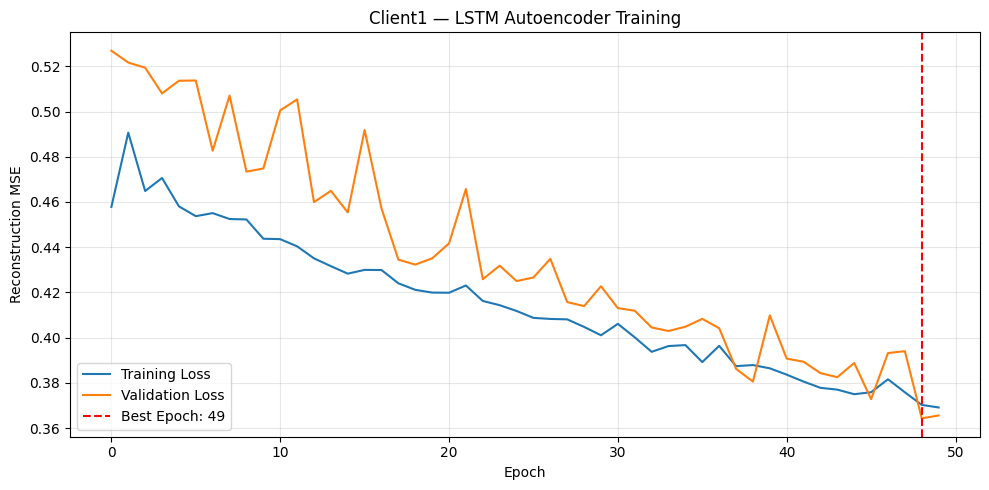


Training Results:
Epochs completed: 50
Best epoch: 49
Final training loss: 0.36912021040916443
Best validation loss: 0.3643093705177307
Saved model: c:\Users\alwyn\OneDrive\Documents\Year 3 - Semester 2\Capstone\Expanded_LSTM_Results\Models\Client1_LSTM_Autoencoder.keras

TRAINING: Client2


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 30, 64)         │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_6 (LSTM)                   │ (None, 30, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 30, 64)         │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 30, 14)         │           910 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66,702 (260.55 KB)

 Trainable params: 66,702 (260.55 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
1708/1708 ━━━━━━━━━━━━━━━━━━━━ 26s 14ms/step - loss: 0.4032 - val_loss: 0.4847
Epoch 2/50
1708/1708 ━━━━━━━━━━━━━━━━━━━━ 23s 14ms/step - loss: 0.4064 - val_loss: 0.4868
Epoch 3/50
1708/1708 ━━━━━━━━━━━━━━━━━━━━ 23s 13ms/step - loss: 0.4171 - val_loss: 0.4808
Epoch 4/50
1708/1708 ━━━━━━━━━━━━━━━━━━━━ 23s 14ms/step - loss: 0.4160 - val_loss: 0.4861
Epoch 5/50
1708/1708 ━━━━━━━━━━━━━━━━━━━━ 23s 13ms/step - loss: 0.4097 - val_loss: 0.4890
Epoch 6/50
1708/1708 ━━━━━━━━━━━━━━━━━━━━ 23s 13ms/step - loss: 0.4105 - val_loss: 0.4828
Epoch 7/50
1708/1708 ━━━━━━━━━━━━━━━━━━━━ 23s 13ms/step - loss: 0.4160 - val_loss: 0.4825
Epoch 8/50
1708/1708 ━━━━━━━━━━━━━━━━━━━━ 23s 13ms/step - loss: 0.4106 - val_loss: 0.4864
Epoch 9/50
1708/1708 ━━━━━━━━━━━━━━━━━━━━ 23s 13ms/step - loss: 0.4071 - val_loss: 0.4820
Epoch 10/50
1708/1708 ━━━━━━━━━━━━━━━━━━━━ 23s 13ms/step - loss: 0.4039 - val_loss: 0.4888


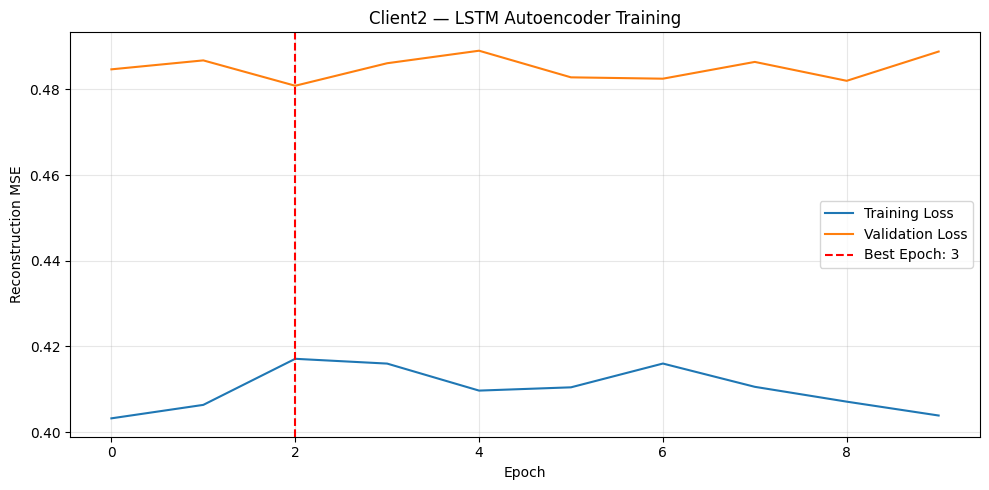


Training Results:
Epochs completed: 10
Best epoch: 3
Final training loss: 0.4038870930671692
Best validation loss: 0.48084893822669983
Saved model: c:\Users\alwyn\OneDrive\Documents\Year 3 - Semester 2\Capstone\Expanded_LSTM_Results\Models\Client2_LSTM_Autoencoder.keras

TRAINING: Client3


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_8 (LSTM)                   │ (None, 30, 64)         │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_9 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_2 (RepeatVector)  │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_10 (LSTM)                  │ (None, 30, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_11 (LSTM)                  │ (None, 30, 64)         │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_2              │ (None, 30, 14)         │           910 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66,702 (260.55 KB)

 Trainable params: 66,702 (260.55 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
1600/1600 ━━━━━━━━━━━━━━━━━━━━ 21s 12ms/step - loss: 0.5432 - val_loss: 0.5952
Epoch 2/50
1600/1600 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - loss: 0.5649 - val_loss: 0.5950
Epoch 3/50
1600/1600 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - loss: 0.5682 - val_loss: 0.5806
Epoch 4/50
1600/1600 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - loss: 0.5729 - val_loss: 0.5794
Epoch 5/50
1600/1600 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - loss: 0.5566 - val_loss: 0.6075
Epoch 6/50
1600/1600 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - loss: 0.5657 - val_loss: 0.6103
Epoch 7/50
1600/1600 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - loss: 0.5687 - val_loss: 0.6029
Epoch 8/50
1600/1600 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - loss: 0.5681 - val_loss: 0.7092
Epoch 9/50
1600/1600 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - loss: 0.5580 - val_loss: 0.5967
Epoch 10/50
1600/1600 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - loss: 0.5681 - val_loss: 0.6041
Epoch 11/50
1600/1600 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - loss: 0.5728 - val_loss: 0.5897


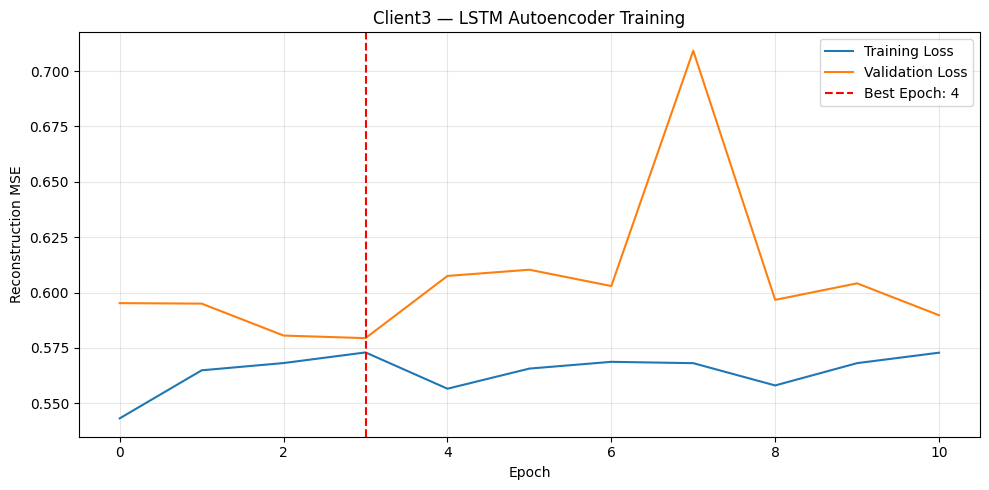


Training Results:
Epochs completed: 11
Best epoch: 4
Final training loss: 0.5728326439857483
Best validation loss: 0.5794039368629456
Saved model: c:\Users\alwyn\OneDrive\Documents\Year 3 - Semester 2\Capstone\Expanded_LSTM_Results\Models\Client3_LSTM_Autoencoder.keras

TRAINING: Switch


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_12 (LSTM)                  │ (None, 30, 64)         │        21,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_13 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_3 (RepeatVector)  │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_14 (LSTM)                  │ (None, 30, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_15 (LSTM)                  │ (None, 30, 64)         │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_3              │ (None, 30, 20)         │         1,300 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 68,628 (268.08 KB)

 Trainable params: 68,628 (268.08 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
2096/2096 ━━━━━━━━━━━━━━━━━━━━ 32s 14ms/step - loss: 0.4933 - val_loss: 0.5868
Epoch 2/50
2096/2096 ━━━━━━━━━━━━━━━━━━━━ 28s 13ms/step - loss: 0.4881 - val_loss: 0.4919
Epoch 3/50
2096/2096 ━━━━━━━━━━━━━━━━━━━━ 28s 13ms/step - loss: 0.4778 - val_loss: 0.4683
Epoch 4/50
2096/2096 ━━━━━━━━━━━━━━━━━━━━ 28s 13ms/step - loss: 0.4808 - val_loss: 0.4759
Epoch 5/50
2096/2096 ━━━━━━━━━━━━━━━━━━━━ 28s 13ms/step - loss: 0.4726 - val_loss: 0.4287
Epoch 6/50
2096/2096 ━━━━━━━━━━━━━━━━━━━━ 28s 13ms/step - loss: 0.4716 - val_loss: 0.4338
Epoch 7/50
2096/2096 ━━━━━━━━━━━━━━━━━━━━ 28s 13ms/step - loss: 0.4677 - val_loss: 0.4269
Epoch 8/50
2096/2096 ━━━━━━━━━━━━━━━━━━━━ 28s 13ms/step - loss: 0.4678 - val_loss: 0.4340
Epoch 9/50
2096/2096 ━━━━━━━━━━━━━━━━━━━━ 28s 13ms/step - loss: 0.4706 - val_loss: 0.4345
Epoch 10/50
2096/2096 ━━━━━━━━━━━━━━━━━━━━ 28s 13ms/step - loss: 0.4657 - val_loss: 0.4224
Epoch 11/50
2096/2096 ━━━━━━━━━━━━━━━━━━━━ 28s 13ms/step - loss: 0.4644 - val_loss: 0.4301
Epoch 12

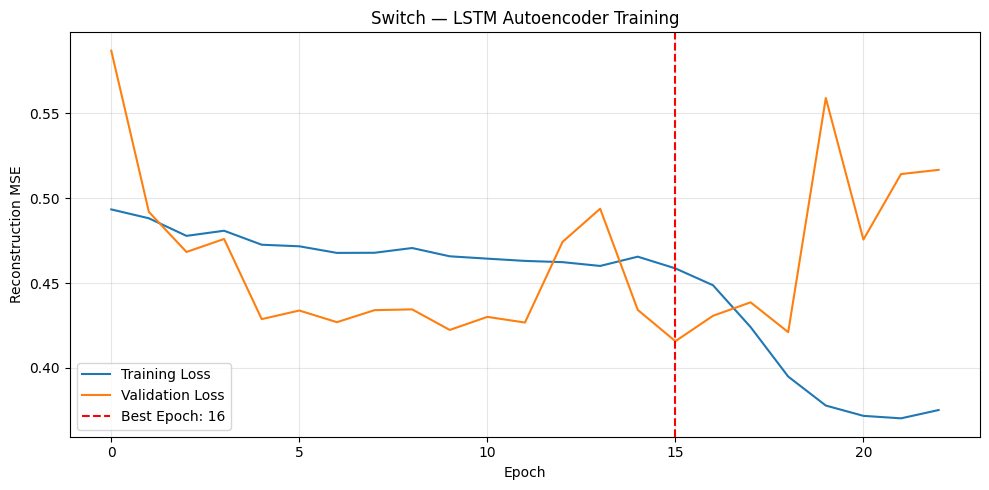


Training Results:
Epochs completed: 23
Best epoch: 16
Final training loss: 0.3752115070819855
Best validation loss: 0.41572996973991394
Saved model: c:\Users\alwyn\OneDrive\Documents\Year 3 - Semester 2\Capstone\Expanded_LSTM_Results\Models\Switch_LSTM_Autoencoder.keras

SECTION 5 COMPLETE
 Device  Features  Training_Sequences  Validation_Sequences  Epochs_Completed  Best_Epoch  Final_Training_Loss  Best_Validation_Loss
Client1        14               54752                 11716                50          49             0.369120              0.364309
Client2        14               54625                 11690                10           3             0.403887              0.480849
Client3        14               51200                 10953                11           4             0.572833              0.579404
 Switch        20               67050                 14347                23          16             0.375212              0.415730


In [5]:
# ============================================================
# SECTION 5 — LSTM AUTOENCODER TRAINING
# ============================================================

models = {}
training_histories = {}
training_summary = []


def build_lstm_autoencoder(
    sequence_length,
    n_features
):

    model = keras.Sequential([

        layers.Input(
            shape=(sequence_length, n_features)
        ),

        layers.LSTM(
            64,
            return_sequences=True
        ),

        layers.LSTM(
            32,
            return_sequences=False
        ),

        layers.RepeatVector(sequence_length),

        layers.LSTM(
            32,
            return_sequences=True
        ),

        layers.LSTM(
            64,
            return_sequences=True
        ),

        layers.TimeDistributed(
            layers.Dense(n_features)
        )
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="mse"
    )

    return model


for device, data in sequence_data.items():

    print("\n" + "=" * 65)
    print("TRAINING:", device)
    print("=" * 65)

    X_train = data["train"]
    X_val = data["val"]

    model = build_lstm_autoencoder(
        SEQUENCE_LENGTH,
        X_train.shape[2]
    )

    model.summary()

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True,
        mode="min"
    )

    history = model.fit(
        X_train,
        X_train,
        validation_data=(X_val, X_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stopping],
        shuffle=False,
        verbose=1
    )

    model_path = (
        MODEL_DIR /
        f"{device}_LSTM_Autoencoder.keras"
    )

    model.save(model_path)

    models[device] = model
    training_histories[device] = history.history

    epochs_completed = len(
        history.history["loss"]
    )

    best_epoch = int(
        np.argmin(history.history["val_loss"]) + 1
    )

    final_train_loss = float(
        history.history["loss"][-1]
    )

    best_val_loss = float(
        np.min(history.history["val_loss"])
    )

    training_summary.append({
        "Device": device,
        "Features": X_train.shape[2],
        "Training_Sequences": len(X_train),
        "Validation_Sequences": len(X_val),
        "Epochs_Completed": epochs_completed,
        "Best_Epoch": best_epoch,
        "Final_Training_Loss": final_train_loss,
        "Best_Validation_Loss": best_val_loss
    })

    history_df = pd.DataFrame(history.history)

    history_df.insert(
        0,
        "epoch",
        np.arange(1, epochs_completed + 1)
    )

    history_df.to_csv(
        RESULTS_DIR /
        f"{device}_Training_History.csv",
        index=False
    )

    plt.figure(figsize=(10, 5))

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.axvline(
        best_epoch - 1,
        linestyle="--",
        color="red",
        label=f"Best Epoch: {best_epoch}"
    )

    plt.title(
        f"{device} — LSTM Autoencoder Training"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Reconstruction MSE")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        PLOTS_DIR / f"{device}_Training_Loss.png",
        dpi=150
    )

    plt.show()
    plt.close()

    print("\nTraining Results:")
    print("Epochs completed:", epochs_completed)
    print("Best epoch:", best_epoch)
    print("Final training loss:", final_train_loss)
    print("Best validation loss:", best_val_loss)
    print("Saved model:", model_path)


training_summary_df = pd.DataFrame(
    training_summary
)

training_summary_df.to_csv(
    OUTPUT_DIR / "Training_Summary.csv",
    index=False
)

print("\n" + "=" * 65)
print("SECTION 5 COMPLETE")
print("=" * 65)

print(training_summary_df.to_string(index=False))


Section 6 - Reconstruction Error and Anomaly Detection


ANOMALY DETECTION: Client1
Calculating training errors...
Calculating validation errors...
Calculating test errors...


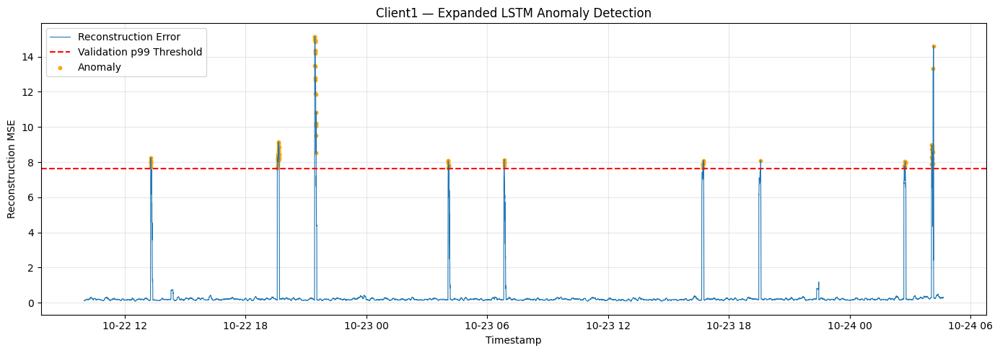

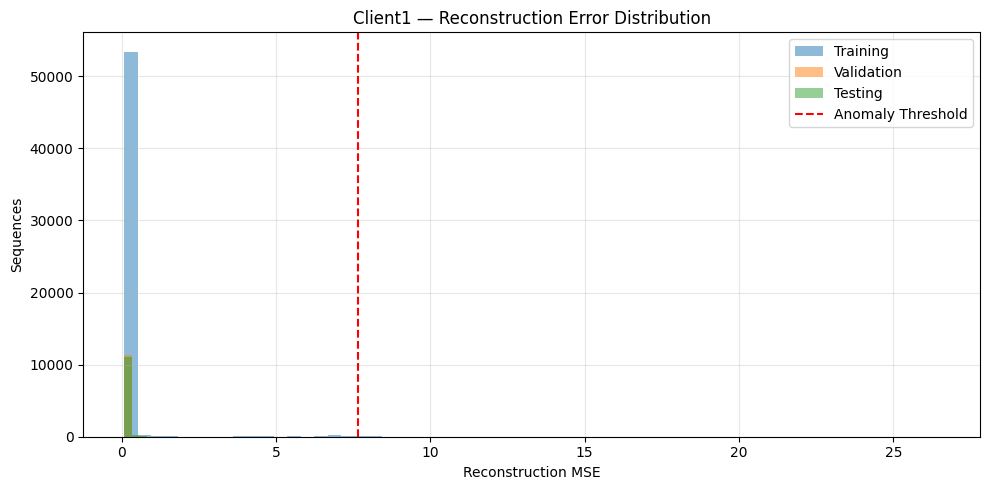


Anomaly Detection Results:
Features: 14
Test sequences: 11717
Threshold: 7.648778
Anomalous sequences: 90
Anomaly rate: 0.77%
Maximum test error: 15.14383271422296

Top unusual metrics:
         Metric  Mean_Test_Error  Mean_Anomaly_Error  Dominant_Anomaly_Count
        cpu_pct         0.861304           42.329441                      55
  cpu_voltage_v         0.509029           32.604460                      35
     latency_ms         0.819193            1.048821                       0
packet_loss_pct         0.000002            0.000036                       0
 disk_usage_pct         0.010438            0.372770                       0

ANOMALY DETECTION: Client2
Calculating training errors...
Calculating validation errors...
Calculating test errors...


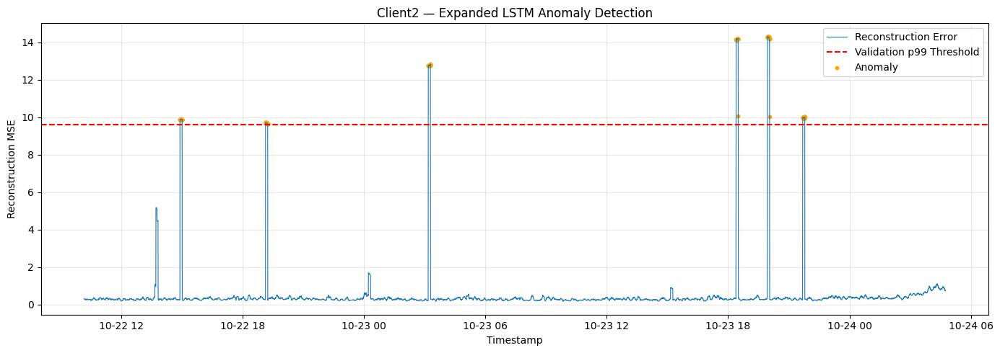

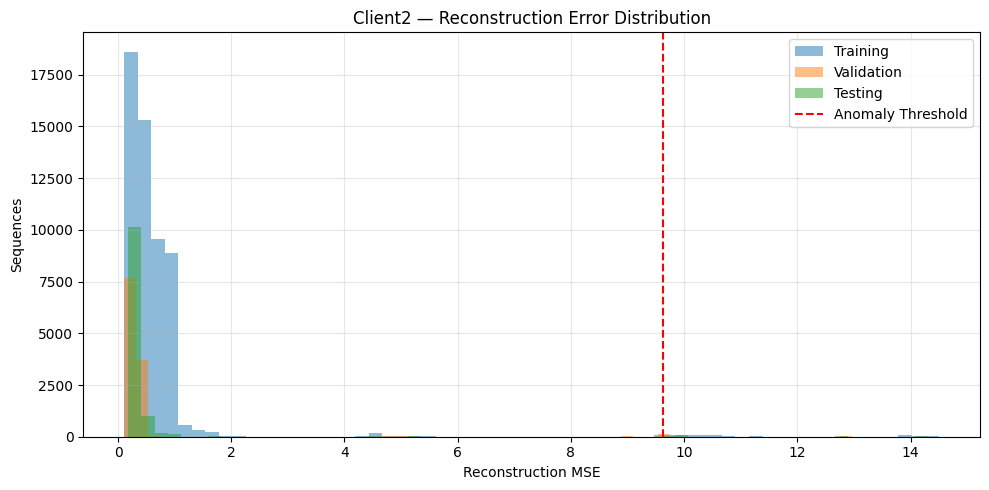


Anomaly Detection Results:
Features: 14
Test sequences: 11690
Threshold: 9.618945
Anomalous sequences: 179
Anomaly rate: 1.53%
Maximum test error: 14.313687474337259

Top unusual metrics:
         Metric  Mean_Test_Error  Mean_Anomaly_Error  Dominant_Anomaly_Count
        cpu_pct         1.155248           68.053043                     179
  temperature_c         0.580937            0.534915                       0
     latency_ms         1.084212            0.927840                       0
packet_loss_pct         0.000039            0.000040                       0
 disk_usage_pct         1.288657            1.150894                       0

ANOMALY DETECTION: Client3
Calculating training errors...
Calculating validation errors...
Calculating test errors...


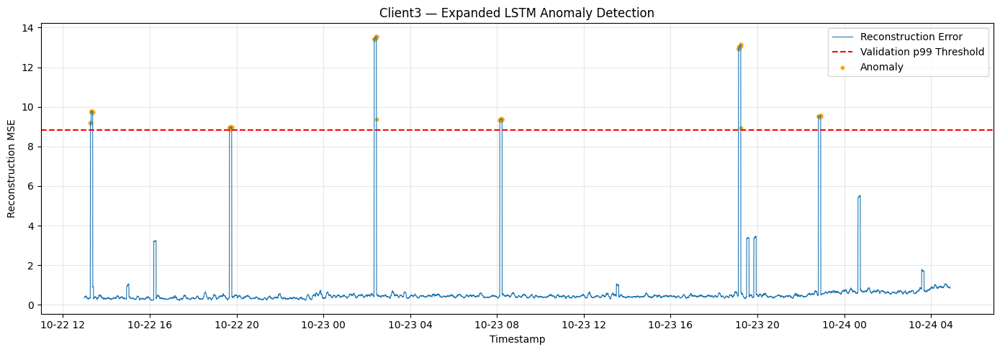

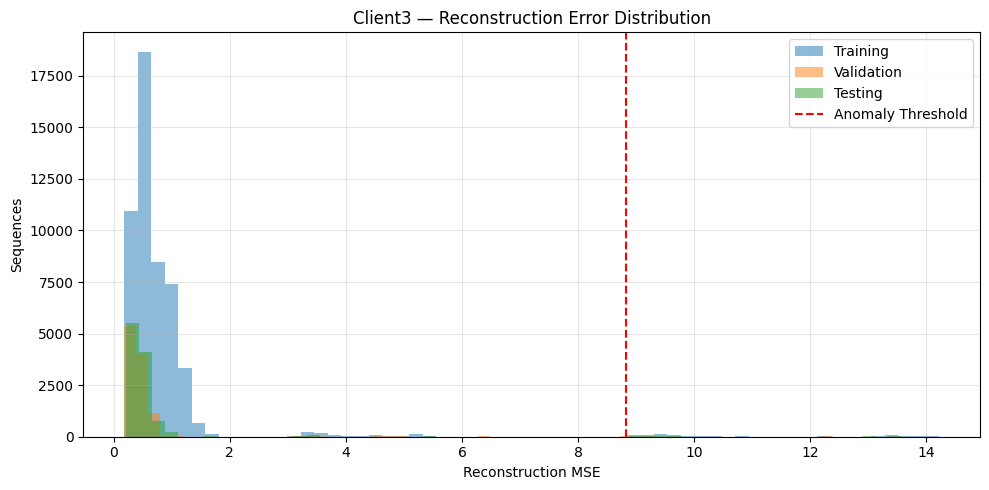


Anomaly Detection Results:
Features: 14
Test sequences: 10954
Threshold: 8.827382
Anomalous sequences: 178
Anomaly rate: 1.62%
Maximum test error: 13.553773264888463

Top unusual metrics:
         Metric  Mean_Test_Error  Mean_Anomaly_Error  Dominant_Anomaly_Count
        cpu_pct         1.125902           61.405849                     120
  cpu_voltage_v         0.891656           26.462759                      58
     latency_ms         1.062057            1.019774                       0
packet_loss_pct         0.000073            0.000073                       0
 disk_usage_pct         1.423004            1.354483                       0

ANOMALY DETECTION: Switch
Calculating training errors...
Calculating validation errors...
Calculating test errors...


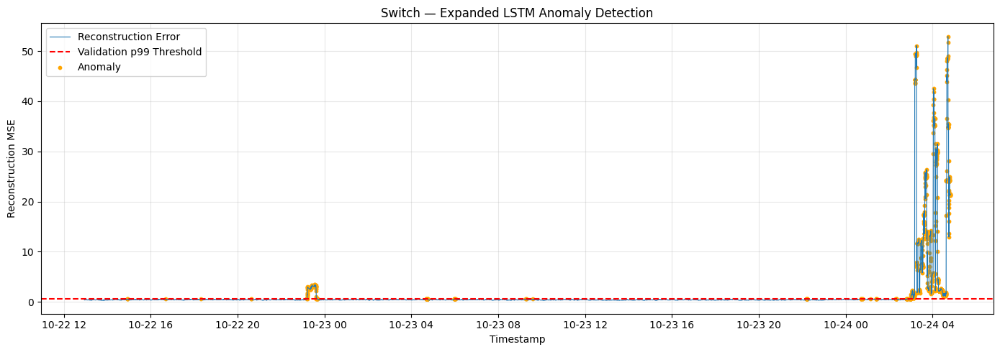

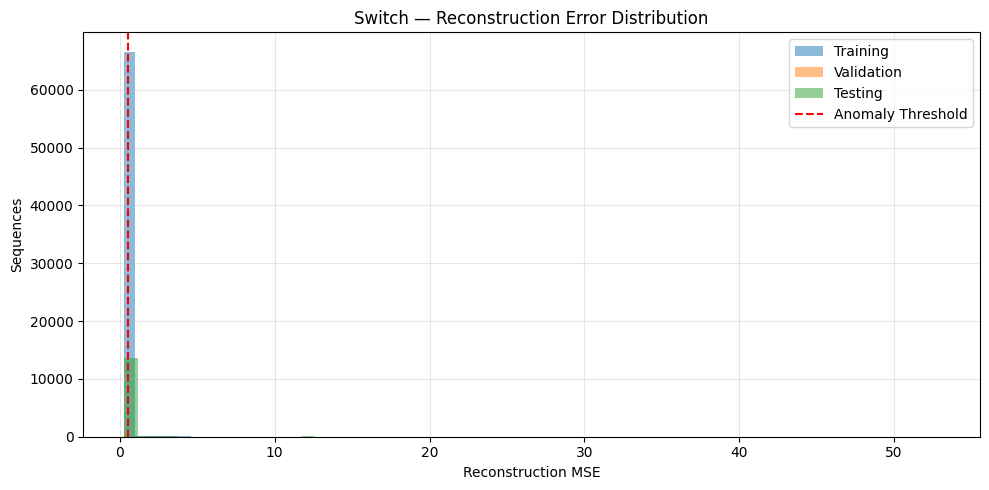


Anomaly Detection Results:
Features: 20
Test sequences: 14289
Threshold: 0.552553
Anomalous sequences: 878
Anomaly rate: 6.14%
Maximum test error: 52.92756023296746

Top unusual metrics:
                    Metric  Mean_Test_Error  Mean_Anomaly_Error  Dominant_Anomaly_Count
 interface_4_in_bytes_rate        10.644974          173.220363                     402
interface_4_out_bytes_rate         2.029135           20.470468                     287
interface_1_out_bytes_rate         1.161722            5.156730                      67
interface_3_out_bytes_rate         0.993253            1.953914                      55
               free_memory         0.692427            1.305597                      29

SECTION 6 COMPLETE
 Device  Features  Test_Sequences  Anomalous_Sequences  Anomaly_Rate_Pct  Threshold  Train_Mean_Error  Validation_Mean_Error  Test_Mean_Error  Test_Max_Error  Test_P99_Error
Client1        14           11717                   90          0.768115   7.648778       

In [6]:
# ============================================================
# SECTION 6 — ANOMALY DETECTION
# ============================================================

anomaly_results = {}
anomaly_thresholds = {}
anomaly_summary = []


def calculate_reconstruction_errors(
    model,
    X,
    batch_size=256
):

    n_sequences = len(X)
    n_features = X.shape[2]

    overall_errors = np.empty(
        n_sequences,
        dtype=np.float64
    )

    metric_errors = np.empty(
        (n_sequences, n_features),
        dtype=np.float64
    )

    for start in range(
        0, n_sequences, batch_size
    ):

        end = min(
            start + batch_size,
            n_sequences
        )

        batch = X[start:end]

        reconstructed = model.predict(
            batch,
            batch_size=batch_size,
            verbose=0
        )

        squared_error = (
            batch.astype(np.float64)
            - reconstructed.astype(np.float64)
        ) ** 2

        overall_errors[start:end] = (
            squared_error.mean(axis=(1, 2))
        )

        metric_errors[start:end] = (
            squared_error.mean(axis=1)
        )

    if (
        not np.isfinite(overall_errors).all()
        or not np.isfinite(metric_errors).all()
    ):
        raise ValueError(
            "Invalid reconstruction errors."
        )

    return overall_errors, metric_errors


for device, data in sequence_data.items():

    print("\n" + "=" * 65)
    print("ANOMALY DETECTION:", device)
    print("=" * 65)

    metrics = list(data["metrics"])

    model = (
        models[device]
        if device in models
        else keras.models.load_model(
            MODEL_DIR /
            f"{device}_LSTM_Autoencoder.keras"
        )
    )

    X_train = data["train"]
    X_val = data["val"]
    X_test = data["test"]

    test_timestamps = pd.DatetimeIndex(
        data["test_timestamps"]
    )

    print("Calculating training errors...")

    train_errors, train_metric_errors = (
        calculate_reconstruction_errors(
            model,
            X_train,
            PREDICTION_BATCH_SIZE
        )
    )

    print("Calculating validation errors...")

    val_errors, val_metric_errors = (
        calculate_reconstruction_errors(
            model,
            X_val,
            PREDICTION_BATCH_SIZE
        )
    )

    print("Calculating test errors...")

    test_errors, test_metric_errors = (
        calculate_reconstruction_errors(
            model,
            X_test,
            PREDICTION_BATCH_SIZE
        )
    )

    threshold = float(
        np.percentile(
            val_errors,
            ANOMALY_PERCENTILE
        )
    )

    anomaly_thresholds[device] = threshold

    is_anomaly = test_errors > threshold

    anomaly_count = int(is_anomaly.sum())

    anomaly_rate = (
        anomaly_count / len(test_errors) * 100
    )

    severity_ratio = (
        test_errors / threshold
        if threshold > 0
        else np.full(len(test_errors), np.nan)
    )

    unusual_indices = (
        test_metric_errors.argmax(axis=1)
    )

    unusual_metrics = [
        metrics[index]
        for index in unusual_indices
    ]

    unusual_metric_errors = (
        test_metric_errors[
            np.arange(len(test_errors)),
            unusual_indices
        ]
    )

    # --------------------------------------------------------
    # Save per-sequence results
    # --------------------------------------------------------

    results_df = pd.DataFrame({
        "timestamp": test_timestamps,
        "reconstruction_error": test_errors,
        "threshold": threshold,
        "is_anomaly": is_anomaly,
        "severity_ratio": severity_ratio,
        "most_unusual_metric": unusual_metrics,
        "most_unusual_metric_error":
            unusual_metric_errors
    })

    for i, metric in enumerate(metrics):
        results_df[f"{metric}_error"] = (
            test_metric_errors[:, i]
        )

    results_df = (
        results_df.sort_values("timestamp")
        .reset_index(drop=True)
    )

    results_df.to_csv(
        RESULTS_DIR /
        f"{device}_Anomaly_Results.csv",
        index=False
    )

    anomaly_results[device] = results_df

    # --------------------------------------------------------
    # Save error distribution statistics
    # --------------------------------------------------------

    distributions = []

    for label, errors in [
        ("Train", train_errors),
        ("Validation", val_errors),
        ("Test", test_errors)
    ]:

        distributions.append({
            "Dataset": label,
            "Mean_Error": np.mean(errors),
            "Median_Error": np.median(errors),
            "P95_Error": np.percentile(errors, 95),
            "P99_Error": np.percentile(errors, 99),
            "Max_Error": np.max(errors)
        })

    pd.DataFrame(distributions).to_csv(
        RESULTS_DIR /
        f"{device}_Error_Distribution.csv",
        index=False
    )

    # --------------------------------------------------------
    # Metric reconstruction-error analysis
    # --------------------------------------------------------

    metric_summary = []

    for i, metric in enumerate(metrics):

        anomalous_errors = (
            test_metric_errors[is_anomaly, i]
        )

        dominant_count = int(
            np.sum(
                np.asarray(unusual_metrics)[is_anomaly]
                == metric
            )
        )

        metric_summary.append({
            "Metric": metric,
            "Mean_Test_Error": float(
                test_metric_errors[:, i].mean()
            ),
            "Mean_Anomaly_Error": (
                float(anomalous_errors.mean())
                if len(anomalous_errors)
                else np.nan
            ),
            "Dominant_Anomaly_Count":
                dominant_count
        })

    metric_df = pd.DataFrame(
        metric_summary
    ).sort_values(
        "Dominant_Anomaly_Count",
        ascending=False
    )

    metric_df.to_csv(
        RESULTS_DIR /
        f"{device}_Metric_Analysis.csv",
        index=False
    )

    anomaly_summary.append({
        "Device": device,
        "Features": len(metrics),
        "Test_Sequences": len(test_errors),
        "Anomalous_Sequences": anomaly_count,
        "Anomaly_Rate_Pct": anomaly_rate,
        "Threshold": threshold,
        "Train_Mean_Error": train_errors.mean(),
        "Validation_Mean_Error": val_errors.mean(),
        "Test_Mean_Error": test_errors.mean(),
        "Test_Max_Error": test_errors.max(),
        "Test_P99_Error": np.percentile(
            test_errors, 99
        )
    })

    # --------------------------------------------------------
    # Anomaly detection time-series plot
    # --------------------------------------------------------

    plt.figure(figsize=(14, 5))

    plt.plot(
        test_timestamps,
        test_errors,
        linewidth=0.8,
        label="Reconstruction Error"
    )

    plt.axhline(
        threshold,
        linestyle="--",
        color="red",
        label="Validation p99 Threshold"
    )

    plt.scatter(
        test_timestamps[is_anomaly],
        test_errors[is_anomaly],
        s=10,
        color="orange",
        label="Anomaly"
    )

    plt.title(
        f"{device} — Expanded LSTM Anomaly Detection"
    )

    plt.xlabel("Timestamp")
    plt.ylabel("Reconstruction MSE")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        PLOTS_DIR /
        f"{device}_Anomaly_Detection.png",
        dpi=150
    )

    plt.show()
    plt.close()

    # --------------------------------------------------------
    # Distribution plot
    # --------------------------------------------------------

    plt.figure(figsize=(10, 5))

    plt.hist(
        train_errors,
        bins=60,
        alpha=0.5,
        label="Training"
    )

    plt.hist(
        val_errors,
        bins=60,
        alpha=0.5,
        label="Validation"
    )

    plt.hist(
        test_errors,
        bins=60,
        alpha=0.5,
        label="Testing"
    )

    plt.axvline(
        threshold,
        color="red",
        linestyle="--",
        label="Anomaly Threshold"
    )

    plt.title(
        f"{device} — Reconstruction Error Distribution"
    )

    plt.xlabel("Reconstruction MSE")
    plt.ylabel("Sequences")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        PLOTS_DIR /
        f"{device}_Error_Distribution.png",
        dpi=150
    )

    plt.show()
    plt.close()

    print("\nAnomaly Detection Results:")
    print("Features:", len(metrics))
    print("Test sequences:", len(test_errors))
    print("Threshold:", f"{threshold:.6f}")
    print("Anomalous sequences:", anomaly_count)
    print("Anomaly rate:", f"{anomaly_rate:.2f}%")
    print("Maximum test error:", test_errors.max())

    print("\nTop unusual metrics:")
    print(metric_df.head(5).to_string(index=False))

    del (
        train_errors, val_errors, test_errors,
        train_metric_errors, val_metric_errors,
        test_metric_errors
    )

    gc.collect()


joblib.dump(
    anomaly_thresholds,
    MODEL_DIR / "Expanded_Anomaly_Thresholds.joblib"
)

anomaly_summary_df = pd.DataFrame(
    anomaly_summary
)

anomaly_summary_df.to_csv(
    OUTPUT_DIR / "Anomaly_Summary.csv",
    index=False
)

print("\n" + "=" * 65)
print("SECTION 6 COMPLETE")
print("=" * 65)
print(anomaly_summary_df.to_string(index=False))


Section 7 - Anomaly Event Grouping


ANOMALY EVENTS: Client1

Top events:
 device  event_id                       start_time                         end_time  duration_seconds  duration_minutes  anomalous_sequences  peak_reconstruction_error  mean_reconstruction_error  threshold  peak_threshold_ratio dominant_metric  dominant_metric_count   peak_metric                                       top_3_metrics
Client1         3 2026-10-22 21:25:56.052719+00:00 2026-10-22 21:30:18.238460+00:00        262.185741          4.369762                   21                  15.143833                  12.773275   7.648778              1.979902         cpu_pct                     16 cpu_voltage_v            cpu_pct, cpu_voltage_v, est_power_draw_w
Client1        15 2026-10-24 04:09:19.998821+00:00 2026-10-24 04:09:19.998821+00:00          0.000000          0.000000                    1                  14.608828                  14.608828   7.648778              1.909956   cpu_voltage_v                      1 cpu_voltage_v         cpu_vol

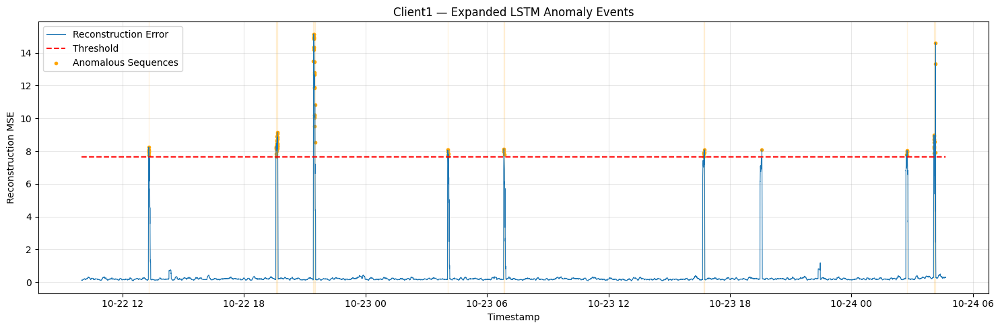


ANOMALY EVENTS: Client2

Top events:
 device  event_id                       start_time                         end_time  duration_seconds  duration_minutes  anomalous_sequences  peak_reconstruction_error  mean_reconstruction_error  threshold  peak_threshold_ratio dominant_metric  dominant_metric_count peak_metric                             top_3_metrics
Client2         5 2026-10-23 19:56:40.696407+00:00 2026-10-23 20:03:00.775212+00:00        380.078805          6.334647                   30                  14.313687                  14.127010   9.618945              1.488072         cpu_pct                     30     cpu_pct  cpu_pct, est_power_draw_w, cpu_clock_mhz
Client2         4 2026-10-23 18:23:39.488371+00:00 2026-10-23 18:29:59.495758+00:00        380.007387          6.333456                   30                  14.199208                  14.032418   9.618945              1.476171         cpu_pct                     30     cpu_pct  cpu_pct, est_power_draw_w, cpu_clock_mhz

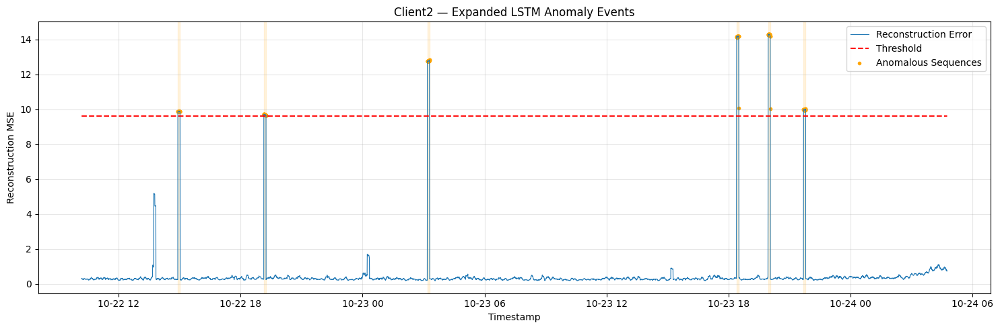


ANOMALY EVENTS: Client3

Top events:
 device  event_id                       start_time                         end_time  duration_seconds  duration_minutes  anomalous_sequences  peak_reconstruction_error  mean_reconstruction_error  threshold  peak_threshold_ratio dominant_metric  dominant_metric_count   peak_metric                                    top_3_metrics
Client3         3 2026-10-23 02:20:33.570578+00:00 2026-10-23 02:26:53.562065+00:00        379.991487          6.333191                   30                  13.553773                  13.337478   8.827382              1.535424         cpu_pct                     30       cpu_pct         cpu_pct, est_power_draw_w, cpu_voltage_v
Client3         5 2026-10-23 19:07:54.916215+00:00 2026-10-23 19:14:14.891340+00:00        379.975125          6.332919                   30                  13.154294                  12.899012   8.827382              1.490169         cpu_pct                     30       cpu_pct         cpu_pct, est_

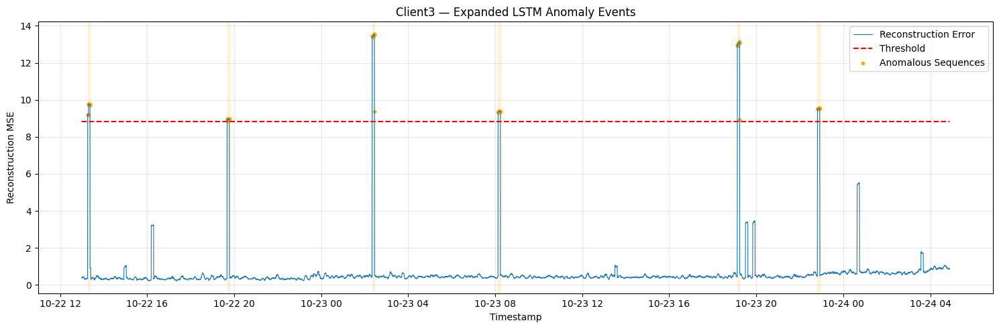


ANOMALY EVENTS: Switch

Top events:
device  event_id                start_time                  end_time  duration_seconds  duration_minutes  anomalous_sequences  peak_reconstruction_error  mean_reconstruction_error  threshold  peak_threshold_ratio            dominant_metric  dominant_metric_count                peak_metric                                                                      top_3_metrics
Switch        26 2026-10-24 02:59:10+00:00 2026-10-24 04:48:50+00:00            6580.0        109.666667                  659                  52.927560                  13.512931   0.552553             95.787358  interface_4_in_bytes_rate                    401  interface_4_in_bytes_rate  interface_4_in_bytes_rate, interface_4_out_bytes_rate, interface_1_out_bytes_rate
Switch         8 2026-10-22 23:31:11+00:00 2026-10-22 23:40:20+00:00             549.0          9.150000                   56                   3.489526                   2.299257   0.552553              6.315282 inte

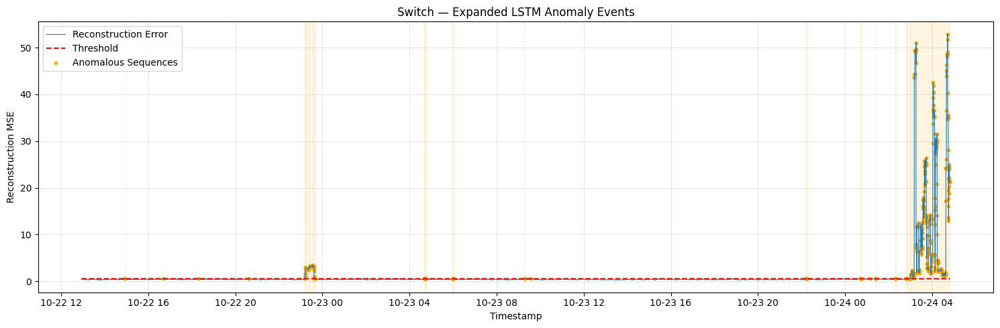


Top 15 Strongest Events Across All Devices:
 device  event_id                       start_time                         end_time  duration_seconds  duration_minutes  anomalous_sequences  peak_reconstruction_error  mean_reconstruction_error  threshold  peak_threshold_ratio            dominant_metric  dominant_metric_count                peak_metric                                                                      top_3_metrics
 Switch        26        2026-10-24 02:59:10+00:00        2026-10-24 04:48:50+00:00       6580.000000        109.666667                  659                  52.927560                  13.512931   0.552553             95.787358  interface_4_in_bytes_rate                    401  interface_4_in_bytes_rate  interface_4_in_bytes_rate, interface_4_out_bytes_rate, interface_1_out_bytes_rate
 Switch         8        2026-10-22 23:31:11+00:00        2026-10-22 23:40:20+00:00        549.000000          9.150000                   56                   3.489526            

In [7]:
# ============================================================
# SECTION 7 — ANOMALY EVENT GROUPING
# ============================================================

EVENT_GAP_MULTIPLIER = 1

anomaly_events = {}
event_summary = []
all_events = []


def group_anomaly_events(
    results,
    metrics,
    max_gap_seconds
):

    results = (
        results.copy()
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    results["timestamp"] = pd.to_datetime(
        results["timestamp"],
        utc=True
    )

    if results["is_anomaly"].dtype == object:

        results["is_anomaly"] = (
            results["is_anomaly"]
            .astype(str)
            .str.lower()
            .isin(["true", "1", "yes"])
        )

    else:
        results["is_anomaly"] = (
            results["is_anomaly"].astype(bool)
        )

    anomalies = (
        results.loc[results["is_anomaly"]]
        .copy()
        .reset_index(drop=True)
    )

    if anomalies.empty:
        return pd.DataFrame(), anomalies

    anomalies["time_gap_seconds"] = (
        anomalies["timestamp"]
        .diff()
        .dt.total_seconds()
    )

    allowed_gap = (
        max_gap_seconds * EVENT_GAP_MULTIPLIER
    )

    new_event = (
        anomalies["time_gap_seconds"].isna()
        | (anomalies["time_gap_seconds"] > allowed_gap)
    )

    anomalies["event_id"] = (
        new_event.cumsum().astype(int)
    )

    records = []

    for event_id, group in anomalies.groupby("event_id"):

        group = group.sort_values("timestamp")

        start = group["timestamp"].iloc[0]
        end = group["timestamp"].iloc[-1]

        duration = (end - start).total_seconds()

        peak_index = (
            group["reconstruction_error"].idxmax()
        )

        peak_row = group.loc[peak_index]

        peak_error = float(
            peak_row["reconstruction_error"]
        )

        threshold = float(
            peak_row["threshold"]
        )

        dominant_counts = (
            group["most_unusual_metric"]
            .value_counts()
        )

        dominant_metric = (
            dominant_counts.index[0]
            if len(dominant_counts)
            else "Unknown"
        )

        metric_means = {}

        for metric in metrics:
            column = f"{metric}_error"

            if column in group.columns:
                metric_means[metric] = float(
                    group[column].mean()
                )

        top_metrics = sorted(
            metric_means,
            key=metric_means.get,
            reverse=True
        )[:3]

        records.append({
            "event_id": int(event_id),
            "start_time": start,
            "end_time": end,
            "duration_seconds": duration,
            "duration_minutes": duration / 60,
            "anomalous_sequences": len(group),
            "peak_reconstruction_error": peak_error,
            "mean_reconstruction_error": float(
                group["reconstruction_error"].mean()
            ),
            "threshold": threshold,
            "peak_threshold_ratio": (
                peak_error / threshold
                if threshold > 0 else np.nan
            ),
            "dominant_metric": dominant_metric,
            "dominant_metric_count": int(
                dominant_counts.iloc[0]
            ),
            "peak_metric": str(
                peak_row["most_unusual_metric"]
            ),
            "top_3_metrics": ", ".join(top_metrics)
        })

    return pd.DataFrame(records), anomalies


for device in DEVICES:

    print("\n" + "=" * 65)
    print("ANOMALY EVENTS:", device)
    print("=" * 65)

    results = anomaly_results[device].copy()

    events, anomalies = group_anomaly_events(
        results,
        device_metrics[device],
        MAX_GAP_SECONDS[device]
    )

    if not events.empty:

        events.insert(0, "device", device)
        anomalies.insert(0, "device", device)

        events.to_csv(
            EVENT_DIR /
            f"{device}_Anomaly_Events.csv",
            index=False
        )

        anomalies.to_csv(
            EVENT_DIR /
            f"{device}_Grouped_Anomalies.csv",
            index=False
        )

        anomaly_events[device] = events
        all_events.append(events)

        event_summary.append({
            "Device": device,
            "Features": len(device_metrics[device]),
            "Test_Sequences": len(results),
            "Anomalous_Sequences": len(anomalies),
            "Anomaly_Events": len(events),
            "Longest_Event_Minutes":
                events["duration_minutes"].max(),
            "Maximum_Peak_Error":
                events["peak_reconstruction_error"].max(),
            "Maximum_Peak_Threshold_Ratio":
                events["peak_threshold_ratio"].max()
        })

        strongest = (
            events.sort_values(
                "peak_threshold_ratio",
                ascending=False
            ).head(10)
        )

        print("\nTop events:")
        print(strongest.to_string(index=False))

        # Plot event periods
        fig, ax = plt.subplots(figsize=(15, 5))

        ax.plot(
            results["timestamp"],
            results["reconstruction_error"],
            linewidth=0.8,
            label="Reconstruction Error"
        )

        ax.plot(
            results["timestamp"],
            results["threshold"],
            color="red",
            linestyle="--",
            label="Threshold"
        )

        ax.scatter(
            anomalies["timestamp"],
            anomalies["reconstruction_error"],
            color="orange",
            s=9,
            label="Anomalous Sequences"
        )

        for _, event in events.iterrows():
            if event["start_time"] != event["end_time"]:
                ax.axvspan(
                    event["start_time"],
                    event["end_time"],
                    color="orange",
                    alpha=0.12
                )

        ax.set_title(
            f"{device} — Expanded LSTM Anomaly Events"
        )

        ax.set_xlabel("Timestamp")
        ax.set_ylabel("Reconstruction MSE")
        ax.grid(alpha=0.3)
        ax.legend()
        plt.tight_layout()

        plt.savefig(
            PLOTS_DIR /
            f"{device}_Anomaly_Events.png",
            dpi=150
        )

        plt.show()
        plt.close()

    else:

        anomaly_events[device] = pd.DataFrame()

        event_summary.append({
            "Device": device,
            "Features": len(device_metrics[device]),
            "Test_Sequences": len(results),
            "Anomalous_Sequences": 0,
            "Anomaly_Events": 0,
            "Longest_Event_Minutes": 0,
            "Maximum_Peak_Error": np.nan,
            "Maximum_Peak_Threshold_Ratio": np.nan
        })

        print("No anomaly events.")


event_summary_df = pd.DataFrame(event_summary)

event_summary_df.to_csv(
    OUTPUT_DIR / "Event_Summary.csv",
    index=False
)

if all_events:

    combined_events_df = pd.concat(
        all_events,
        ignore_index=True
    )

    combined_events_df.to_csv(
        EVENT_DIR / "All_Anomaly_Events.csv",
        index=False
    )

    print("\nTop 15 Strongest Events Across All Devices:")

    print(
        combined_events_df.sort_values(
            "peak_threshold_ratio",
            ascending=False
        ).head(15).to_string(index=False)
    )

print("\n" + "=" * 65)
print("SECTION 7 COMPLETE")
print("=" * 65)
print(event_summary_df.to_string(index=False))


Section 8 - Telemetry Validation


TELEMETRY VALIDATION: Client1

Client1 Event 3
          Metric  Baseline_Mean  Event_Mean  Event_Max  Percentage_Change
         cpu_pct       0.103650     0.16000      3.100          54.366197
   cpu_voltage_v       0.860000     0.86132      0.926           0.153488
est_power_draw_w       2.700365     2.70220      2.810           0.067955


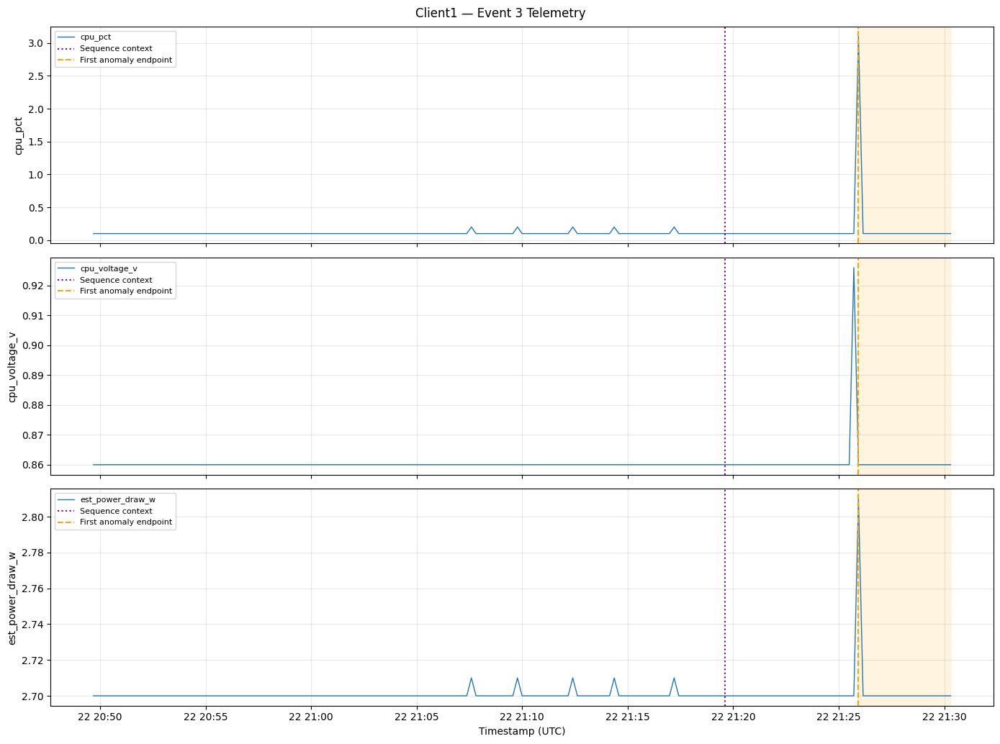


Client1 Event 15
       Metric  Baseline_Mean  Event_Mean  Event_Max  Percentage_Change
temperature_c      36.494891   36.423333     37.400          -0.196075
cpu_voltage_v       0.860000    0.862200      0.926           0.255814
cpu_clock_mhz     603.075182  650.180000   1800.500           7.810770


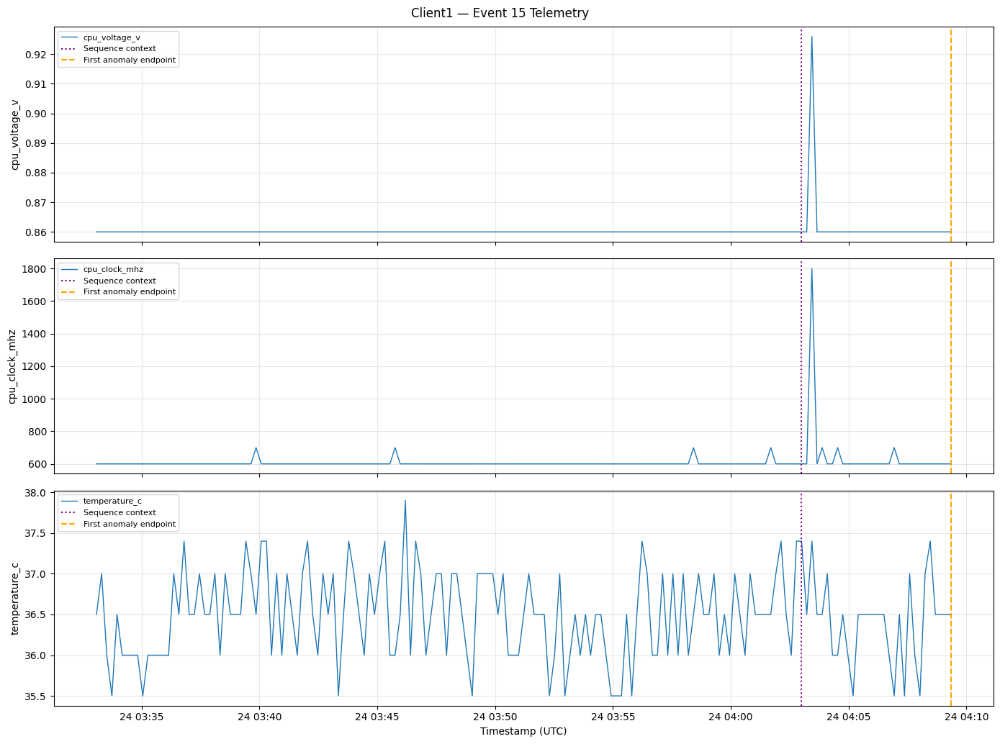


Client1 Event 14
       Metric  Baseline_Mean  Event_Mean  Event_Max  Percentage_Change
temperature_c      36.474453   36.483871     37.400           0.025822
cpu_voltage_v       0.860000    0.862129      0.926           0.247562
cpu_clock_mhz     603.075182  648.564516   1800.500           7.542896


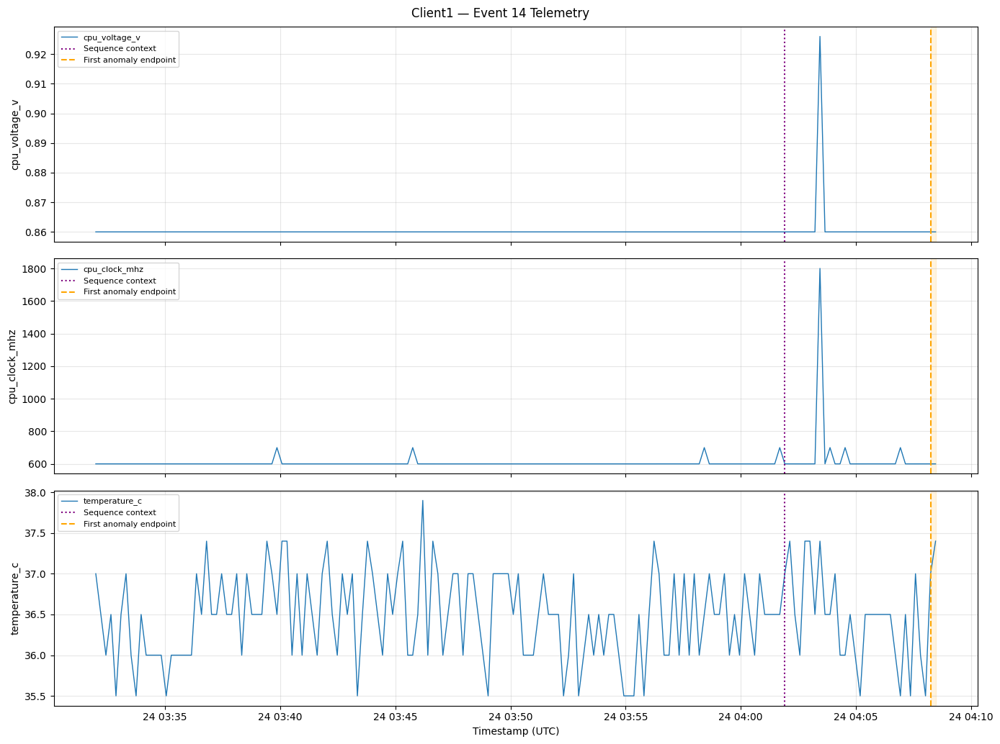


Client1 Event 2
          Metric  Baseline_Mean  Event_Mean  Event_Max  Percentage_Change
         cpu_pct       0.102190    0.157143      3.200          53.775510
      latency_ms       0.484861    0.497179      0.592           2.540367
est_power_draw_w       2.700365    2.702321      2.820           0.072452


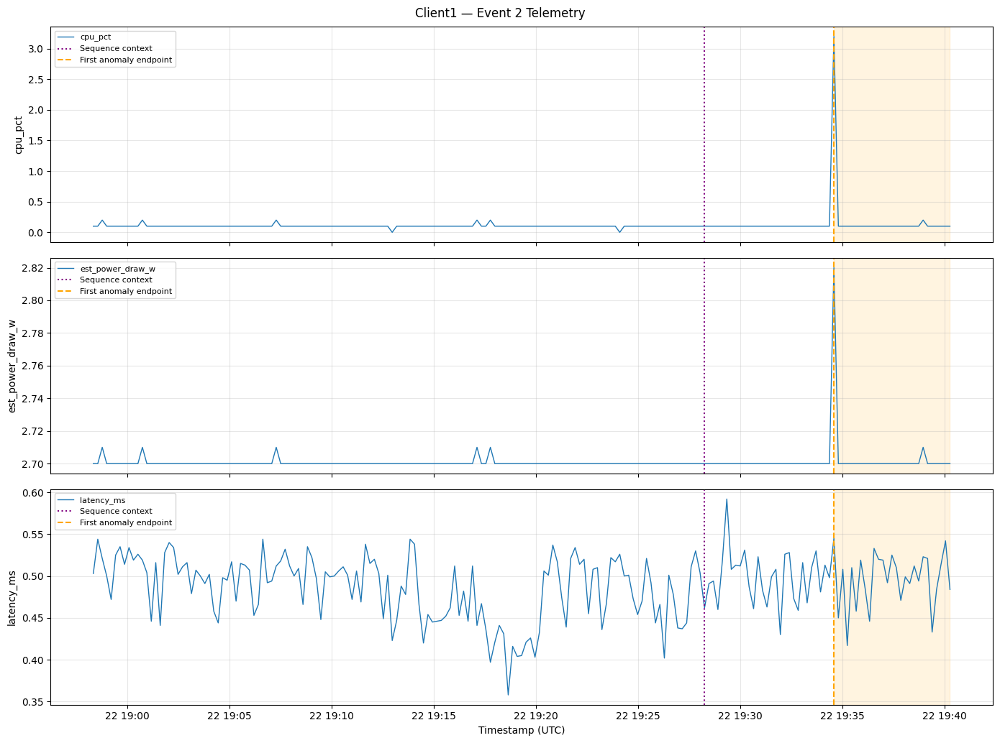


Client1 Event 12
       Metric  Baseline_Mean  Event_Mean  Event_Max  Percentage_Change
temperature_c      36.394161   36.541026     37.400           0.403540
cpu_voltage_v       0.860000    0.861692      0.926           0.196780
cpu_clock_mhz     601.618248  641.189744   1800.500           6.577509


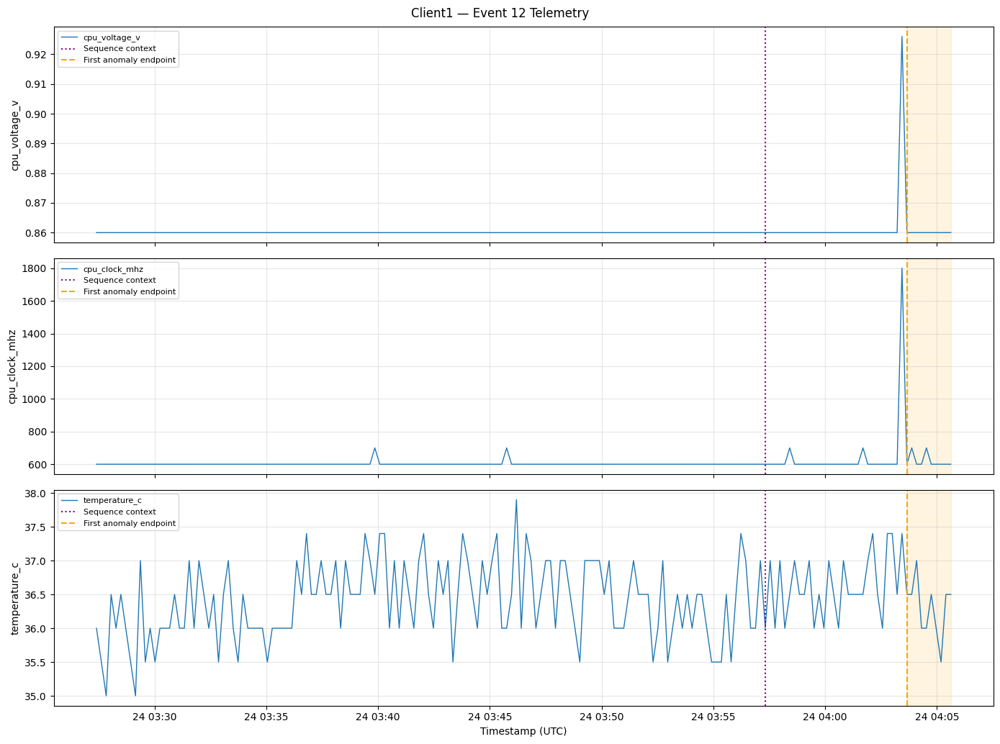


TELEMETRY VALIDATION: Client2

Client2 Event 5
          Metric  Baseline_Mean  Event_Mean  Event_Max  Percentage_Change
         cpu_pct       0.098540    0.155932       3.30          58.242310
   cpu_clock_mhz     601.621898  618.798305    1500.30           2.855017
est_power_draw_w       2.700219    2.702203       2.82           0.073491


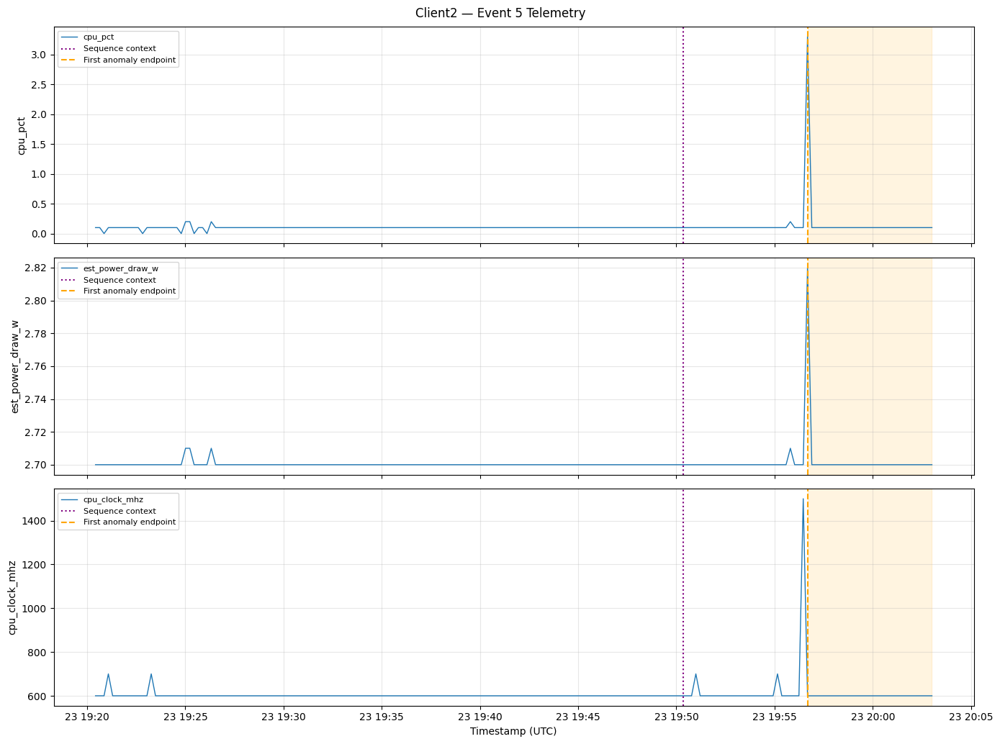


Client2 Event 4
          Metric  Baseline_Mean  Event_Mean  Event_Max  Percentage_Change
         cpu_pct       0.097810    0.152542       3.30          55.957501
   cpu_clock_mhz     600.146715  615.416949    1500.30           2.544417
est_power_draw_w       2.700073    2.702373       2.82           0.085179


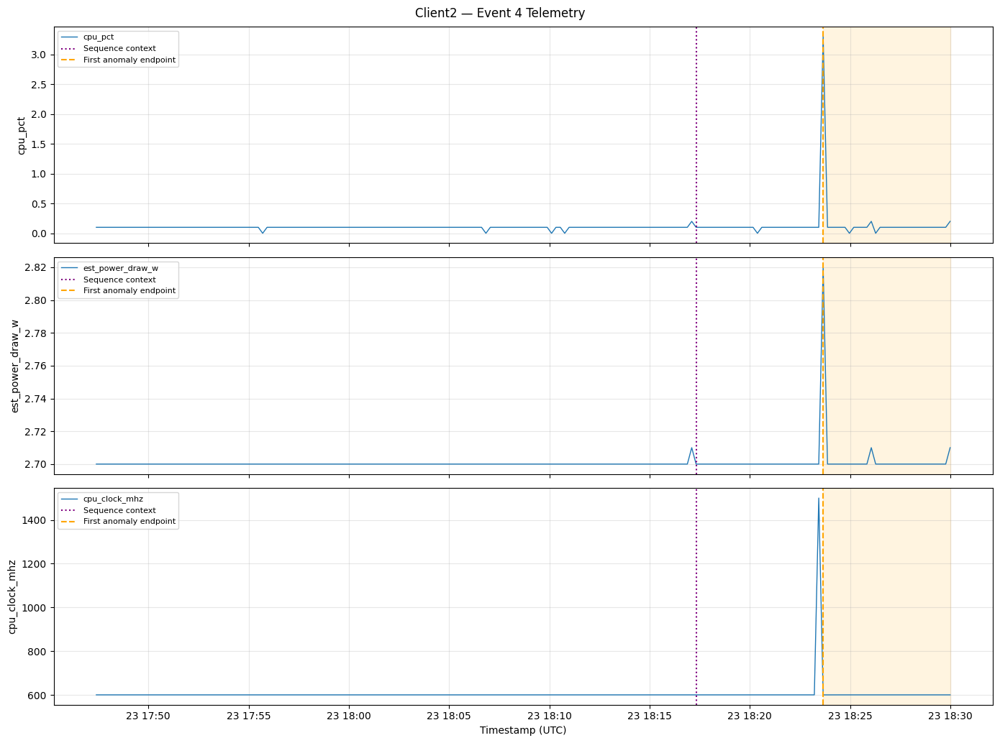


Client2 Event 3
          Metric  Baseline_Mean  Event_Mean  Event_Max  Percentage_Change
         cpu_pct       0.096350    0.148276       3.10          53.892372
   cpu_clock_mhz     601.614599  615.663793    1500.30           2.335248
est_power_draw_w       2.700000    2.702069       2.81           0.076628


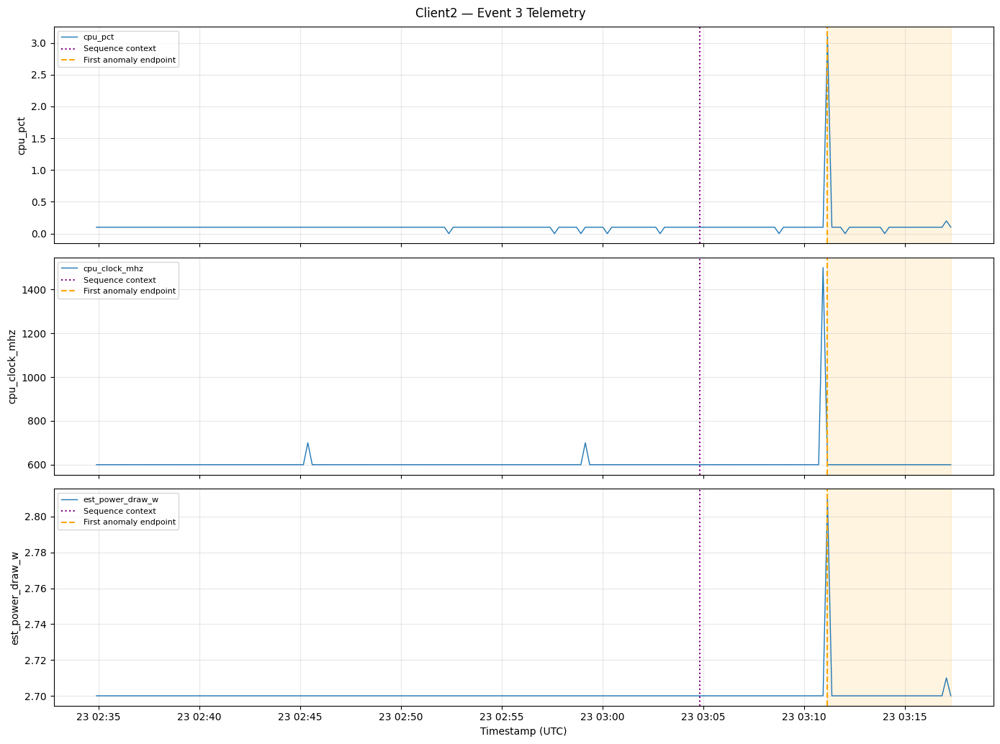


Client2 Event 6
          Metric  Baseline_Mean  Event_Mean  Event_Max  Percentage_Change
         cpu_pct       0.099270    0.152542       3.30       5.366401e+01
  disk_usage_pct      15.200000   15.200000      15.20       1.168656e-14
est_power_draw_w       2.700073    2.702034       2.82       7.262417e-02


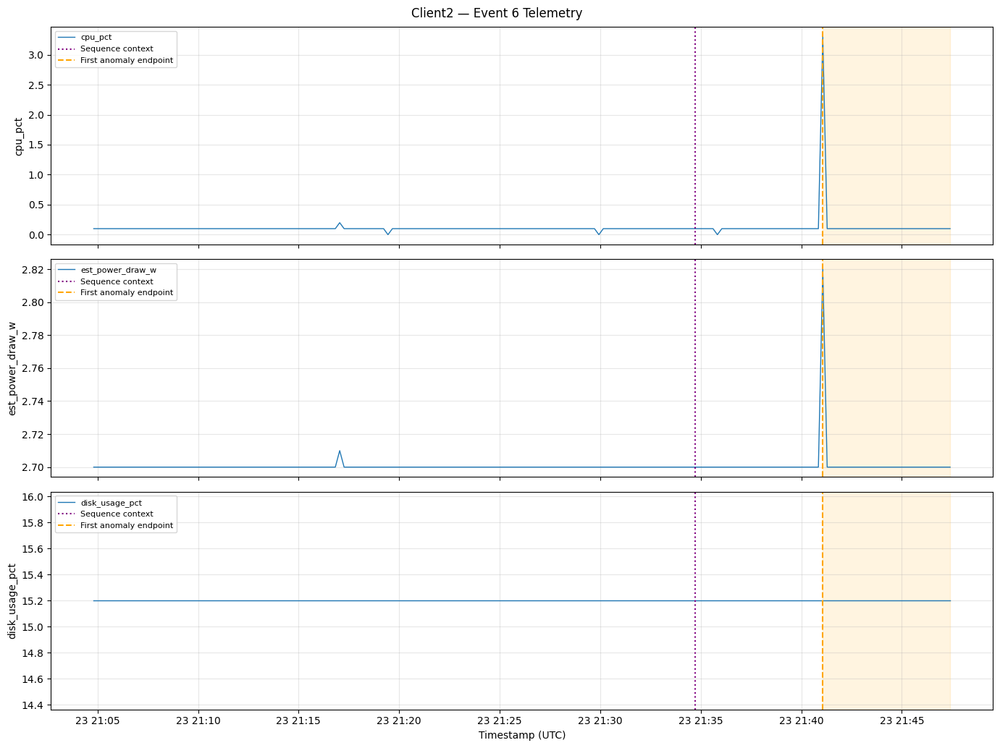


Client2 Event 1
          Metric  Baseline_Mean  Event_Mean  Event_Max  Percentage_Change
         cpu_pct       0.100000    0.152542       3.20          52.542373
   cpu_clock_mhz     600.883212  603.540678     800.20           0.442260
est_power_draw_w       2.700146    2.702034       2.82           0.069919


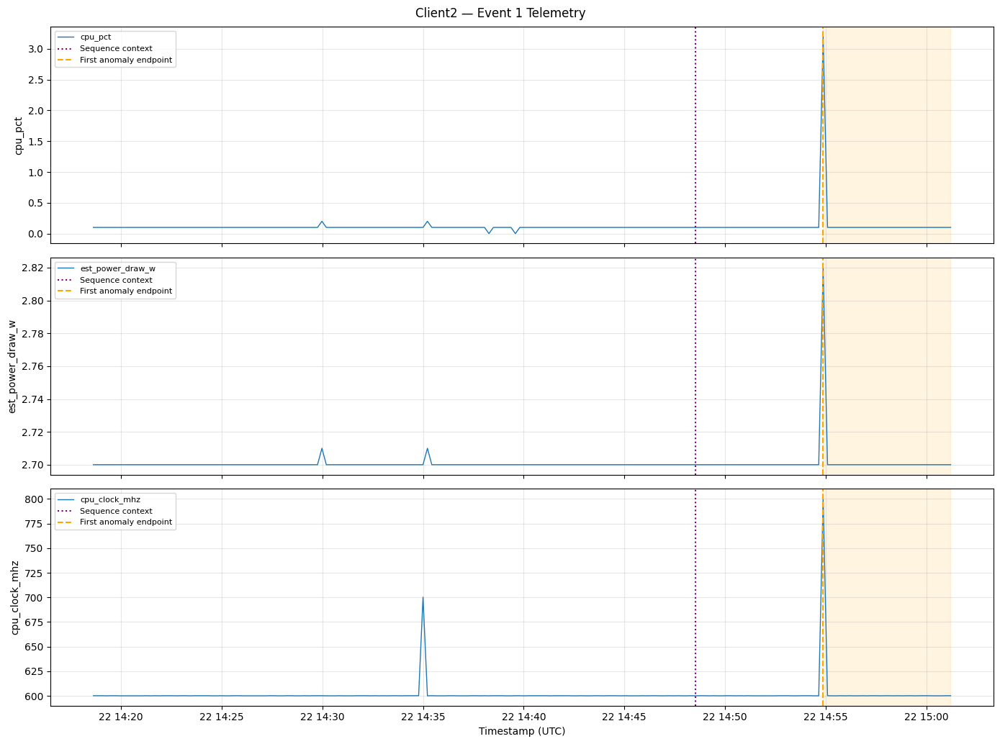


TELEMETRY VALIDATION: Client3

Client3 Event 3
          Metric  Baseline_Mean  Event_Mean  Event_Max  Percentage_Change
         cpu_pct       0.114599    0.216949     5.9000          89.312318
   cpu_voltage_v       1.200000    1.200954     1.2563           0.079520
est_power_draw_w       2.701460    2.705593     2.9200           0.153005


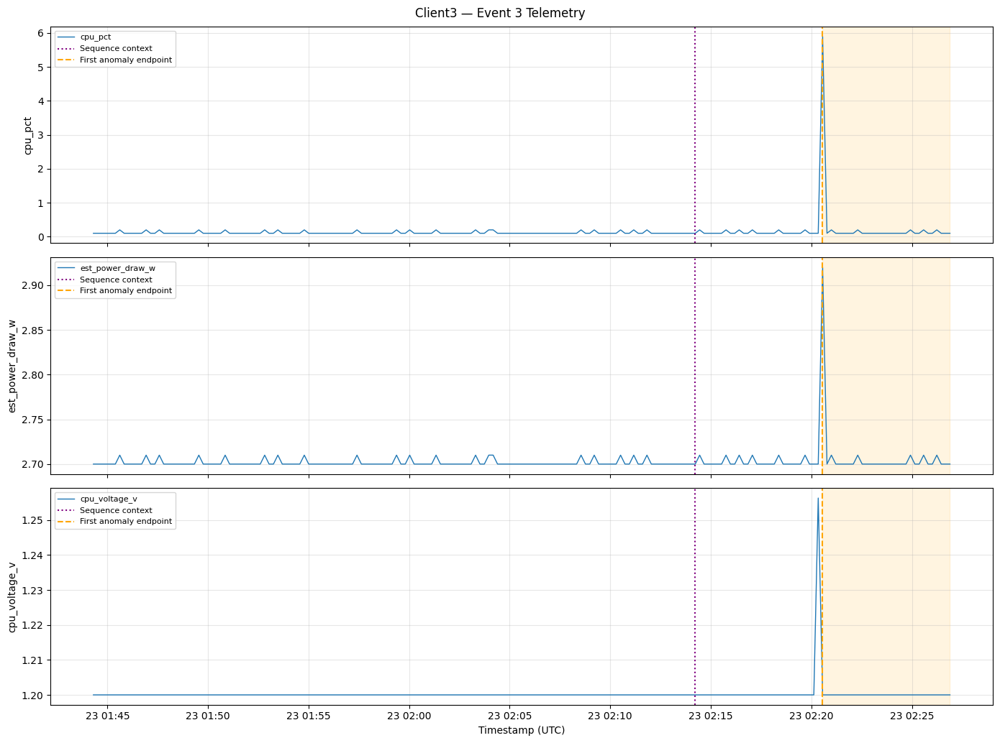


Client3 Event 5
          Metric  Baseline_Mean  Event_Mean  Event_Max  Percentage_Change
         cpu_pct       0.110949    0.206780     5.8000          86.373773
   cpu_voltage_v       1.200000    1.200954     1.2563           0.079520
est_power_draw_w       2.701095    2.704576     2.9100           0.128888


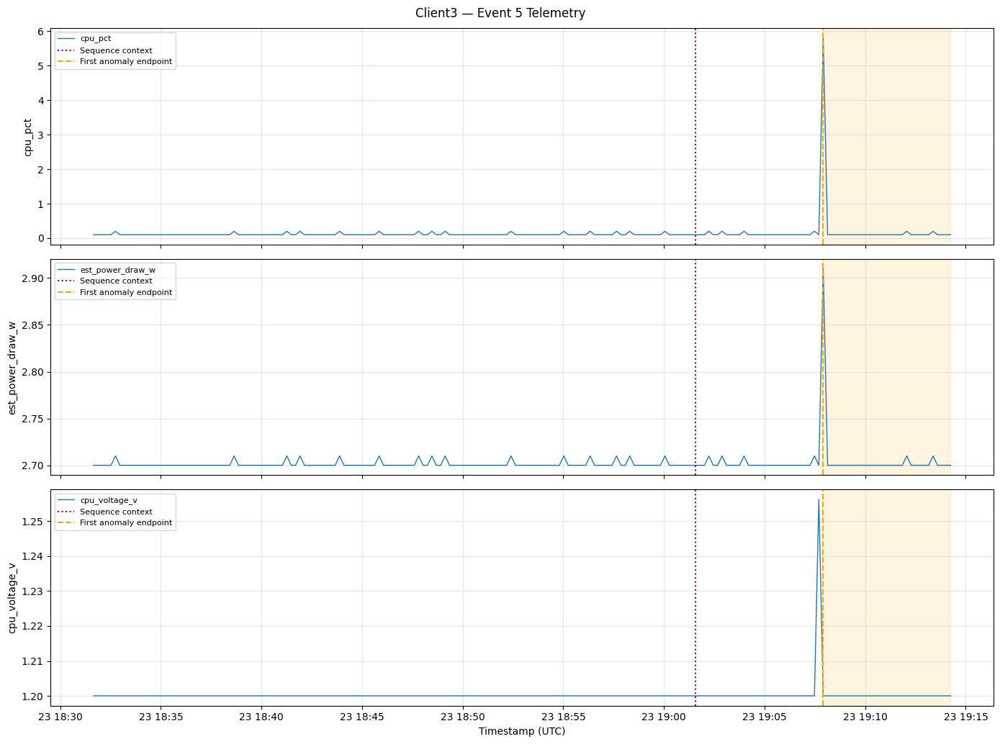


Client3 Event 1
               Metric  Baseline_Mean  Event_Mean  Event_Max  Percentage_Change
              cpu_pct       0.113869    0.237288      5.900         108.387658
packet_error_rate_pct       1.747533    1.907881     10.526           9.175708
     est_power_draw_w       2.701241    2.706102      2.920           0.179948


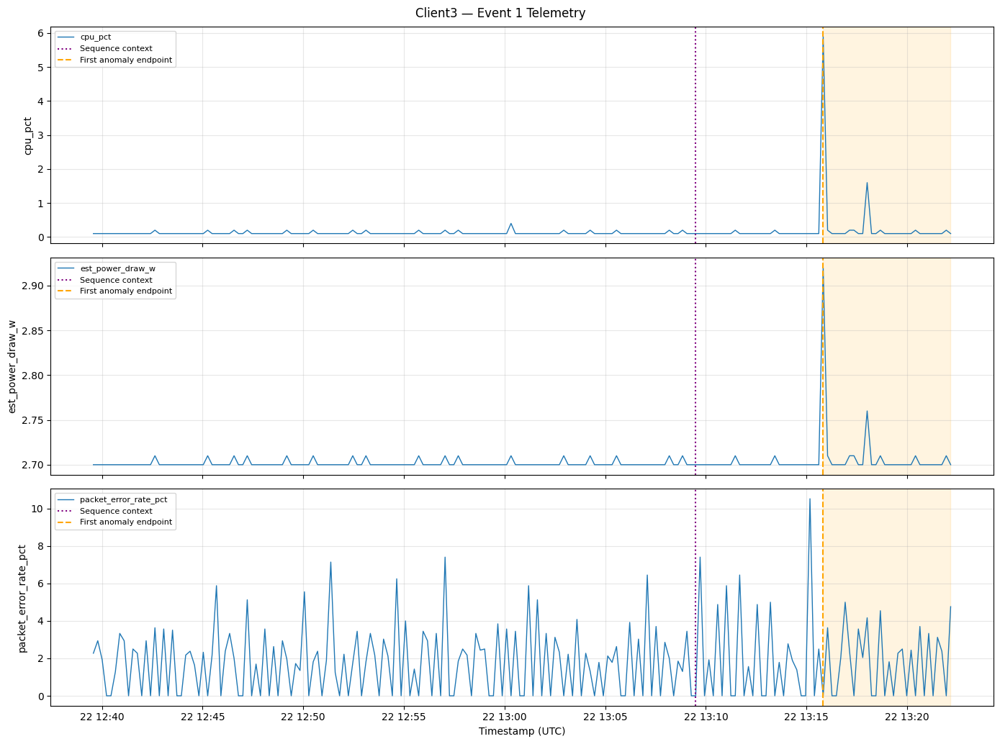


Client3 Event 6
          Metric  Baseline_Mean  Event_Mean  Event_Max  Percentage_Change
         cpu_pct       0.112409    0.212069     3.9000          88.658755
   cpu_voltage_v       1.200000    1.200971     1.2563           0.080891
est_power_draw_w       2.701241    2.704828     2.8400           0.132780


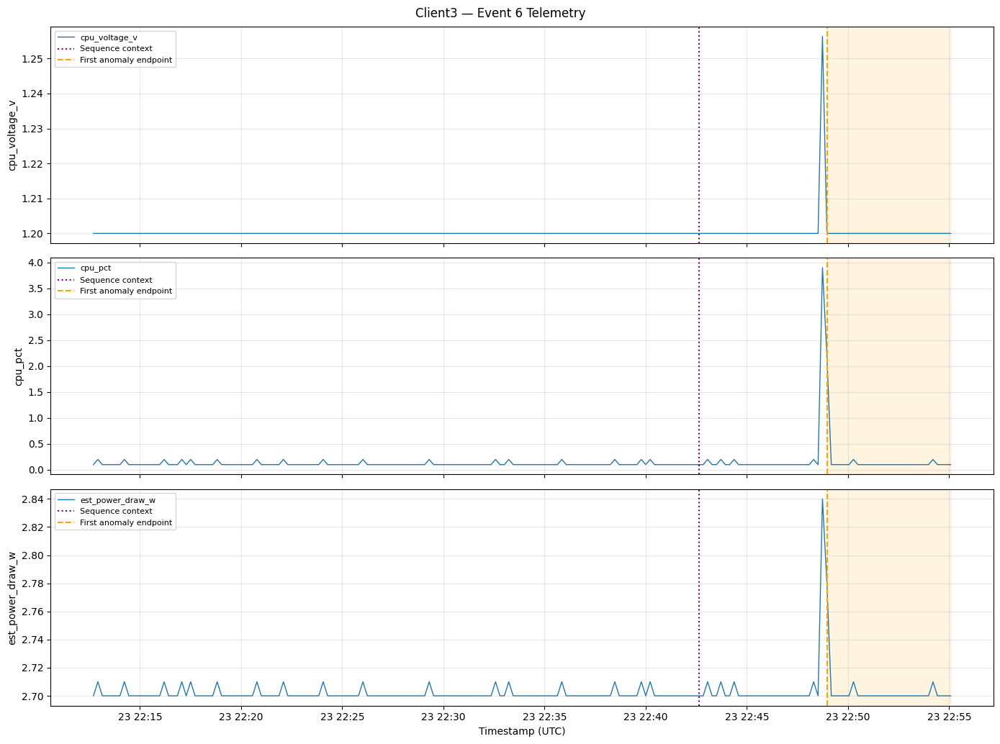


Client3 Event 4
          Metric  Baseline_Mean  Event_Mean  Event_Max  Percentage_Change
         cpu_pct       0.110219    0.210169       5.90          90.683578
  disk_usage_pct      22.500000   22.500000      22.50           0.000000
est_power_draw_w       2.701022    2.704915       2.92           0.144144


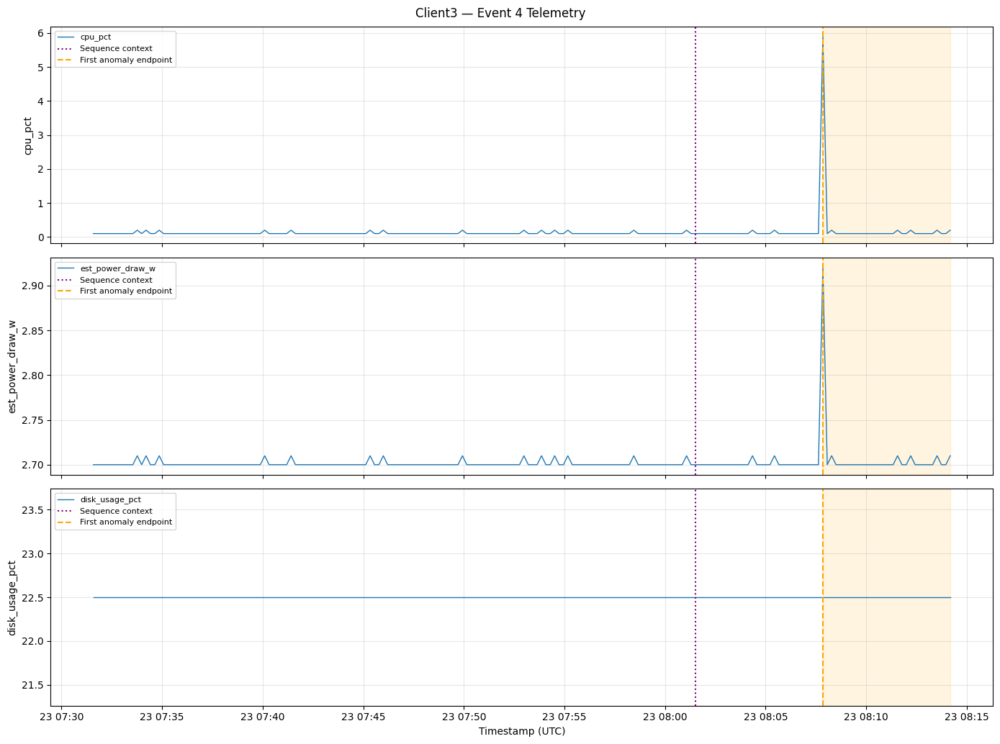


TELEMETRY VALIDATION: Switch

Switch Event 26
                    Metric  Baseline_Mean   Event_Mean  Event_Max  Percentage_Change
interface_1_out_bytes_rate     198.509444   249.410029     1657.8          25.641392
 interface_4_in_bytes_rate     359.207778 29608.200000  1020344.9        8142.638894
interface_4_out_bytes_rate    1007.386667  1968.482558    20333.3          95.404865


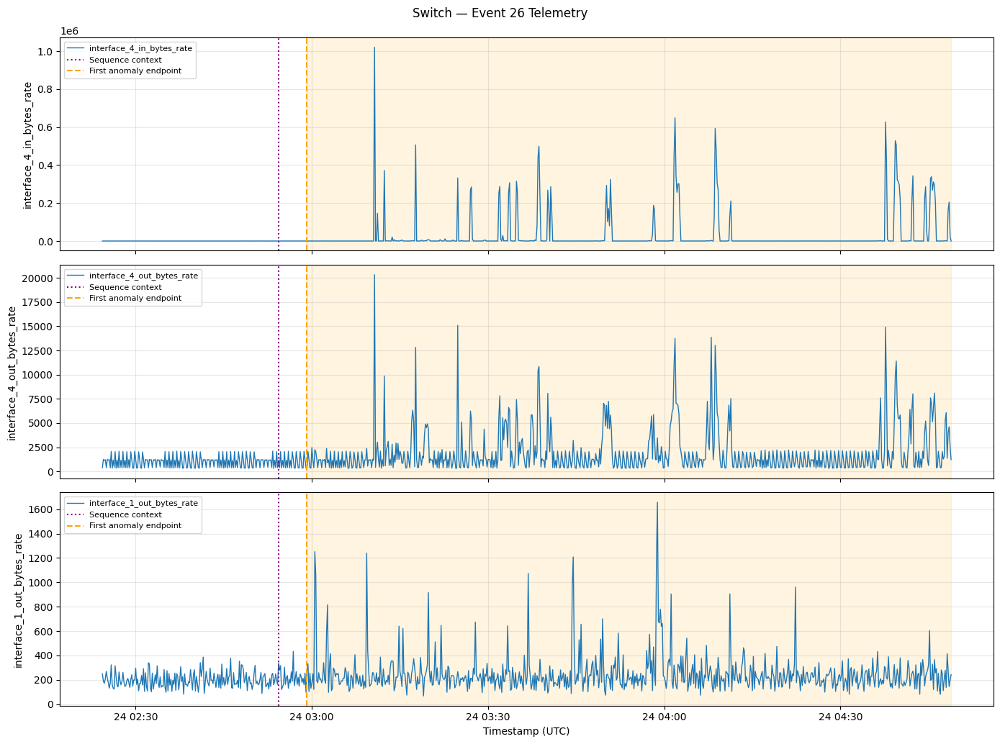


Switch Event 8
                    Metric  Baseline_Mean   Event_Mean   Event_Max  Percentage_Change
               free_memory   3.333483e+08 3.333483e+08 333348796.0           0.000012
 interface_4_in_bytes_rate   3.526898e+03 1.867090e+03      7632.9         -47.061416
interface_4_out_bytes_rate   3.736901e+03 3.557561e+03     15055.8          -4.799187


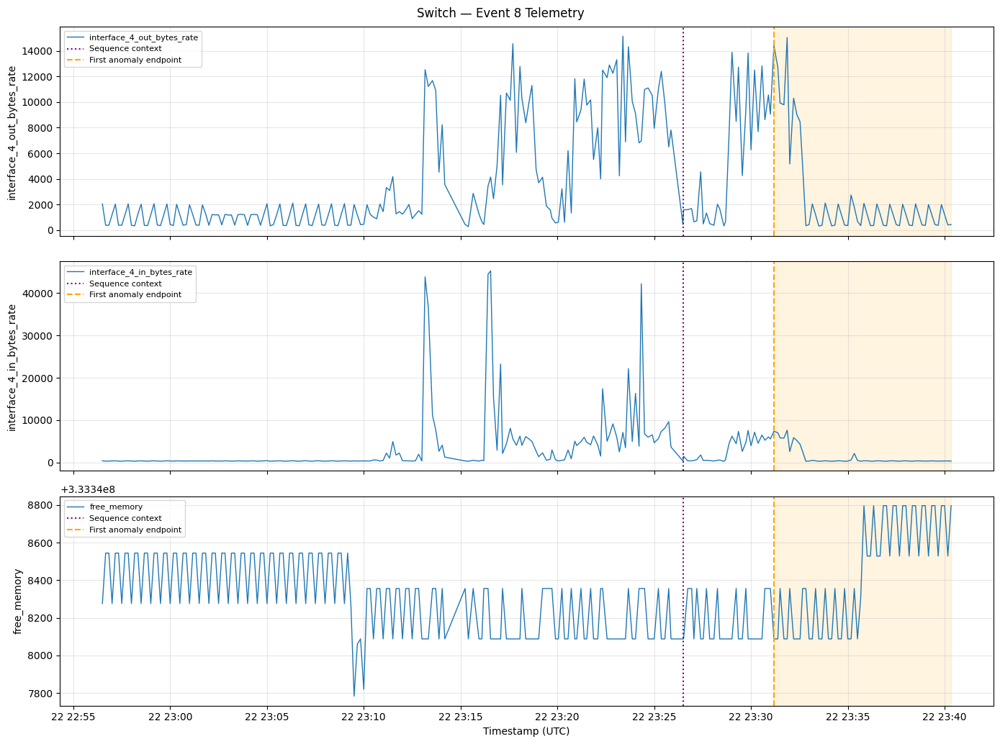


Switch Event 7
                    Metric  Baseline_Mean  Event_Mean    Event_Max  Percentage_Change
               temperature      56.045977    57.00000    57.000000           1.702215
 interface_4_in_bytes_rate    1033.525210  6988.85315 45251.250000         576.215063
interface_4_out_bytes_rate    1401.774503  7227.02948 15156.909091         415.562914


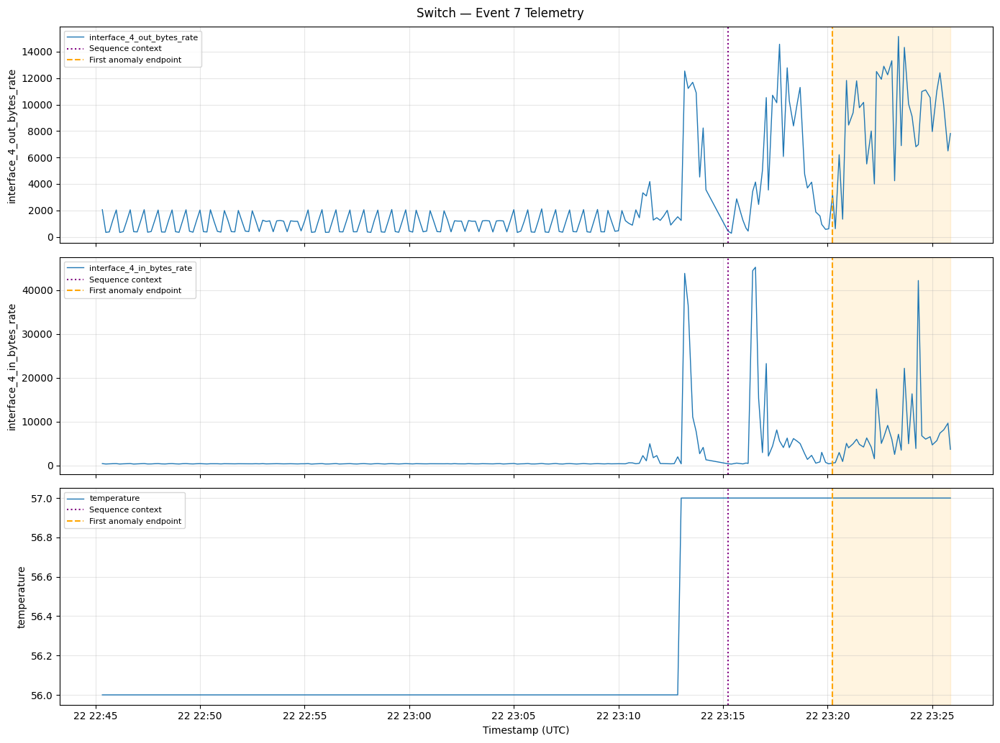


Switch Event 6
                    Metric  Baseline_Mean  Event_Mean  Event_Max  Percentage_Change
interface_1_out_bytes_rate     201.266667  246.149916      997.1          22.300389
 interface_4_in_bytes_rate     358.142222 2912.021446    43849.3         713.090796
interface_4_out_bytes_rate    1010.646111 2491.692684    12541.2         146.544528


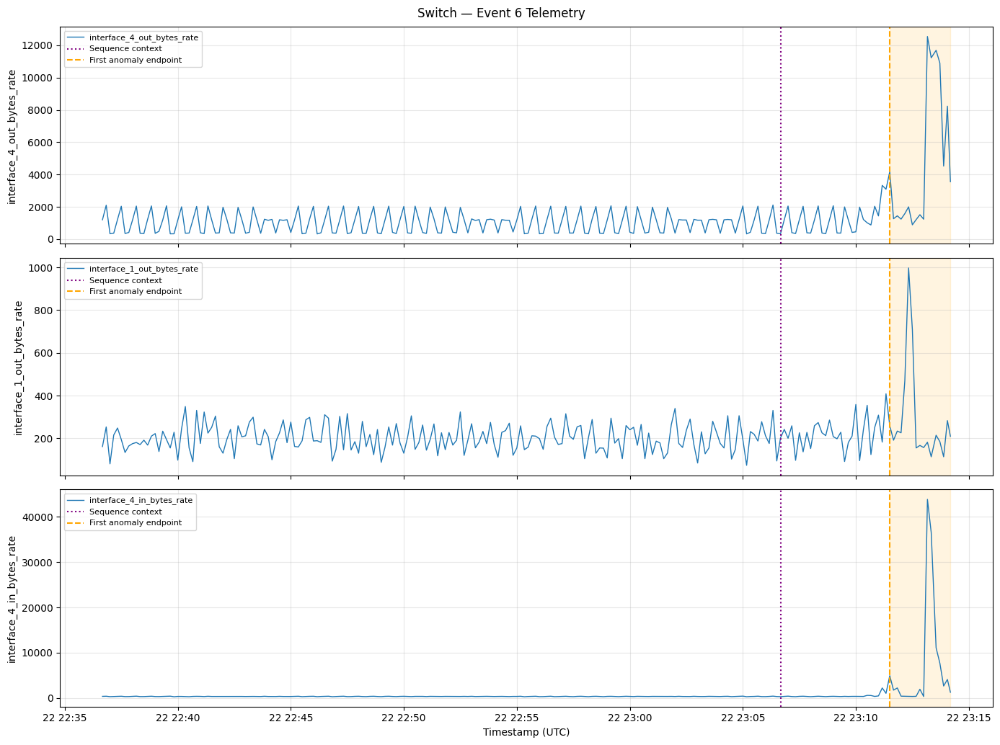


Switch Event 9
                    Metric  Baseline_Mean  Event_Mean  Event_Max  Percentage_Change
interface_1_out_bytes_rate     199.747778  209.500000      457.9           4.882268
interface_3_out_bytes_rate     366.090000  445.035714     2043.4          21.564565
interface_4_out_bytes_rate    1008.794444  993.392857     2886.9          -1.526732


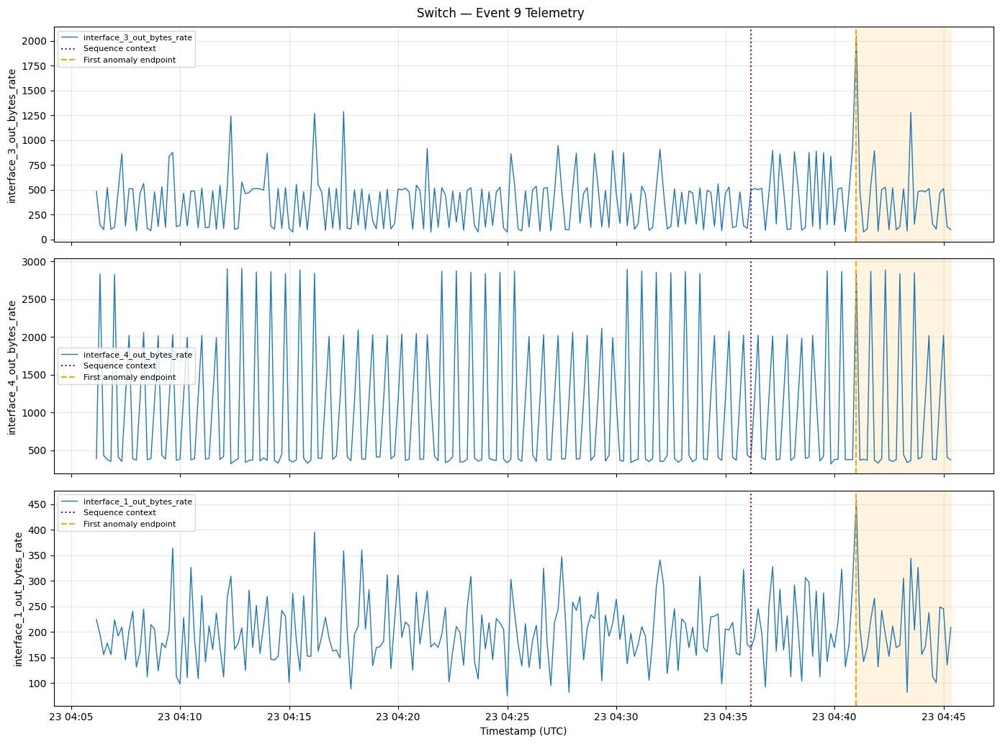


Switch Counter Audit:
 Event_ID                Counter  Baseline_Mean_Rate  Event_Mean_Rate  Event_Max_Rate  Negative_Counter_Differences  Irregular_Sampling_Intervals
       26   interface_1_in_bytes          755.553333       770.884302    2.425700e+03                             0                             0
       26  interface_1_in_errors            0.000000         0.000000    0.000000e+00                             0                             0
       26  interface_1_out_bytes          198.509444       249.410029    1.657800e+03                             0                             0
       26 interface_1_out_errors            0.000000         0.000000    0.000000e+00                             0                             0
       26   interface_2_in_bytes          290.751111       289.776890    1.054500e+03                             0                             0
       26  interface_2_in_errors            0.000000         0.000000    0.000000e+00                

In [8]:
# ============================================================
# SECTION 8 — TELEMETRY VALIDATION
# ============================================================

BASELINE_MINUTES = 30
TOP_EVENTS_PER_DEVICE = 5
TOP_METRICS_TO_PLOT = 3
INCLUDE_SEQUENCE_CONTEXT = True

VALIDATION_DIR = OUTPUT_DIR / "Telemetry_Validation"
VALIDATION_PLOTS_DIR = VALIDATION_DIR / "Plots"

VALIDATION_DIR.mkdir(parents=True, exist_ok=True)
VALIDATION_PLOTS_DIR.mkdir(parents=True, exist_ok=True)

validation_results = []
switch_counter_audit = []


def prepare_telemetry(df):

    df = df.copy()

    df["timestamp"] = pd.to_datetime(
        df["timestamp"],
        utc=True,
        errors="coerce"
    )

    return (
        df.dropna(subset=["timestamp"])
        .sort_values("timestamp")
        .drop_duplicates("timestamp", keep="last")
        .reset_index(drop=True)
    )


def get_numeric_values(df, metric):

    if metric not in df.columns:
        return pd.Series(dtype=float)

    return pd.to_numeric(
        df[metric],
        errors="coerce"
    ).replace(
        [np.inf, -np.inf], np.nan
    ).dropna()


def safe_mean(values):
    return float(values.mean()) if len(values) else np.nan


def safe_max(values):
    return float(values.max()) if len(values) else np.nan


def safe_min(values):
    return float(values.min()) if len(values) else np.nan


def safe_std(values):
    return float(values.std()) if len(values) > 1 else np.nan


def calculate_change(baseline_mean, event_mean):

    if (
        not np.isfinite(baseline_mean)
        or not np.isfinite(event_mean)
    ):
        return np.nan, np.nan

    change = event_mean - baseline_mean

    percentage = (
        change / abs(baseline_mean) * 100
        if abs(baseline_mean) > 1e-12
        else np.nan
    )

    return change, percentage


def find_sequence_context_start(
    telemetry,
    start_time,
    sequence_length=30
):

    times = telemetry["timestamp"]

    position = int(
        times.searchsorted(start_time, side="right") - 1
    )

    if position < 0:
        return start_time

    first_position = max(
        0,
        position - sequence_length + 1
    )

    return times.iloc[first_position]


for device in DEVICES:

    print("\n" + "=" * 65)
    print("TELEMETRY VALIDATION:", device)
    print("=" * 65)

    telemetry = prepare_telemetry(datasets[device])
    metrics = device_metrics[device]

    events = anomaly_events[device].copy()

    if events.empty:
        continue

    events["start_time"] = pd.to_datetime(
        events["start_time"], utc=True
    )

    events["end_time"] = pd.to_datetime(
        events["end_time"], utc=True
    )

    strongest_events = (
        events.sort_values(
            "peak_threshold_ratio",
            ascending=False
        )
        .head(TOP_EVENTS_PER_DEVICE)
    )

    for _, event in strongest_events.iterrows():

        event_id = int(event["event_id"])
        start = event["start_time"]
        end = event["end_time"]
        dominant = str(event["dominant_metric"])

        if INCLUDE_SEQUENCE_CONTEXT:

            context_start = find_sequence_context_start(
                telemetry,
                start,
                SEQUENCE_LENGTH
            )

        else:
            context_start = start

        baseline_start = (
            context_start
            - pd.Timedelta(minutes=BASELINE_MINUTES)
        )

        baseline = telemetry.loc[
            (telemetry["timestamp"] >= baseline_start)
            & (telemetry["timestamp"] < context_start)
        ]

        event_telemetry = telemetry.loc[
            (telemetry["timestamp"] >= context_start)
            & (telemetry["timestamp"] <= end)
        ]

        event_records = []

        for metric in metrics:

            before = get_numeric_values(
                baseline,
                metric
            )

            during = get_numeric_values(
                event_telemetry,
                metric
            )

            baseline_mean = safe_mean(before)
            event_mean = safe_mean(during)

            absolute_change, percentage_change = (
                calculate_change(
                    baseline_mean,
                    event_mean
                )
            )

            record = {
                "Device": device,
                "Event_ID": event_id,
                "Event_Start": start,
                "Event_End": end,
                "Investigation_Start": context_start,
                "Metric": metric,
                "Is_Dominant_Metric": metric == dominant,
                "Baseline_Samples": len(before),
                "Event_Samples": len(during),
                "Baseline_Mean": baseline_mean,
                "Baseline_Std": safe_std(before),
                "Baseline_Min": safe_min(before),
                "Baseline_Max": safe_max(before),
                "Event_Mean": event_mean,
                "Event_Std": safe_std(during),
                "Event_Min": safe_min(during),
                "Event_Max": safe_max(during),
                "Absolute_Change": absolute_change,
                "Percentage_Change": percentage_change,
                "Peak_Threshold_Ratio": float(
                    event["peak_threshold_ratio"]
                )
            }

            event_records.append(record)
            validation_results.append(record)

        event_stats = pd.DataFrame(event_records)

        event_stats.to_csv(
            VALIDATION_DIR /
            f"{device}_Event_{event_id}_Telemetry.csv",
            index=False
        )

        top_metrics = [
            metric.strip()
            for metric in str(
                event["top_3_metrics"]
            ).split(",")
            if metric.strip() in metrics
        ]

        if dominant in metrics:
            top_metrics.insert(0, dominant)

        top_metrics = list(
            dict.fromkeys(top_metrics)
        )[:TOP_METRICS_TO_PLOT]

        print(f"\n{device} Event {event_id}")

        print(
            event_stats.loc[
                event_stats["Metric"].isin(top_metrics),
                [
                    "Metric",
                    "Baseline_Mean",
                    "Event_Mean",
                    "Event_Max",
                    "Percentage_Change"
                ]
            ].to_string(index=False)
        )

        plot_df = telemetry.loc[
            (telemetry["timestamp"] >= baseline_start)
            & (telemetry["timestamp"] <= end)
        ]

        fig, axes = plt.subplots(
            len(top_metrics),
            1,
            figsize=(14, 3.5 * len(top_metrics)),
            sharex=True,
            squeeze=False
        )

        axes = axes.flatten()

        for ax, metric in zip(axes, top_metrics):

            ax.plot(
                plot_df["timestamp"],
                pd.to_numeric(
                    plot_df[metric],
                    errors="coerce"
                ),
                linewidth=1,
                label=metric
            )

            ax.axvline(
                context_start,
                linestyle=":",
                color="purple",
                label="Sequence context"
            )

            ax.axvline(
                start,
                linestyle="--",
                color="orange",
                label="First anomaly endpoint"
            )

            ax.axvspan(
                start,
                end,
                color="orange",
                alpha=0.12
            )

            ax.set_ylabel(metric)
            ax.grid(alpha=0.3)
            ax.legend(fontsize=8)

        axes[-1].set_xlabel("Timestamp (UTC)")

        fig.suptitle(
            f"{device} — Event {event_id} Telemetry"
        )

        plt.tight_layout()

        plt.savefig(
            VALIDATION_PLOTS_DIR /
            f"{device}_Event_{event_id}_Telemetry.png",
            dpi=150
        )

        plt.show()
        plt.close()


# ------------------------------------------------------------
# 8.8 Switch cumulative counter audit
# ------------------------------------------------------------

raw_switch = original_datasets.get("Switch")

if raw_switch is not None:

    raw_switch = prepare_telemetry(raw_switch)

    counter_columns = [
        f"interface_{port}_{direction}_{counter}"
        for port in range(1, 5)
        for direction in ["in", "out"]
        for counter in ["bytes", "errors"]
    ]

    available_counters = [
        col for col in counter_columns
        if col in raw_switch.columns
    ]

    if available_counters:

        raw_switch["elapsed_seconds"] = (
            raw_switch["timestamp"]
            .diff()
            .dt.total_seconds()
        )

        for counter in available_counters:

            values = pd.to_numeric(
                raw_switch[counter],
                errors="coerce"
            )

            difference = values.diff()
            elapsed = raw_switch["elapsed_seconds"]

            invalid = (
                (difference < 0)
                | (elapsed <= 0)
                | (elapsed > MAX_GAP_SECONDS["Switch"])
            )

            raw_switch[
                f"{counter}_difference"
            ] = difference

            raw_switch[
                f"{counter}_calculated_rate"
            ] = (
                difference / elapsed
            ).mask(invalid)

        switch_events = anomaly_events["Switch"]

        if not switch_events.empty:

            for _, event in (
                switch_events.sort_values(
                    "peak_threshold_ratio",
                    ascending=False
                ).head(4).iterrows()
            ):

                event_id = int(event["event_id"])
                start = pd.to_datetime(
                    event["start_time"], utc=True
                )
                end = pd.to_datetime(
                    event["end_time"], utc=True
                )

                context_start = (
                    find_sequence_context_start(
                        datasets["Switch"],
                        start,
                        SEQUENCE_LENGTH
                    )
                )

                baseline_start = (
                    context_start
                    - pd.Timedelta(
                        minutes=BASELINE_MINUTES
                    )
                )

                baseline_mask = (
                    (
                        raw_switch["timestamp"]
                        >= baseline_start
                    )
                    & (
                        raw_switch["timestamp"]
                        < context_start
                    )
                )

                event_mask = (
                    (
                        raw_switch["timestamp"]
                        >= context_start
                    )
                    & (
                        raw_switch["timestamp"]
                        <= end
                    )
                )

                before = raw_switch.loc[
                    baseline_mask
                ]

                during = raw_switch.loc[
                    event_mask
                ]

                for counter in available_counters:

                    rate_col = (
                        f"{counter}_calculated_rate"
                    )

                    diff_col = (
                        f"{counter}_difference"
                    )

                    baseline_rates = get_numeric_values(
                        before,
                        rate_col
                    )

                    event_rates = get_numeric_values(
                        during,
                        rate_col
                    )

                    negative_diffs = (
                        pd.to_numeric(
                            during[diff_col],
                            errors="coerce"
                        ) < 0
                    ).sum()

                    irregular = (
                        (during["elapsed_seconds"] <= 0)
                        | (
                            during["elapsed_seconds"]
                            > MAX_GAP_SECONDS["Switch"]
                        )
                    ).sum()

                    switch_counter_audit.append({
                        "Event_ID": event_id,
                        "Counter": counter,
                        "Baseline_Mean_Rate":
                            safe_mean(baseline_rates),
                        "Event_Mean_Rate":
                            safe_mean(event_rates),
                        "Event_Max_Rate":
                            safe_max(event_rates),
                        "Negative_Counter_Differences":
                            int(negative_diffs),
                        "Irregular_Sampling_Intervals":
                            int(irregular)
                    })


if switch_counter_audit:

    counter_audit_df = pd.DataFrame(
        switch_counter_audit
    )

    counter_audit_df.to_csv(
        VALIDATION_DIR / "Switch_Counter_Audit.csv",
        index=False
    )

    print("\nSwitch Counter Audit:")
    print(counter_audit_df.to_string(index=False))

else:
    print("\nSwitch counter audit unavailable.")


# ------------------------------------------------------------
# 8.9 Final validation summary
# ------------------------------------------------------------

validation_df = pd.DataFrame(
    validation_results
)

validation_df.to_csv(
    VALIDATION_DIR /
    "All_Event_Telemetry_Validation.csv",
    index=False
)

dominant_validation_df = validation_df.loc[
    validation_df["Is_Dominant_Metric"]
].copy()

dominant_validation_df = (
    dominant_validation_df.sort_values(
        "Peak_Threshold_Ratio",
        ascending=False
    )
)

dominant_validation_df.to_csv(
    VALIDATION_DIR /
    "Dominant_Metric_Validation.csv",
    index=False
)

print("\n" + "=" * 65)
print("SECTION 8 COMPLETE")
print("=" * 65)

print("\nDominant Metric Validation Summary:")

print(
    dominant_validation_df[
        [
            "Device",
            "Event_ID",
            "Metric",
            "Baseline_Mean",
            "Event_Mean",
            "Event_Max",
            "Percentage_Change",
            "Peak_Threshold_Ratio"
        ]
    ].to_string(index=False)
)


Section 9 - Synthetic Fault Injection


Client1 — ALL METRICS
CPU_Overload | 30_seconds: 5 injections completed
CPU_Overload | 2_minutes: 5 injections completed
CPU_Overload | 5_minutes: 5 injections completed
High_Latency | 30_seconds: 5 injections completed
High_Latency | 2_minutes: 5 injections completed
High_Latency | 5_minutes: 5 injections completed
Packet_Loss | 30_seconds: 5 injections completed
Packet_Loss | 2_minutes: 5 injections completed
Packet_Loss | 5_minutes: 5 injections completed
High_Temperature | 30_seconds: 5 injections completed
High_Temperature | 2_minutes: 5 injections completed
High_Temperature | 5_minutes: 5 injections completed
CPU_Clock_Reduction | 30_seconds: 5 injections completed
CPU_Clock_Reduction | 2_minutes: 5 injections completed
CPU_Clock_Reduction | 5_minutes: 5 injections completed
Low_CPU_Voltage | 30_seconds: 5 injections completed
Low_CPU_Voltage | 2_minutes: 5 injections completed
Low_CPU_Voltage | 5_minutes: 5 injections completed
Disk_Almost_Full | 30_seconds: 5 injections comple

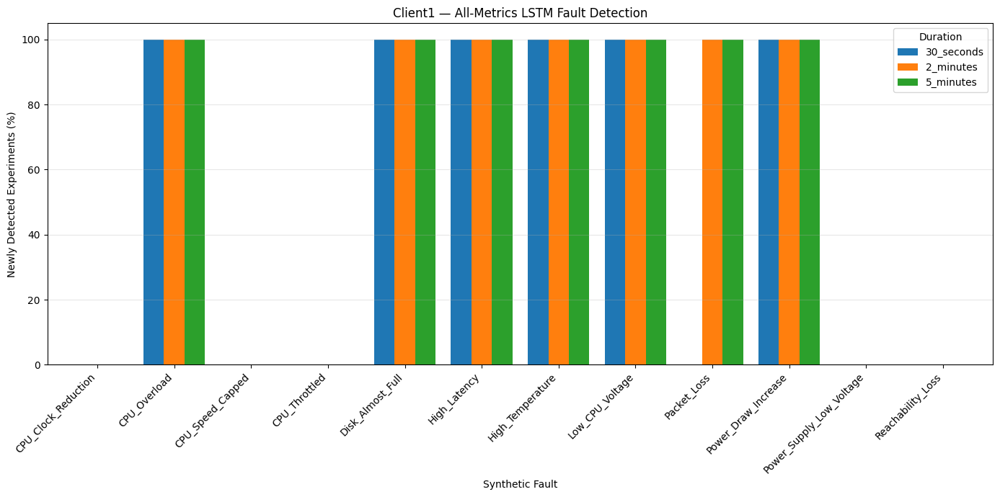

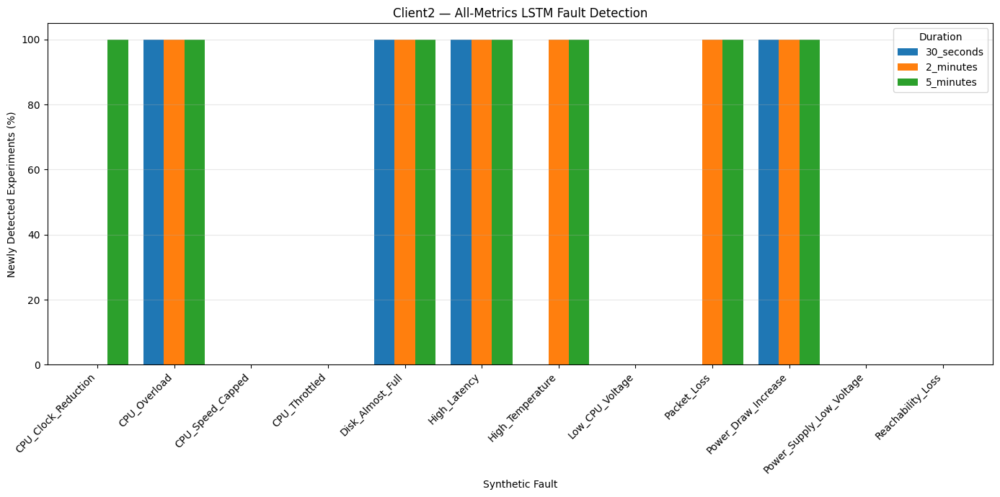

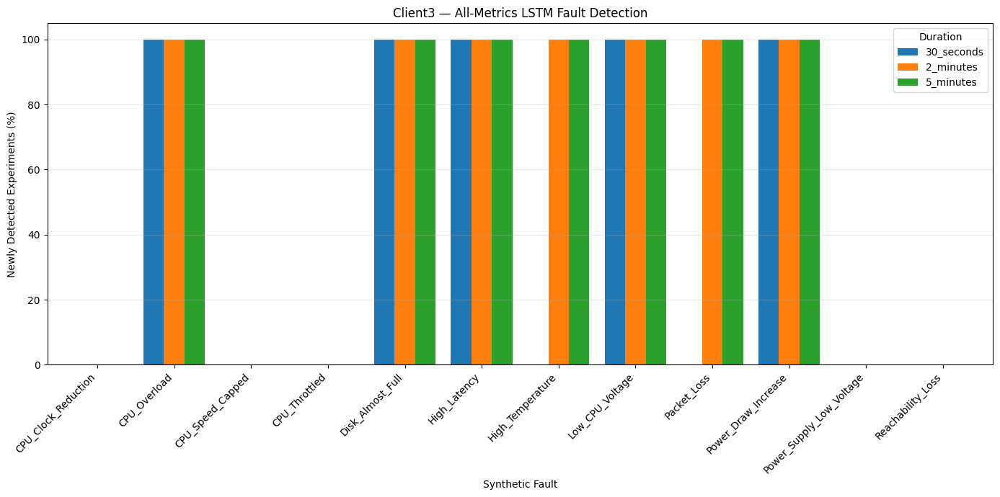

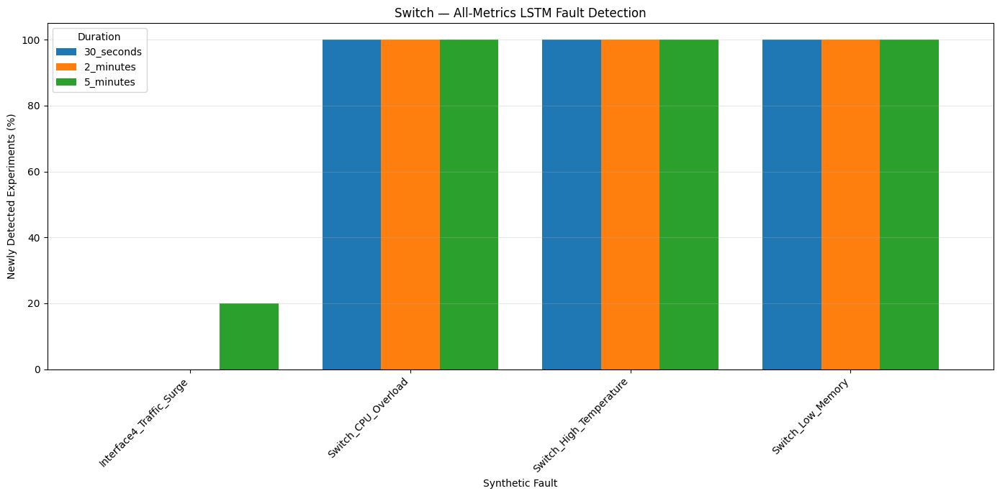


SECTION 9B COMPLETE — ALL METRICS
Total experiments: 600

Results summary:
 Device                    Fault   Duration  Experiments  Detected  Newly_Detected  Mean_Detection_Delay  Mean_Error_Increase  New_Detection_Rate_Pct
Client1      CPU_Clock_Reduction  2_minutes            5         0               0                   NaN         1.836782e+00                     0.0
Client1      CPU_Clock_Reduction 30_seconds            5         0               0                   NaN         6.672639e-01                     0.0
Client1      CPU_Clock_Reduction  5_minutes            5         0               0                   NaN         3.181228e+00                     0.0
Client1             CPU_Overload  2_minutes            5         5               5              0.000000         3.102495e+04                   100.0
Client1             CPU_Overload 30_seconds            5         5               5              0.000000         1.137573e+04                   100.0
Client1             CPU_

In [9]:
# ============================================================
# SECTION 9B — EXPANDED SYNTHETIC FAULT INJECTION
# ALL-METRICS LSTM AUTOENCODER
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUTPUT_DIR = Path("LSTM_Results") / "All_Metrics_Fault_Injection"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FAULT_DURATIONS = {
    "30_seconds": 30,
    "2_minutes": 120,
    "5_minutes": 300,
}

INJECTION_POSITIONS = [0.12, 0.30, 0.48, 0.66, 0.83]
DEVICE_ORDER = ["Client1", "Client2", "Client3", "Switch"]

# Each fault:
# (aliases, injection method, value)

CLIENT_FAULTS = {
    "CPU_Overload": (
        ["cpu_pct"], "set", 85.0
    ),
    "High_Latency": (
        ["latency_ms"], "set", 50.0
    ),
    "Packet_Loss": (
        ["packet_loss_pct"], "set", 20.0
    ),
    "High_Temperature": (
        ["temperature_c", "temp_c"], "set", 80.0
    ),
    "CPU_Clock_Reduction": (
        ["cpu_clock_mhz"], "median_fraction", 0.50
    ),
    "Low_CPU_Voltage": (
        ["cpu_voltage_v"], "median_fraction", 0.75
    ),
    "Disk_Almost_Full": (
        ["disk_usage_pct"], "set", 95.0
    ),
    "Reachability_Loss": (
        ["reachability"], "set", 0.0
    ),
    "Power_Supply_Low_Voltage": (
        ["power_supply_low_voltage"], "set", 1.0
    ),
    "CPU_Throttled": (
        ["cpu_throttled"], "set", 1.0
    ),
    "CPU_Speed_Capped": (
        ["cpu_speed_capped"], "set", 1.0
    ),
    "Power_Draw_Increase": (
        ["est_power_draw_w"], "median_multiple", 1.75
    ),
}

SWITCH_FAULTS = {
    "Switch_CPU_Overload": (
        ["cpu_pct", "cpu_load"], "set", 85.0
    ),
    "Switch_High_Temperature": (
        ["temperature", "temp"], "set", 80.0
    ),
    "Switch_Low_Memory": (
        ["free_memory", "free_ram"], "median_fraction", 0.10
    ),
    "Interface4_Traffic_Surge": (
        ["interface_4_in_bytes_rate"],
        "median_multiple", 20.0
    ),
}

def reconstruct_mse(model, X):
    X = np.asarray(X, dtype=np.float32)
    prediction = model.predict(
        X, batch_size=256, verbose=0
    )
    return np.mean(
        (X.astype(np.float64) -
         prediction.astype(np.float64)) ** 2,
        axis=(1, 2)
    )

def run_all_metrics_fault_injection():
    records = []
    sequence_records = []
    skipped = []

    for device in DEVICE_ORDER:
        print(f"\n{'=' * 60}\n{device} — ALL METRICS\n{'=' * 60}")

        data = sequence_data[device]
        metrics = list(data["metrics"])
        X_test = np.asarray(data["test"])
        scaler = scalers[device]

        model = models.get(device)
        if model is None:
            from tensorflow import keras
            model = keras.models.load_model(
                Path("LSTM_Results") / "Models" /
                f"{device}_LSTM_Autoencoder.keras"
            )

        threshold = float(anomaly_thresholds[device])
        if threshold <= 0:
            raise ValueError(f"{device}: Invalid threshold")

        obs_times = pd.DatetimeIndex(
            pd.to_datetime(
                split_data[device]["test_timestamps"], utc=True
            )
        )
        seq_times = pd.DatetimeIndex(
            pd.to_datetime(data["test_timestamps"], utc=True)
        )

        end_indices = obs_times.get_indexer(seq_times)
        seq_len = X_test.shape[1]
        start_indices = end_indices - seq_len + 1

        if np.any(start_indices < 0):
            raise ValueError(
                f"{device}: Test sequence alignment failed"
            )

        train_raw = scaler.inverse_transform(
            split_data[device]["train"]
        )

        baseline_errors = reconstruct_mse(model, X_test)

        faults = (
            SWITCH_FAULTS if device == "Switch"
            else CLIENT_FAULTS
        )

        for fault_name, (aliases, method, value) in faults.items():

            metric = next(
                (name for name in aliases if name in metrics),
                None
            )

            if metric is None:
                skipped.append({
                    "Device": device,
                    "Fault": fault_name,
                    "Reason": "Metric not present"
                })
                print(f"SKIPPED: {fault_name} — unavailable metric")
                continue

            metric_idx = metrics.index(metric)

            train_median = float(
                np.median(train_raw[:, metric_idx])
            )

            if method == "set":
                raw_value = value
            elif method == "median_fraction":
                raw_value = train_median * value
            elif method == "median_multiple":
                if train_median <= 0:
                    skipped.append({
                        "Device": device,
                        "Fault": fault_name,
                        "Reason": "Non-positive training median"
                    })
                    continue
                raw_value = train_median * value
            else:
                raise ValueError(f"Unknown method: {method}")

            scaled_value = (
                raw_value - scaler.mean_[metric_idx]
            ) / scaler.scale_[metric_idx]

            for duration_name, duration_s in FAULT_DURATIONS.items():

                for injection_number, position in enumerate(
                    INJECTION_POSITIONS, start=1
                ):
                    start_row = int(len(obs_times) * position)
                    inject_start = obs_times[start_row]
                    inject_end = inject_start + pd.Timedelta(
                        seconds=duration_s
                    )

                    injected_rows = np.flatnonzero(
                        (obs_times >= inject_start) &
                        (obs_times < inject_end)
                    )

                    if len(injected_rows) == 0:
                        raise ValueError(
                            f"{device}: No observations in injection"
                        )

                    first = int(injected_rows[0])
                    last = int(injected_rows[-1])

                    affected = np.flatnonzero(
                        (end_indices >= first) &
                        (start_indices <= last)
                    )

                    if len(affected) == 0:
                        raise ValueError(
                            f"{device}: No sequences affected"
                        )

                    original_X = X_test[affected]
                    injected_X = original_X.copy()

                    row_positions = (
                        end_indices[affected, None] -
                        np.arange(seq_len - 1, -1, -1)[None, :]
                    )

                    mask = (
                        (row_positions >= first) &
                        (row_positions <= last)
                    )

                    injected_X[:, :, metric_idx] = np.where(
                        mask,
                        scaled_value,
                        injected_X[:, :, metric_idx]
                    )

                    original_errors = baseline_errors[affected]
                    injected_errors = reconstruct_mse(
                        model, injected_X
                    )

                    original_flags = original_errors > threshold
                    injected_flags = injected_errors > threshold
                    new_flags = injected_flags & ~original_flags

                    first_new = (
                        seq_times[affected][np.flatnonzero(new_flags)[0]]
                        if new_flags.any() else pd.NaT
                    )

                    detection_delay = (
                        (first_new - inject_start).total_seconds()
                        if new_flags.any() else np.nan
                    )

                    experiment_id = (
                        f"AllMetrics_{device}_{fault_name}_"
                        f"{duration_name}_{injection_number}"
                    )

                    records.append({
                        "Experiment_ID": experiment_id,
                        "Device": device,
                        "Model": "AllMetrics",
                        "Fault": fault_name,
                        "Metric": metric,
                        "Duration": duration_name,
                        "Duration_Seconds": duration_s,
                        "Injection_Number": injection_number,
                        "Injection_Start": inject_start,
                        "Injection_End": inject_end,
                        "Injected_Value": raw_value,
                        "Injected_Observations": len(injected_rows),
                        "Affected_Sequences": len(affected),
                        "Original_Anomalies": int(original_flags.sum()),
                        "Detected_Sequences": int(injected_flags.sum()),
                        "Newly_Detected_Sequences": int(new_flags.sum()),
                        "Detected_Any": bool(injected_flags.any()),
                        "Newly_Detected_Any": bool(new_flags.any()),
                        "Detection_Rate_Pct": injected_flags.mean() * 100,
                        "New_Detection_Rate_Pct": new_flags.mean() * 100,
                        "Detection_Delay_Seconds": detection_delay,
                        "Original_Mean_Error": original_errors.mean(),
                        "Injected_Mean_Error": injected_errors.mean(),
                        "Mean_Error_Increase": (
                            injected_errors.mean() - original_errors.mean()
                        ),
                        "Peak_Threshold_Ratio": (
                            injected_errors.max() / threshold
                        ),
                        "Threshold": threshold,
                    })

                    for j, sequence_idx in enumerate(affected):
                        sequence_records.append({
                            "Experiment_ID": experiment_id,
                            "Device": device,
                            "Fault": fault_name,
                            "timestamp": seq_times[sequence_idx],
                            "original_error": float(original_errors[j]),
                            "injected_error": float(injected_errors[j]),
                            "original_anomaly": bool(original_flags[j]),
                            "injected_anomaly": bool(injected_flags[j]),
                            "newly_detected": bool(new_flags[j]),
                        })

                print(
                    f"{fault_name} | {duration_name}: "
                    "5 injections completed"
                )

    results = pd.DataFrame(records)
    sequence_results = pd.DataFrame(sequence_records)
    skipped_df = pd.DataFrame(skipped)

    summary = (
        results.groupby(
            ["Device", "Fault", "Duration"], as_index=False
        ).agg(
            Experiments=("Experiment_ID", "count"),
            Detected=("Detected_Any", "sum"),
            Newly_Detected=("Newly_Detected_Any", "sum"),
            Mean_Detection_Delay=("Detection_Delay_Seconds", "mean"),
            Mean_Error_Increase=("Mean_Error_Increase", "mean"),
        )
    )

    summary["New_Detection_Rate_Pct"] = (
        summary["Newly_Detected"] / summary["Experiments"] * 100
    )

    results.to_csv(
        OUTPUT_DIR / "AllMetrics_Fault_Results.csv",
        index=False
    )
    sequence_results.to_csv(
        OUTPUT_DIR / "AllMetrics_Sequence_Results.csv",
        index=False
    )
    summary.to_csv(
        OUTPUT_DIR / "AllMetrics_Fault_Summary.csv",
        index=False
    )
    skipped_df.to_csv(
        OUTPUT_DIR / "AllMetrics_Skipped_Faults.csv",
        index=False
    )

    for device in DEVICE_ORDER:
        subset = summary[summary["Device"] == device]

        pivot = subset.pivot(
            index="Fault",
            columns="Duration",
            values="New_Detection_Rate_Pct"
        ).reindex(columns=list(FAULT_DURATIONS.keys()))

        ax = pivot.plot(
            kind="bar", figsize=(14, 7), width=0.8
        )
        ax.set_title(
            f"{device} — All-Metrics LSTM Fault Detection"
        )
        ax.set_ylabel("Newly Detected Experiments (%)")
        ax.set_xlabel("Synthetic Fault")
        ax.set_ylim(0, 105)
        ax.grid(axis="y", alpha=0.3)
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.savefig(
            OUTPUT_DIR / f"AllMetrics_{device}_Detection.png",
            dpi=180
        )
        plt.show()
        plt.close()

    print("\nSECTION 9B COMPLETE — ALL METRICS")
    print("Total experiments:", len(results))
    print("\nResults summary:")
    print(summary.to_string(index=False))
    print("\nSkipped faults:", len(skipped_df))
    print("Saved to:", OUTPUT_DIR.resolve())

    return results, sequence_results, summary, skipped_df


all_metrics_results, all_metrics_sequences, all_metrics_summary, skipped_faults = (
    run_all_metrics_fault_injection()
)


Section 10 - Final Resultds and Evaluation


Loading expanded LSTM results...
Client1: 11717 test sequences
Client2: 11690 test sequences
Client3: 10954 test sequences
Switch: 14289 test sequences

SECTION 10 — FINAL RESULTS AND EVALUATION
Expanded models: 4
Fault experiments: 420
Fault sequence records: 17535
Fault result file: C:\Users\alwyn\OneDrive\Documents\Year 3 - Semester 2\Capstone\Expanded_LSTM_Results\Fault_Injection\All_Fault_Injection_Results.csv
Output directory: C:\Users\alwyn\OneDrive\Documents\Year 3 - Semester 2\Capstone\Expanded_LSTM_Results\Final_Evaluation

10.4 — Generating telemetry box plots


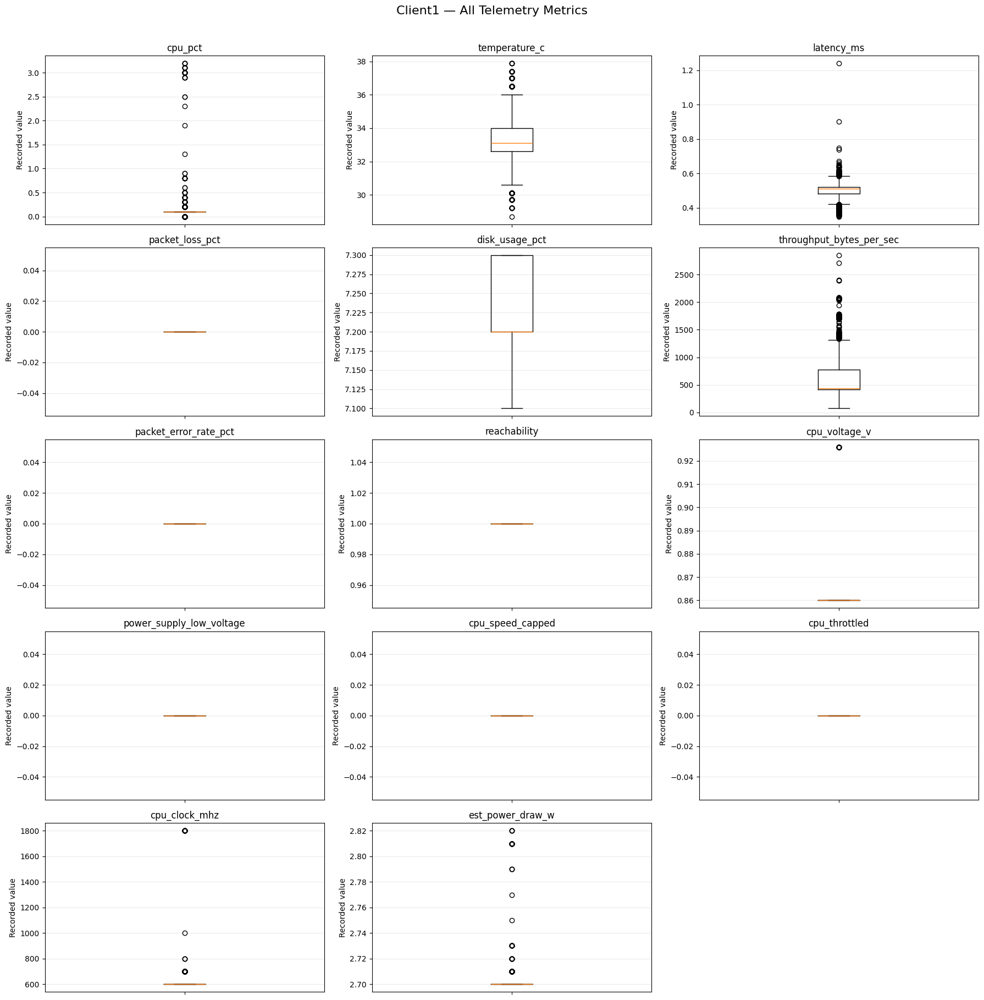

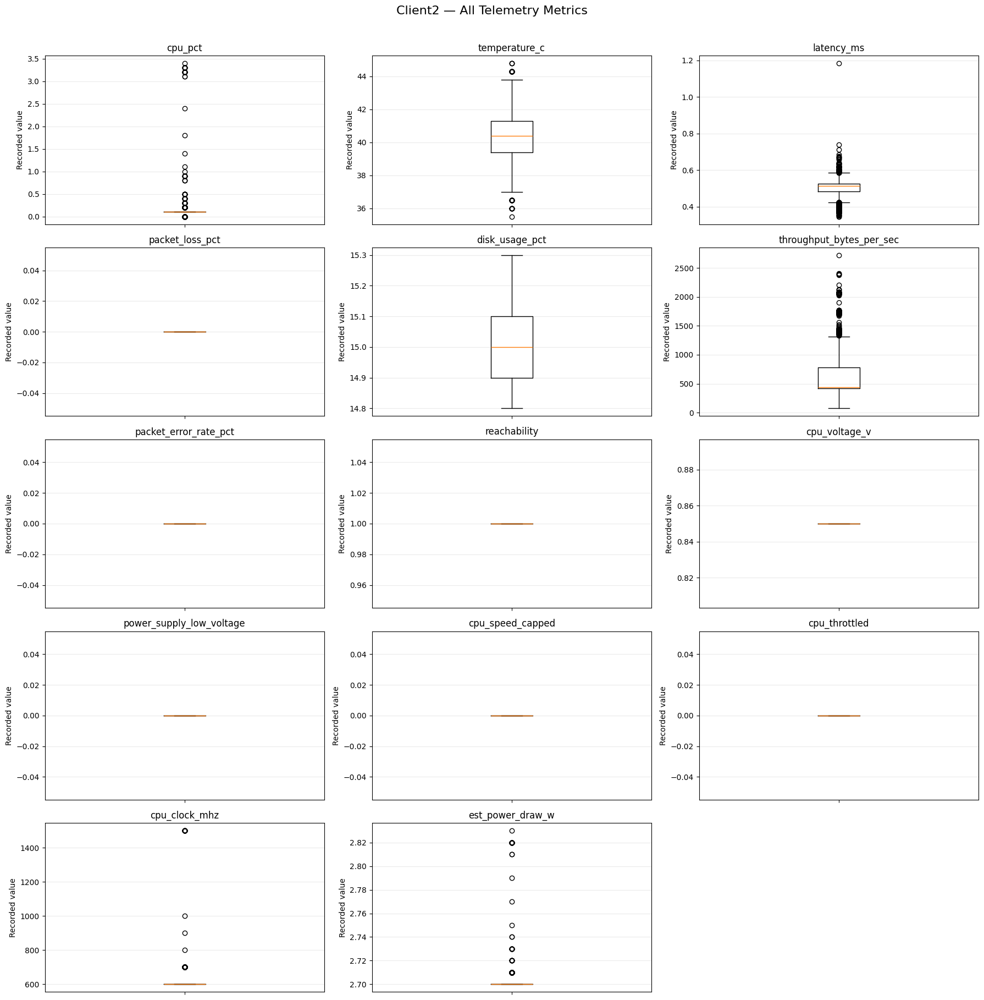

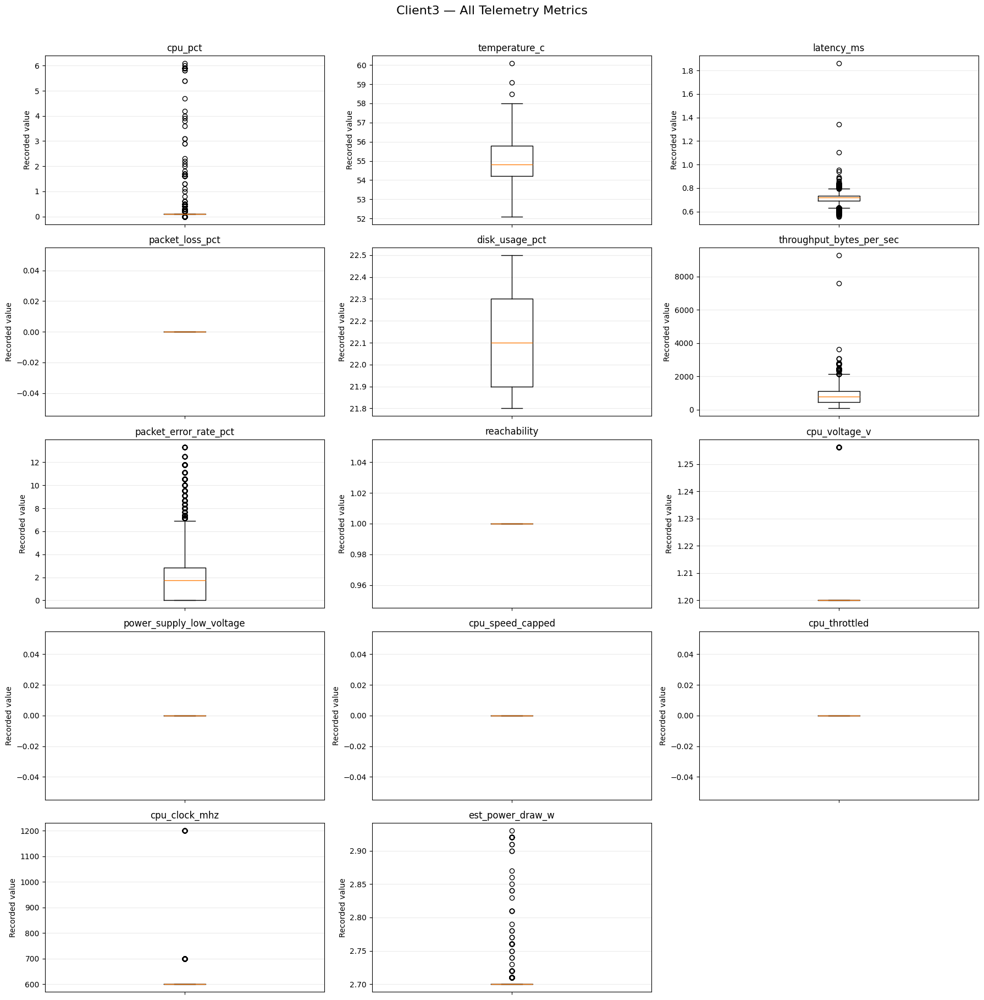

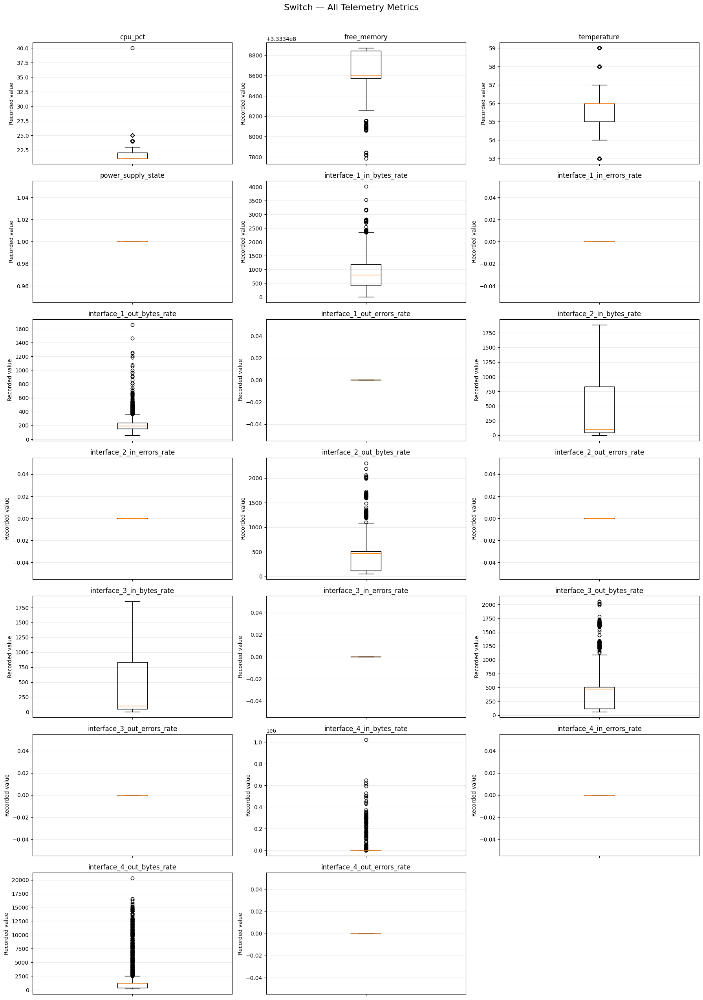


10.5 — Per-metric reconstruction errors


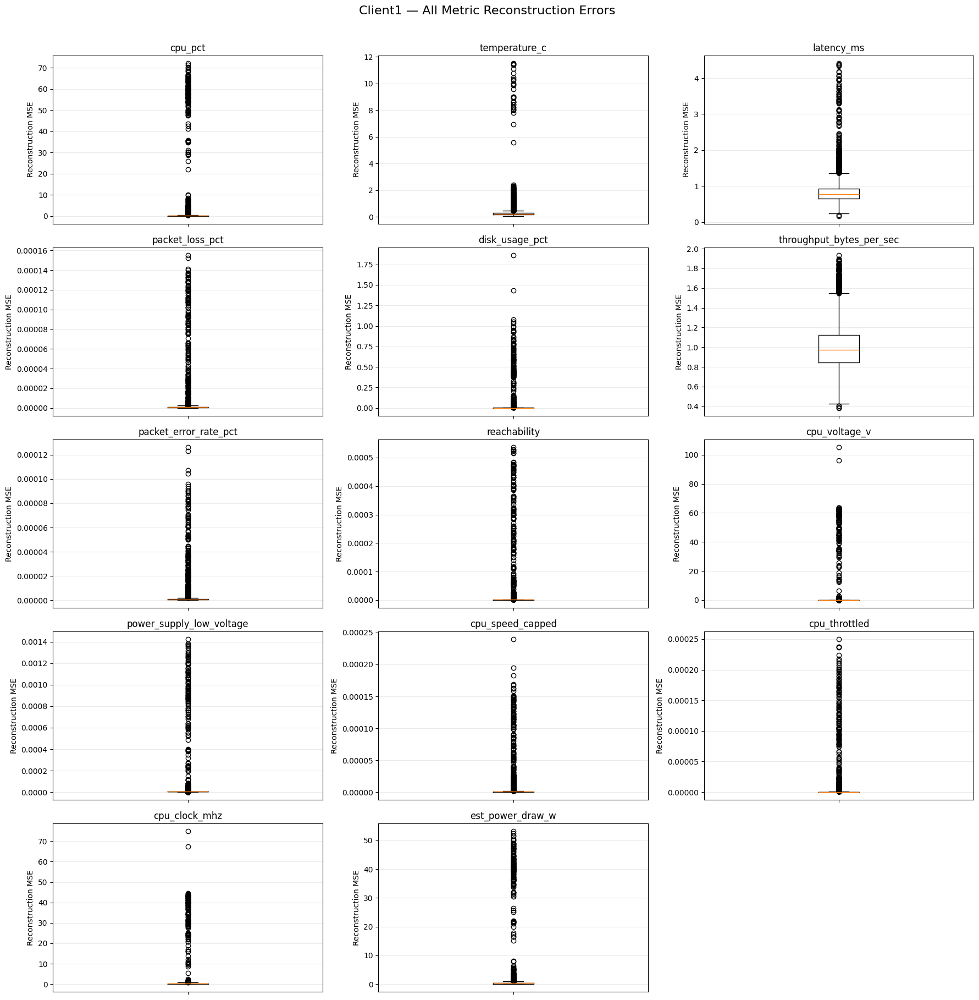

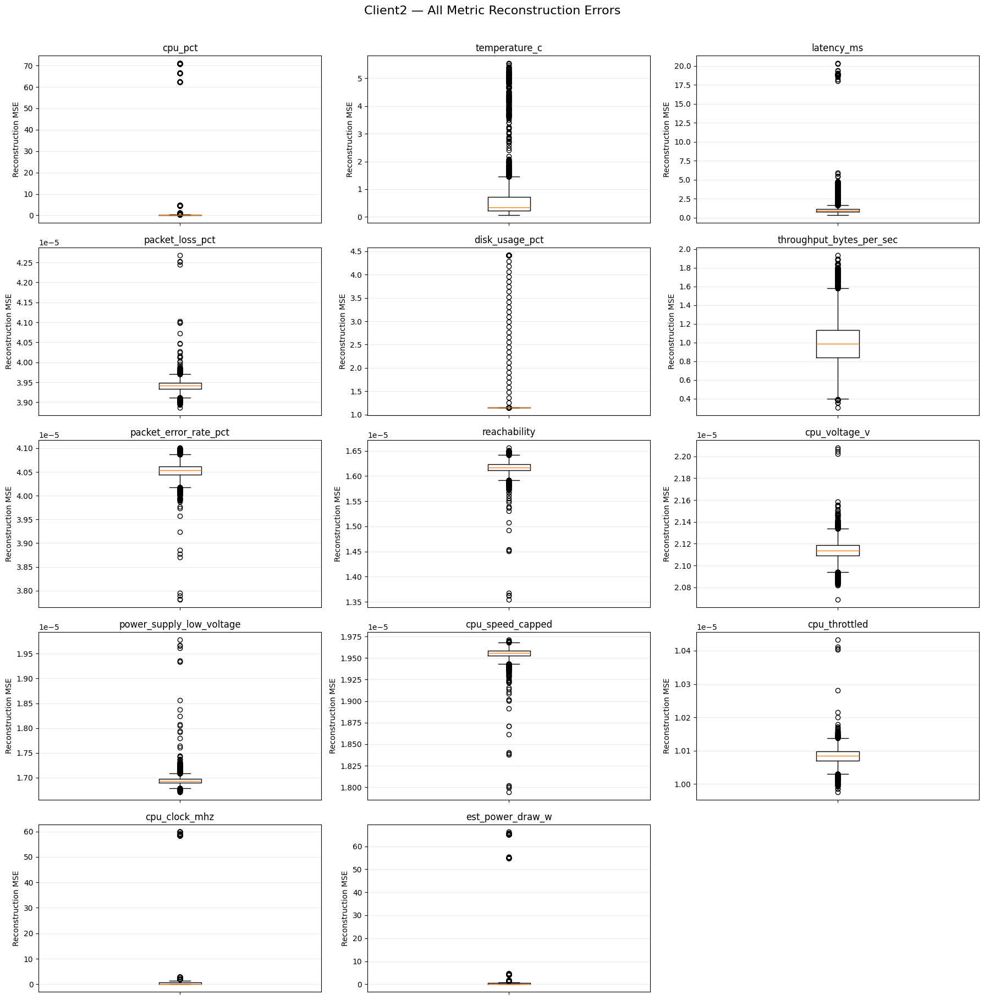

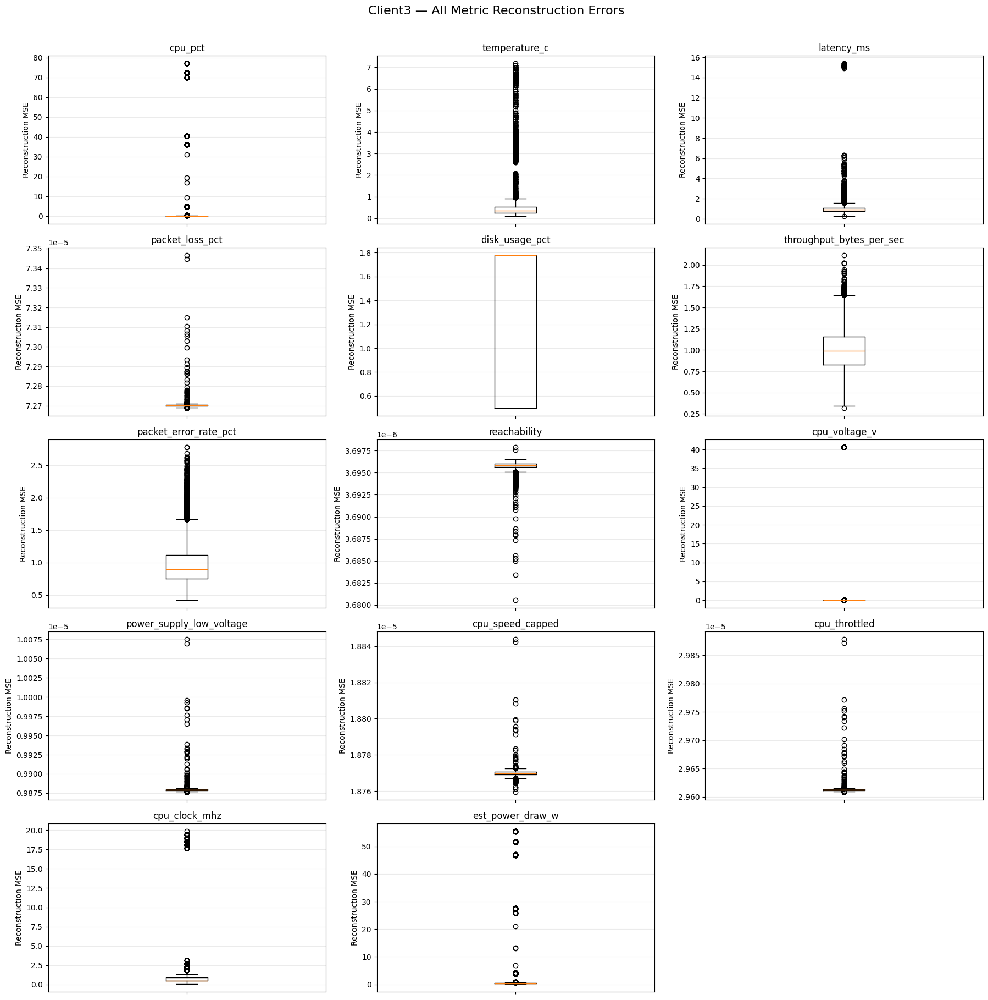

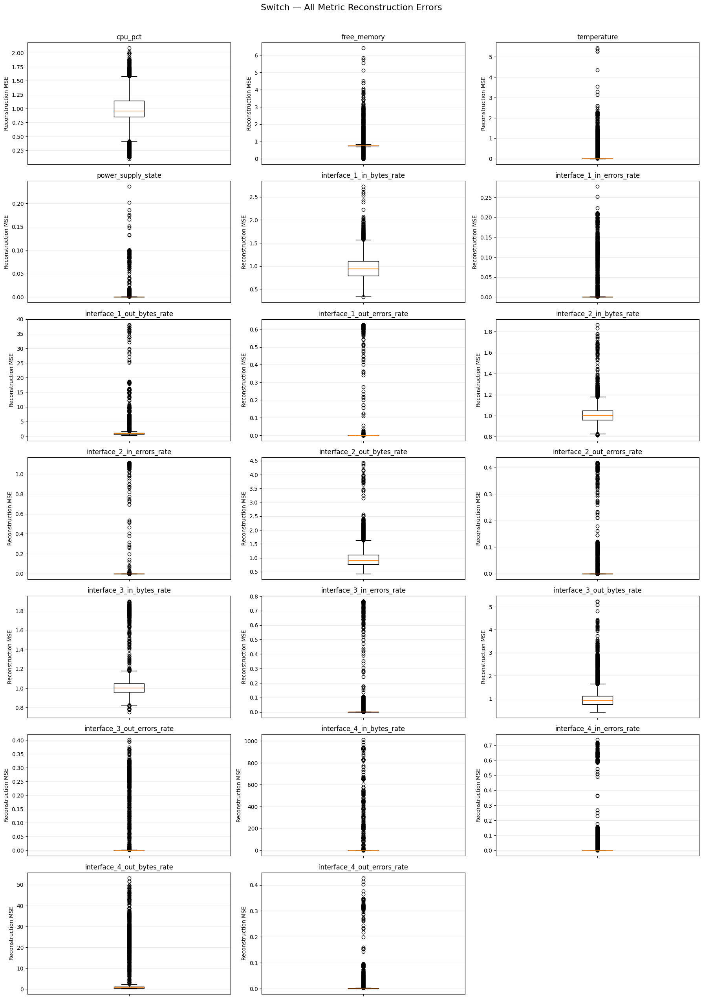


10.6 — Overall reconstruction-error comparison


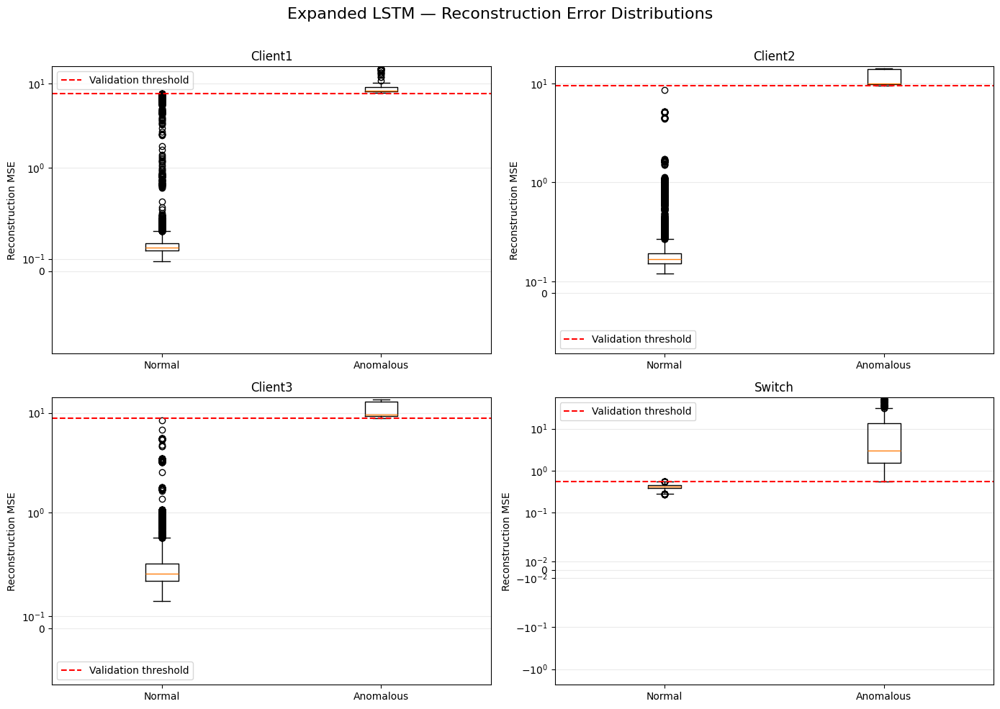


10.7 — Normalised error comparison


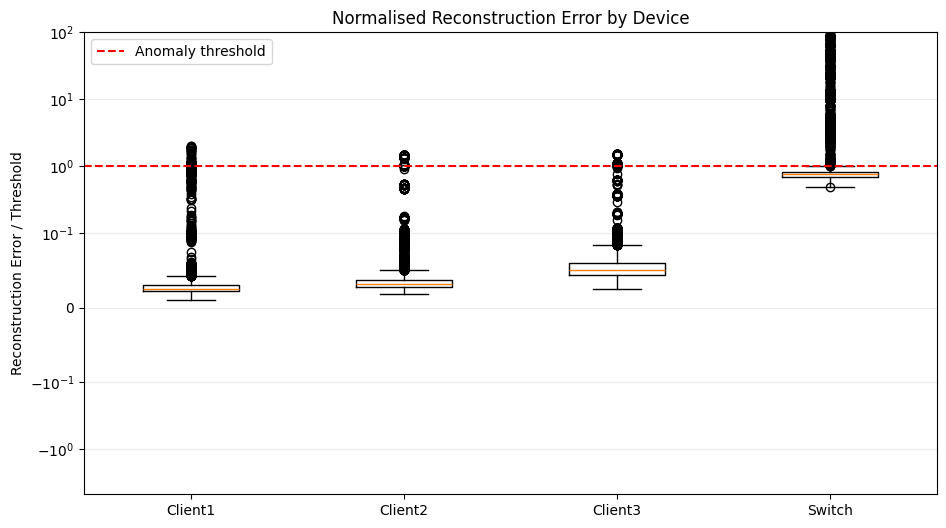


10.8 — Evaluating anomaly events

10.9 — Generating composite anomaly-event plots


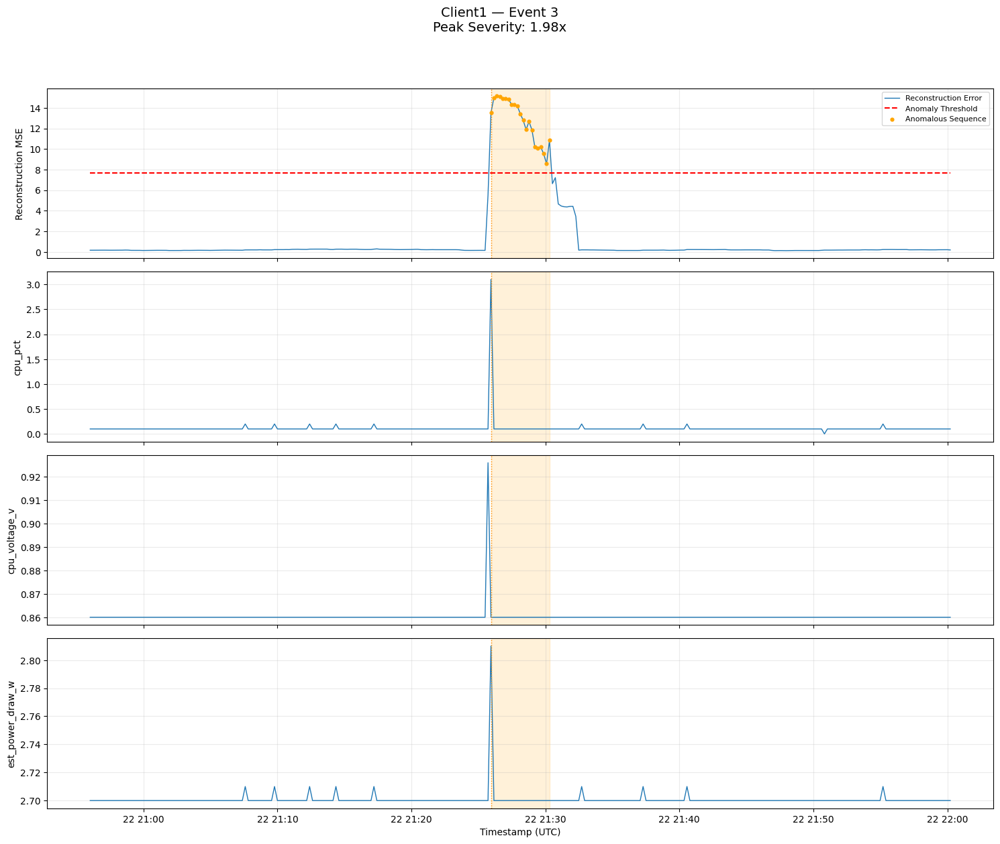

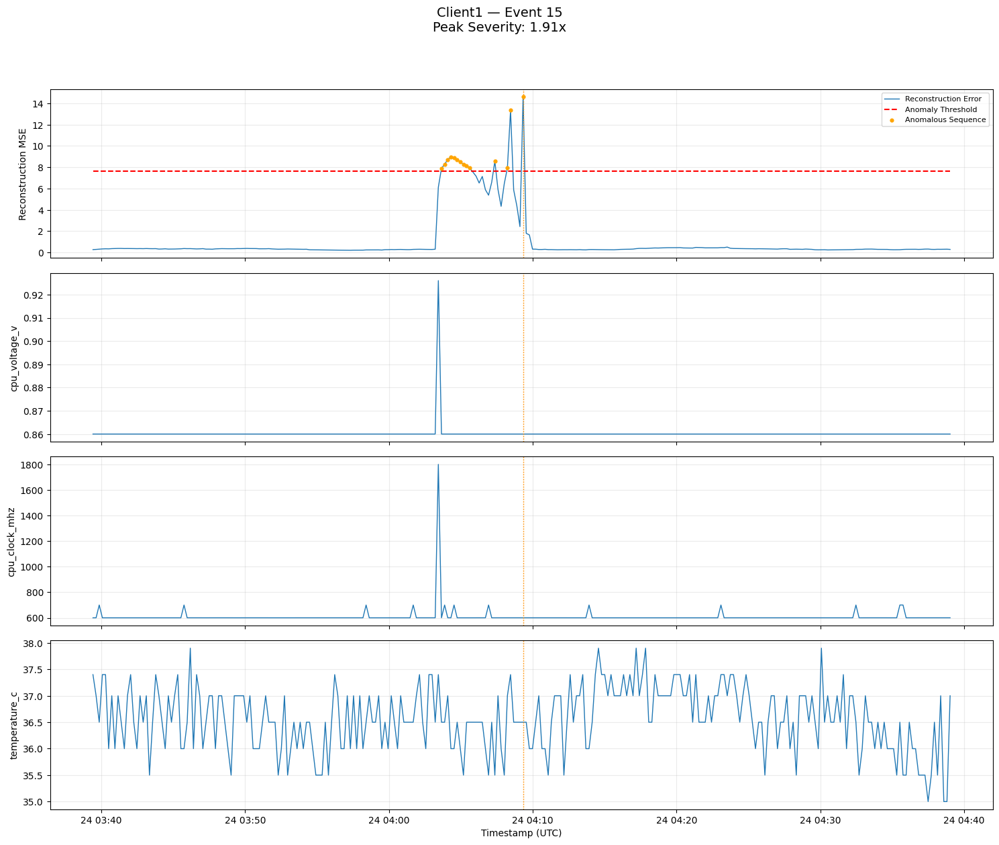

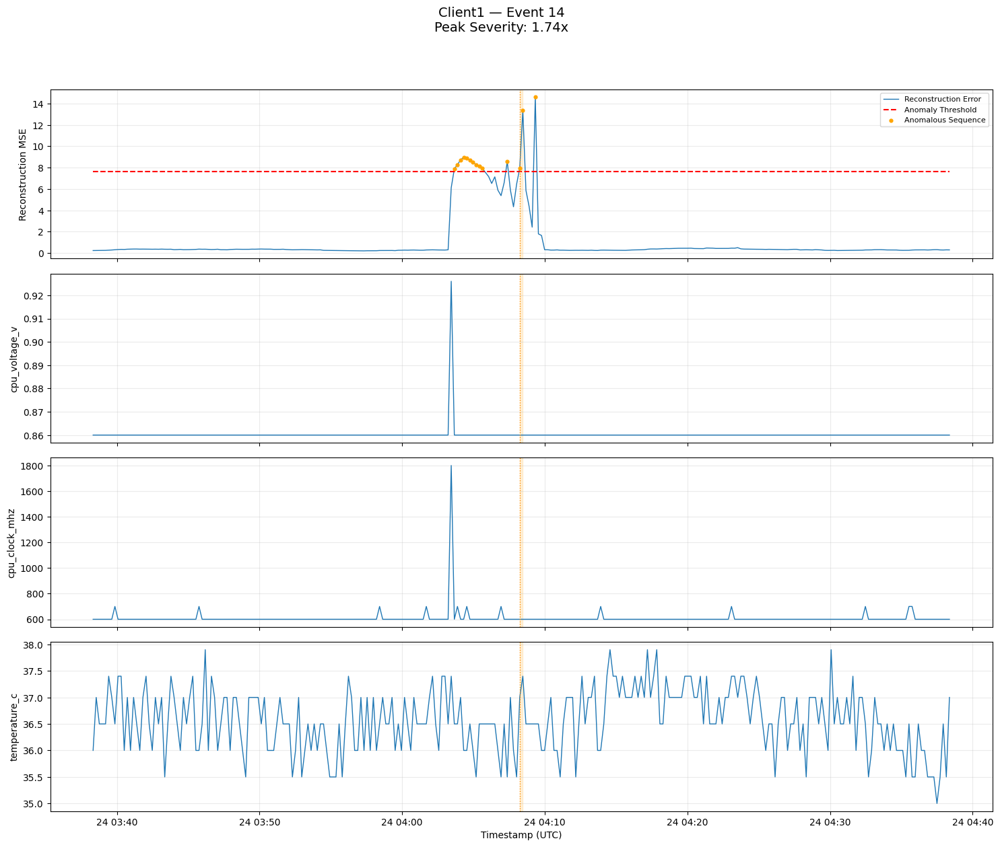

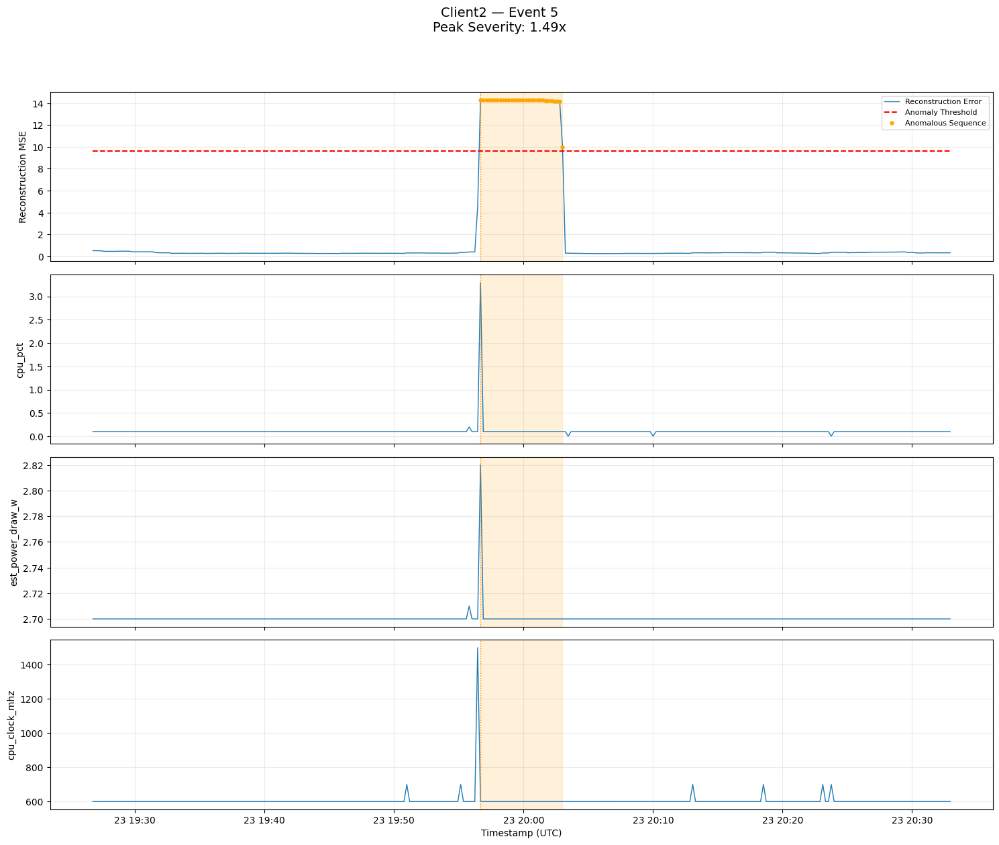

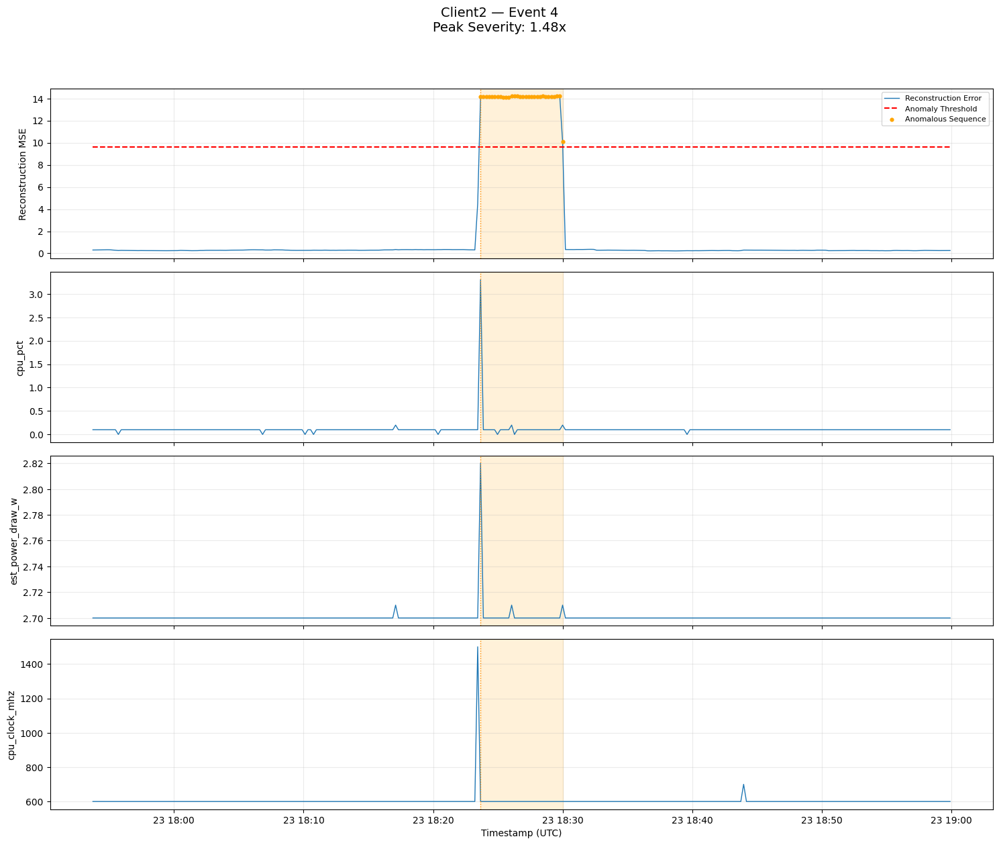

...

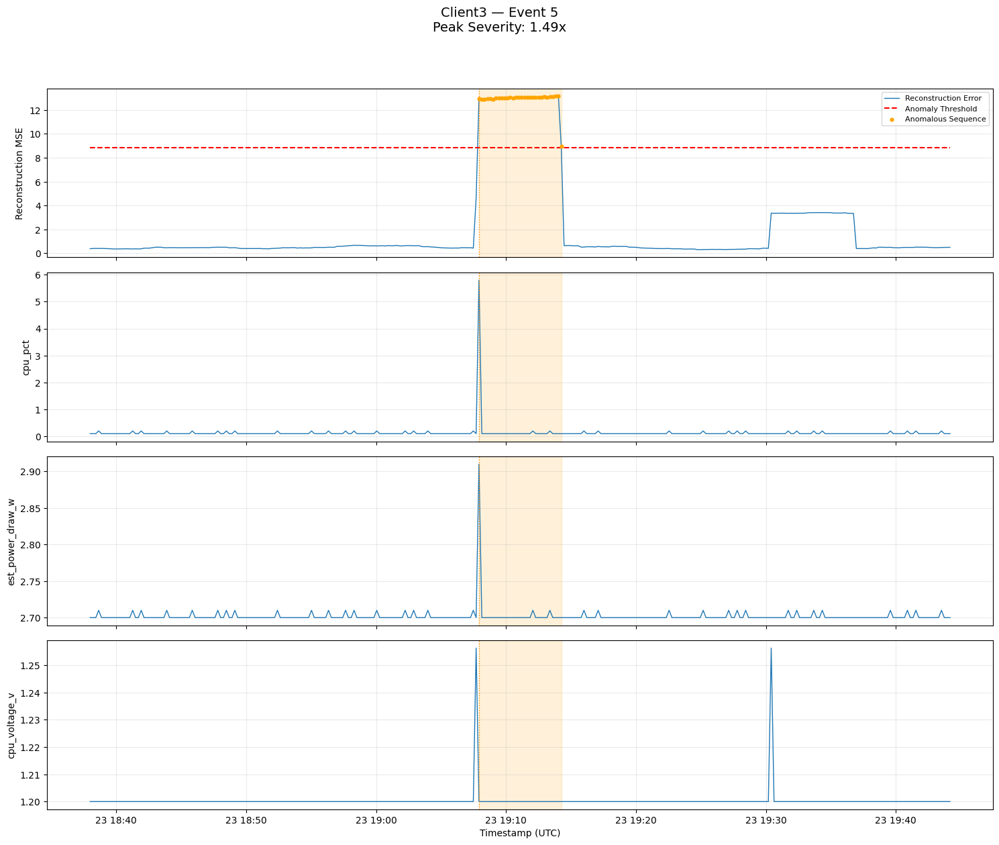

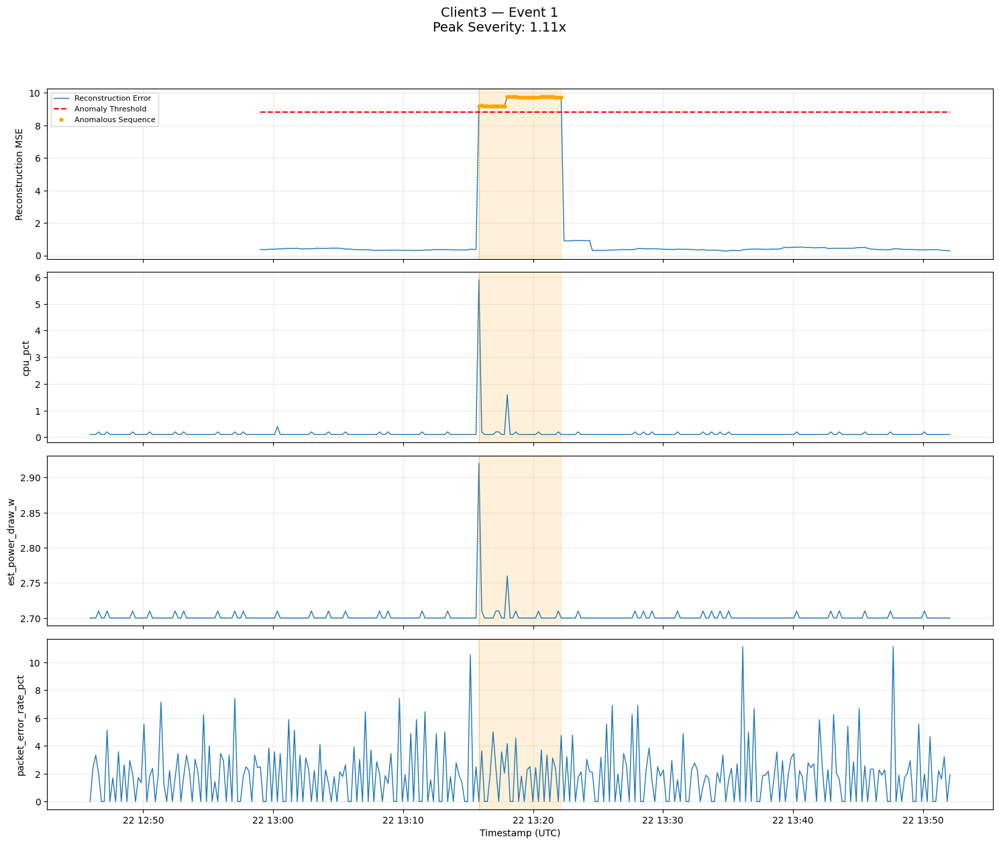

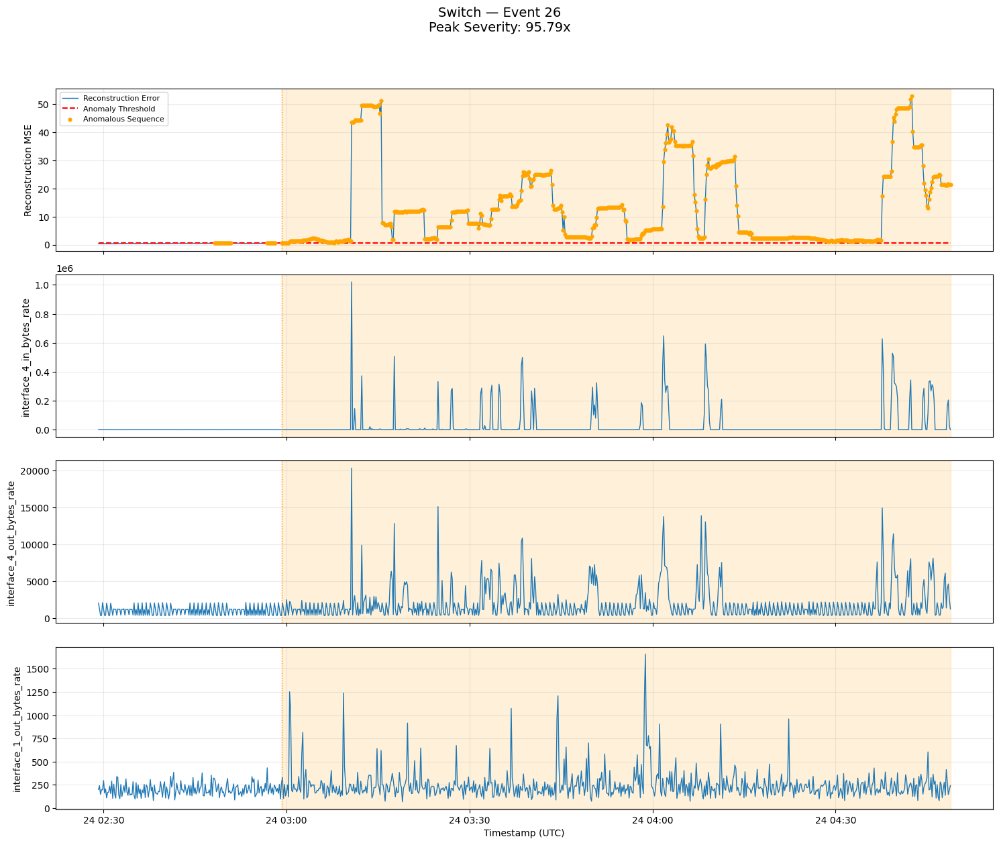

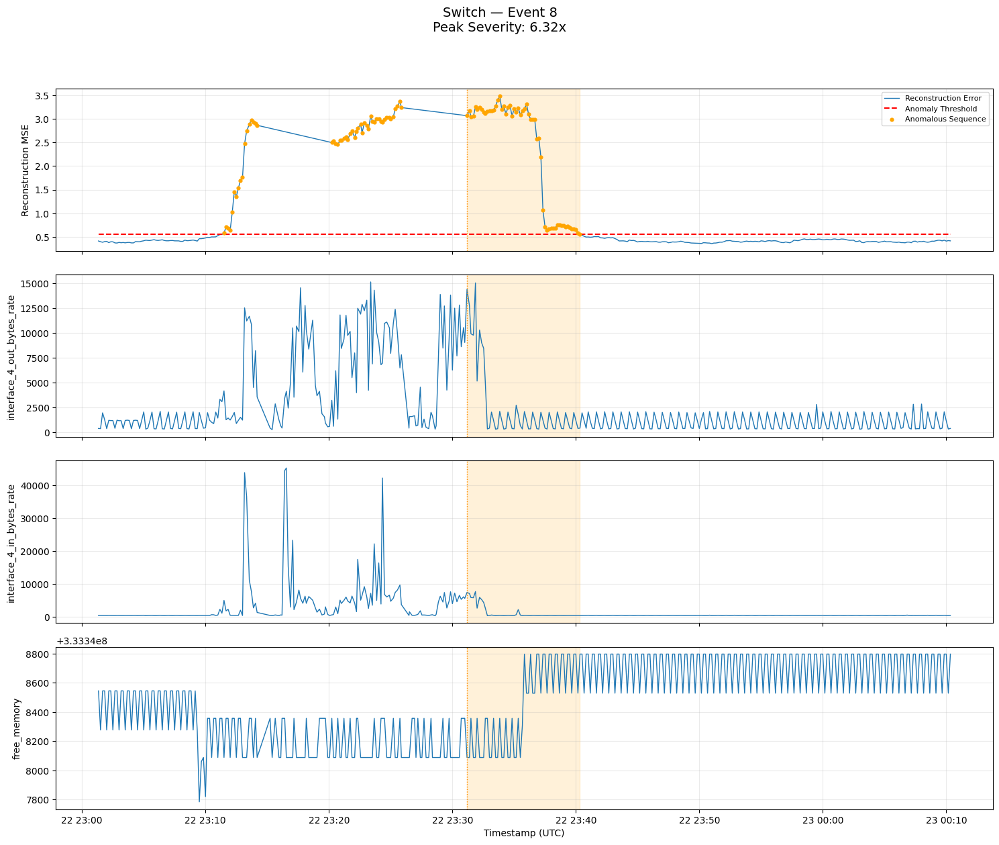

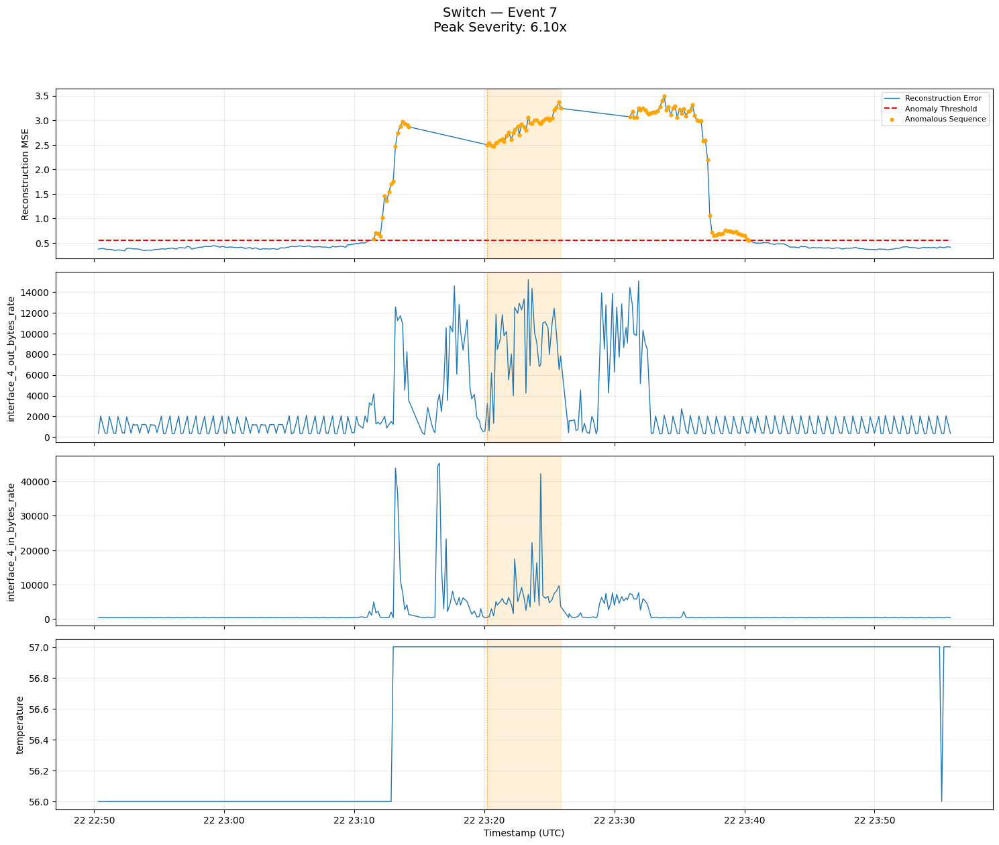


10.10 — Evaluating synthetic fault injections

10.11 — Generating fault detection plots


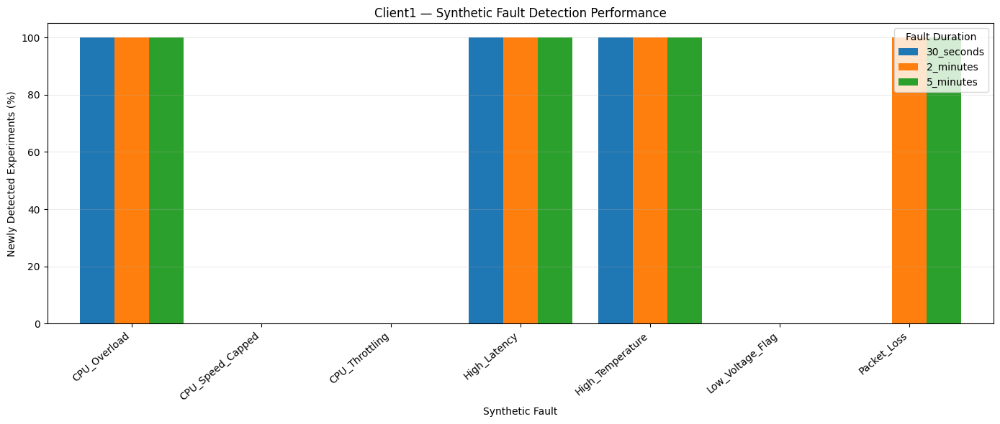

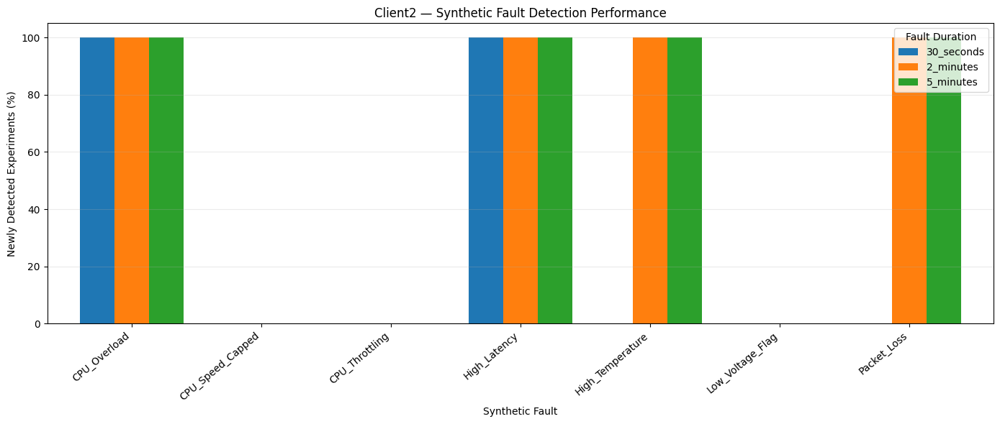

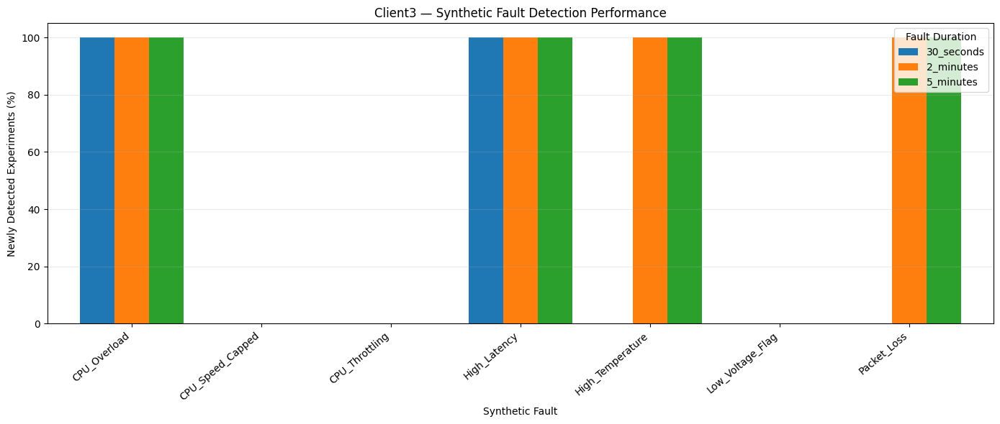

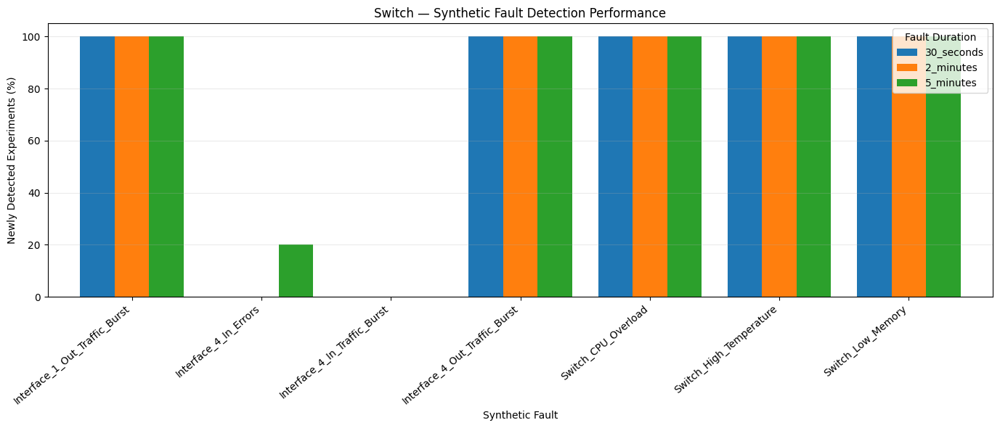


10.12 — Fault injection box plots


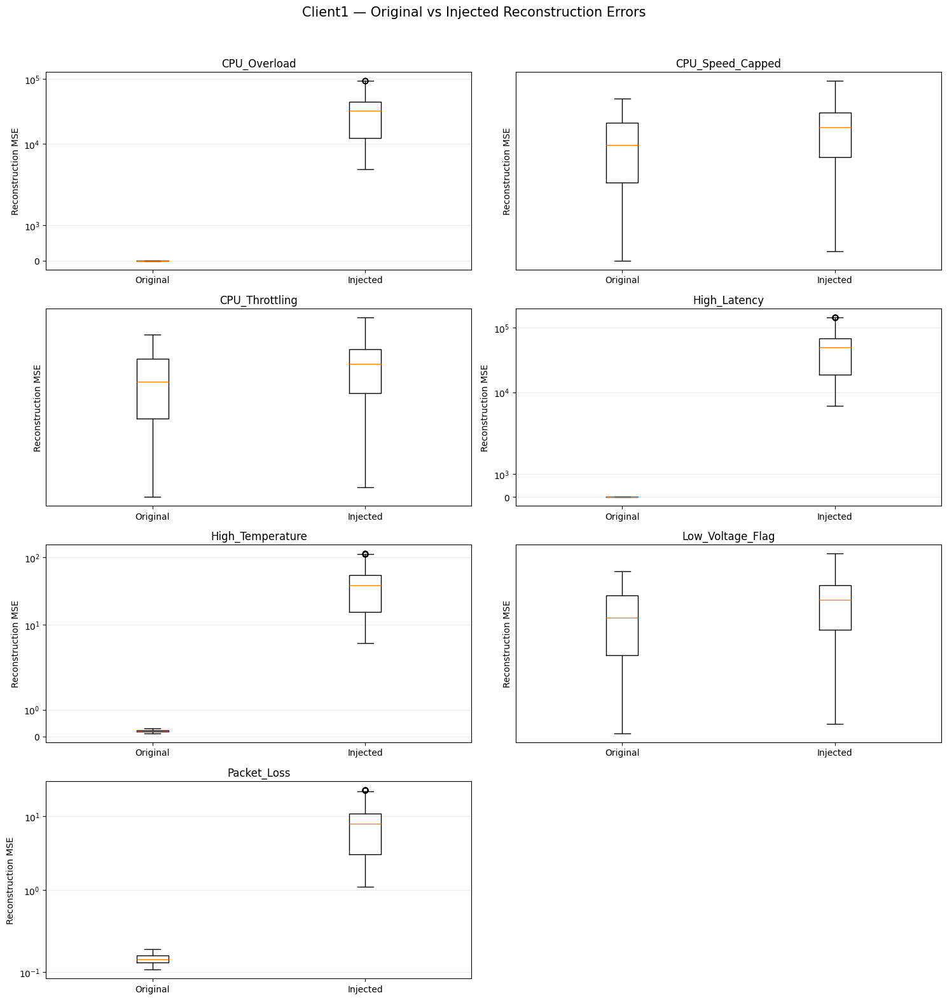

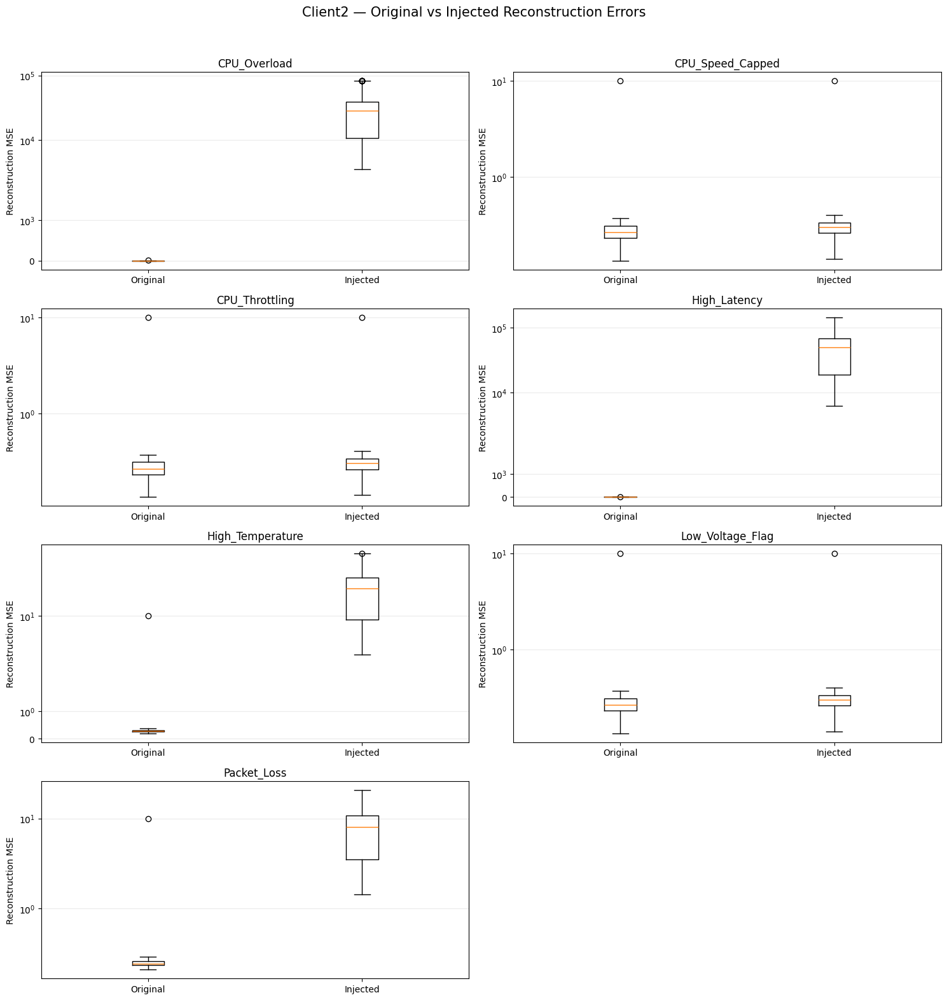

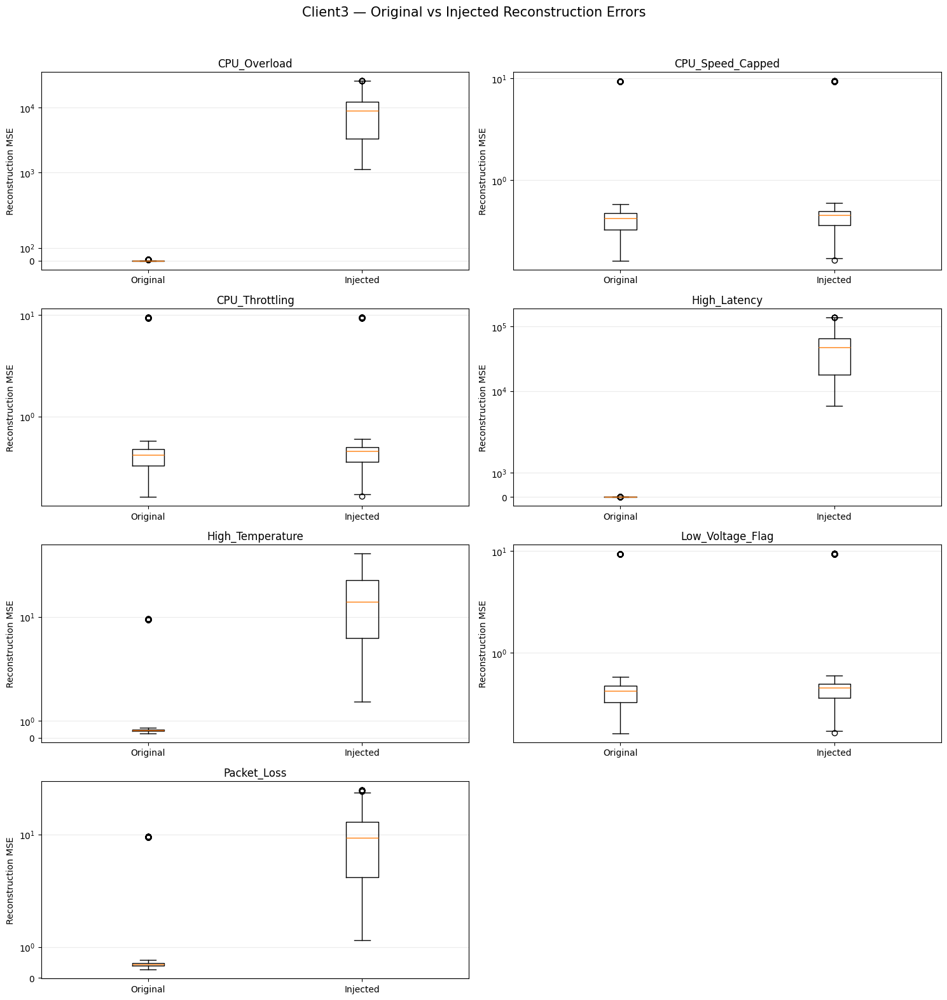

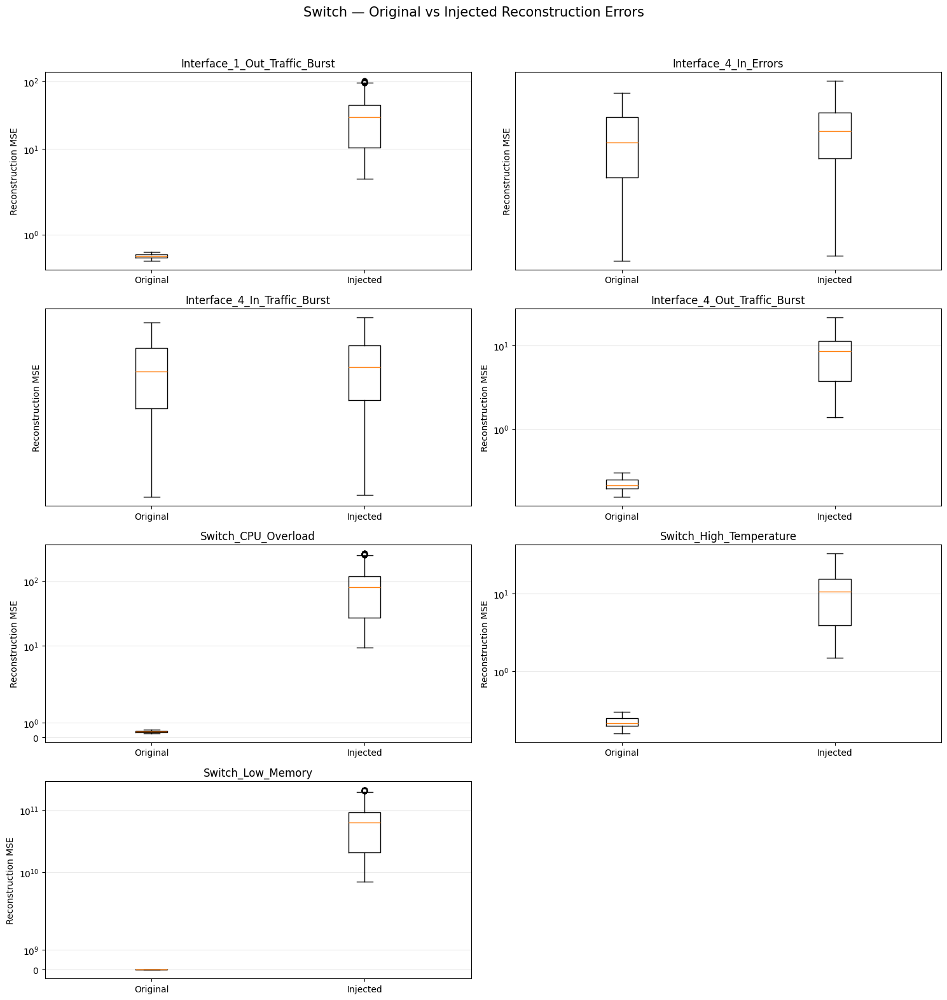


ORIGINAL LSTM:
c:\Users\alwyn\OneDrive\Documents\Year 3 - Semester 2\Capstone\LSTM_Results\Original_Fault_Injection\Original_All_Fault_Results.csv

EXPANDED LSTM:
c:\Users\alwyn\OneDrive\Documents\Year 3 - Semester 2\Capstone\Expanded_LSTM_Results\Fault_Injection\All_Fault_Injection_Results.csv

Both model result files loaded successfully.

Original columns:
['Experiment_ID', 'Device', 'Model', 'Fault', 'Metric', 'Duration', 'Duration_Seconds', 'Injection_Start', 'Injection_End', 'Injected_Value', 'Injected_Observations', 'Affected_Sequences', 'Original_Anomalies', 'Detected_Sequences', 'Newly_Detected_Sequences', 'Detected_Any', 'Newly_Detected_Any', 'Detection_Rate_Pct', 'New_Detection_Rate_Pct', 'Detection_Delay_Seconds', 'Original_Mean_Error', 'Injected_Mean_Error', 'Peak_Threshold_Ratio', 'Threshold']

Expanded columns:
['Experiment_ID', 'Device', 'Fault', 'Metric', 'Injected_Value', 'Duration', 'Duration_Seconds', 'Injection_Number', 'Injection_Start', 'Injection_End', 'Injected

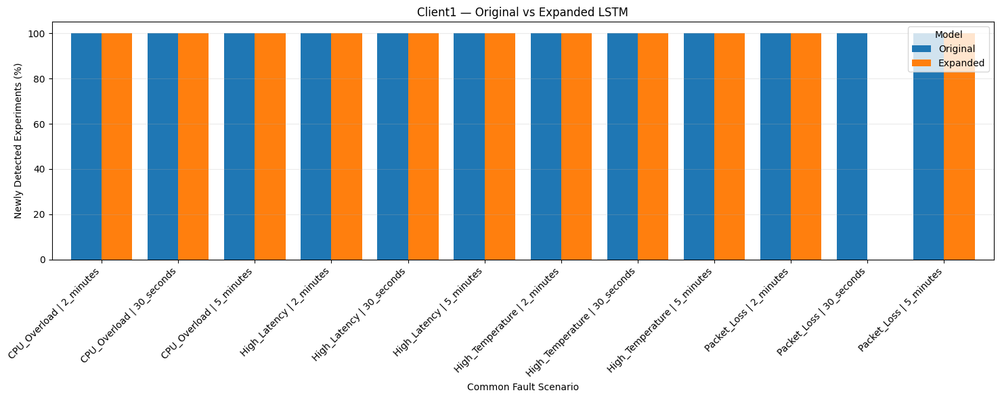

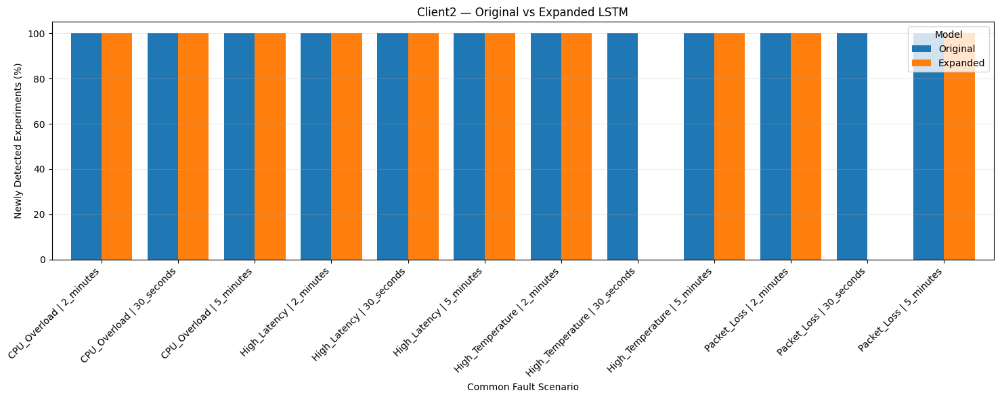

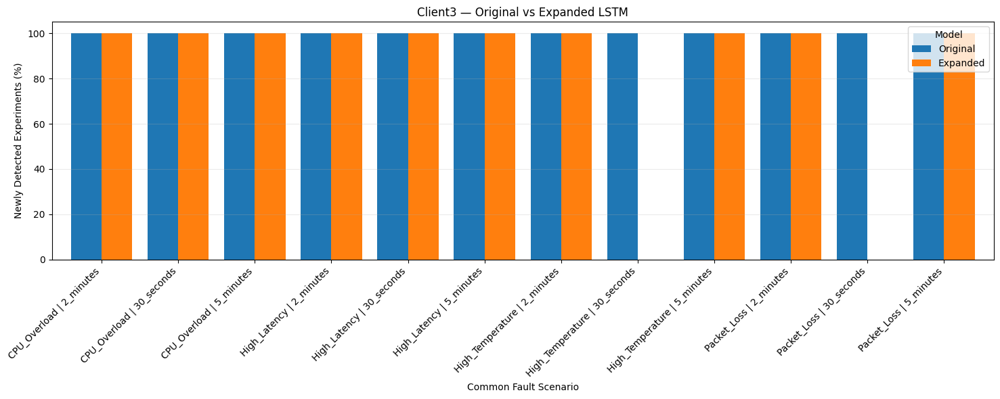

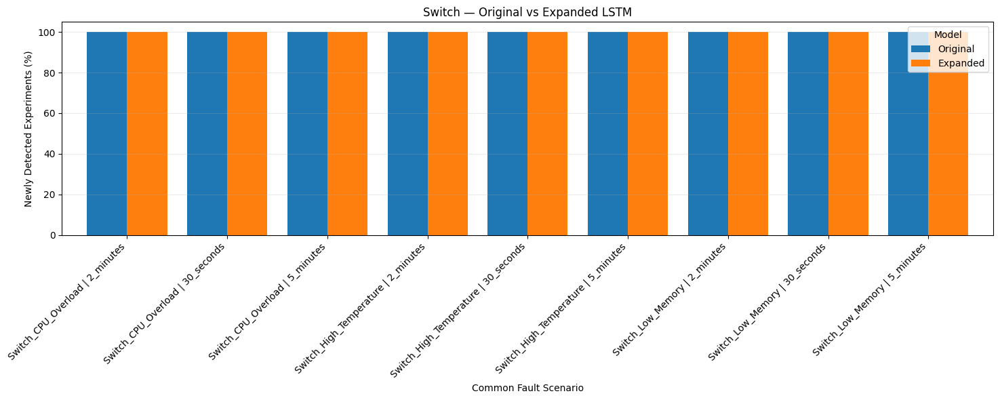


ORIGINAL VS EXPANDED LSTM COMPARISON
   Model  Experiments  Newly_Detected  Detection_Rate_Pct
Expanded          225             200           88.888889
Original          225             225          100.000000

Results saved to:
C:\Users\alwyn\OneDrive\Documents\Year 3 - Semester 2\Capstone\Expanded_LSTM_Results\Final_Evaluation\Model_Comparison

10.14 — Generating final results table

10.15 — Composite performance summary


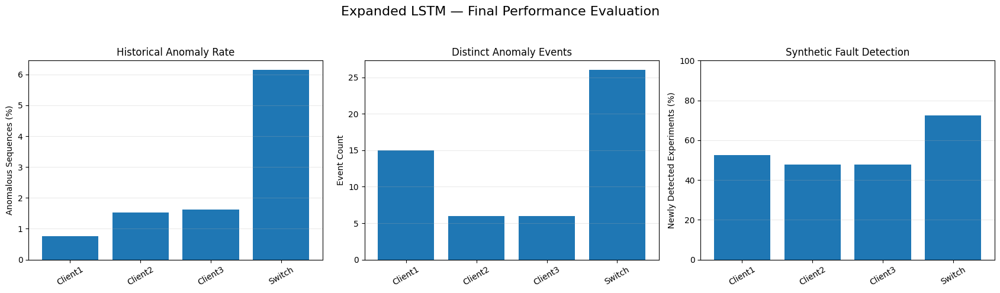


10.16 — Evaluating Capstone KPIs

CAPSTONE KPI SUMMARY:
 Device         Model  Synthetic_Recall_Pct  Synthetic_Recall_Target_Pct  Synthetic_Recall_Target_Met  Historical_Anomaly_Rate_Pct  False_Positive_Rate_Pct  Outperforms_Static_Thresholds  Data_Completeness_Pct  Total_Alerts  Attributed_Alerts  Explainability_Coverage_Pct
Client1 Expanded_LSTM             52.380952                         85.0                        False                     0.768115                      NaN                            NaN                    NaN            90                 90                        100.0
Client2 Expanded_LSTM             47.619048                         85.0                        False                     1.531223                      NaN                            NaN                    NaN           179                179                        100.0
Client3 Expanded_LSTM             47.619048                         85.0                        False                     1.624

In [12]:

# ================================================================
# SECTION 10 — FINAL RESULTS AND EVALUATION
# EXPANDED-METRIC LSTM AUTOENCODER
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.ticker import MaxNLocator
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

# ================================================================
# 10.1 CONFIGURATION
# ================================================================

DEVICES = ["Client1", "Client2", "Client3", "Switch"]

BASE_DIR = Path.cwd()

EXPANDED_DIR = BASE_DIR / "Expanded_LSTM_Results"
ORIGINAL_DIR = BASE_DIR / "LSTM_Results"

if not EXPANDED_DIR.exists():
    if "OUTPUT_DIR" in globals() and Path(OUTPUT_DIR).exists():
        EXPANDED_DIR = Path(OUTPUT_DIR)
    else:
        raise FileNotFoundError(
            "Expanded_LSTM_Results directory not found."
        )

FINAL_DIR = EXPANDED_DIR / "Final_Evaluation"

BOX_DIR = FINAL_DIR / "Box_Plots"
COMPOSITE_DIR = FINAL_DIR / "Composite_Plots"
FAULT_PLOT_DIR = FINAL_DIR / "Fault_Injection_Plots"
COMPARISON_DIR = FINAL_DIR / "Model_Comparison"
TABLE_DIR = FINAL_DIR / "Tables"

for folder in [
    FINAL_DIR,
    BOX_DIR,
    COMPOSITE_DIR,
    FAULT_PLOT_DIR,
    COMPARISON_DIR,
    TABLE_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

DPI = 200
SHOW_OUTLIERS = True
TOP_EVENTS = 3
CONTEXT_MINUTES = 30

COMMON_CLIENT_FAULTS = [
    "CPU_Overload",
    "High_Latency",
    "Packet_Loss",
    "High_Temperature"
]

COMMON_SWITCH_FAULTS = [
    "Switch_CPU_Overload",
    "Switch_High_Temperature",
    "Switch_Low_Memory"
]

DURATION_ORDER = [
    "30_seconds",
    "2_minutes",
    "5_minutes"
]

plt.rcParams.update({
    "figure.figsize": (12, 6),
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.grid": False
})

# ================================================================
# 10.2 GENERAL HELPER FUNCTIONS
# ================================================================

def numeric_values(values):
    return (
        pd.to_numeric(
            pd.Series(values), errors="coerce"
        )
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )


def bool_values(values):
    return (
        pd.Series(values)
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(["true", "1", "yes"])
    )


def safe_name(value):
    return "".join(
        c if c.isalnum() or c in "-_" else "_"
        for c in str(value)
    )


def save_plot(directory, filename):
    plt.savefig(
        directory / filename,
        dpi=DPI,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()


def valid_boxplot(ax, series_list, labels, title, ylabel):

    cleaned = [
        numeric_values(values).to_numpy()
        for values in series_list
    ]

    valid = [
        (values, label)
        for values, label in zip(cleaned, labels)
        if len(values) > 0
    ]

    if not valid:
        ax.text(
            0.5, 0.5, "No valid data",
            ha="center",
            va="center",
            transform=ax.transAxes
        )
        ax.set_title(title)
        return

    data, names = zip(*valid)

    ax.boxplot(
        data,
        tick_labels=names,
        showfliers=SHOW_OUTLIERS,
        patch_artist=False
    )

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.25)


def metric_statistics(values):

    values = numeric_values(values)

    if values.empty:
        return {
            "Samples": 0,
            "Min": np.nan,
            "Q1": np.nan,
            "Median": np.nan,
            "Q3": np.nan,
            "Max": np.nan,
            "Mean": np.nan,
            "Std": np.nan
        }

    return {
        "Samples": len(values),
        "Min": values.min(),
        "Q1": values.quantile(0.25),
        "Median": values.median(),
        "Q3": values.quantile(0.75),
        "Max": values.max(),
        "Mean": values.mean(),
        "Std": values.std()
    }


def find_file(root, filenames):

    if isinstance(filenames, str):
        filenames = [filenames]

    if not root.exists():
        return None

    for filename in filenames:
        matches = sorted(root.rglob(filename))
        if matches:
            return matches[0]

    return None


def get_telemetry(device):

    # Original-unit telemetry from Section 2.

    if "datasets" not in globals():
        return None

    if device not in datasets:
        return None

    df = datasets[device].copy()

    if "timestamp" not in df.columns:

        if "_time" in df.columns:
            df = df.rename(
                columns={"_time": "timestamp"}
            )
        else:
            return None

    df["timestamp"] = pd.to_datetime(
        df["timestamp"],
        utc=True,
        errors="coerce"
    )

    return (
        df.dropna(subset=["timestamp"])
        .sort_values("timestamp")
        .reset_index(drop=True)
    )


# ================================================================
# 10.3 LOAD SAVED RESULTS — CORRECTED
# ================================================================

anomaly_data = {}
event_data = {}
telemetry_data = {}

print("\nLoading expanded LSTM results...")

# ------------------------------------------------------------
# 10.3.1 Load anomaly results
# ------------------------------------------------------------

for device in DEVICES:

    anomaly_path = (
        EXPANDED_DIR
        / "Anomaly_Results"
        / f"{device}_Anomaly_Results.csv"
    )

    event_path = (
        EXPANDED_DIR
        / "Anomaly_Events"
        / f"{device}_Anomaly_Events.csv"
    )

    if not anomaly_path.exists():
        raise FileNotFoundError(anomaly_path)

    df = pd.read_csv(anomaly_path)

    df["timestamp"] = pd.to_datetime(
        df["timestamp"],
        utc=True
    )

    df["is_anomaly"] = bool_values(
        df["is_anomaly"]
    ).to_numpy()

    anomaly_data[device] = (
        df.sort_values("timestamp")
        .reset_index(drop=True)
    )

    # --------------------------------------------------------
    # Load anomaly events
    # --------------------------------------------------------

    if event_path.exists():

        events = pd.read_csv(event_path)

        if not events.empty:

            events["start_time"] = pd.to_datetime(
                events["start_time"],
                utc=True
            )

            events["end_time"] = pd.to_datetime(
                events["end_time"],
                utc=True
            )

        event_data[device] = events

    else:
        event_data[device] = pd.DataFrame()

    telemetry_data[device] = get_telemetry(device)

    print(
        f"{device}: "
        f"{len(anomaly_data[device])} test sequences"
    )

# ------------------------------------------------------------
# 10.3.2 Locate expanded fault injection results
# ------------------------------------------------------------

# Supports both original and revised Section 9 filenames.

fault_filenames = [
    "All_Fault_Injection_Results.csv",
    "AllMetrics_Fault_Results.csv"
]

sequence_filenames = [
    "All_Fault_Sequence_Results.csv",
    "AllMetrics_Sequence_Results.csv"
]

search_directories = [
    EXPANDED_DIR,
    BASE_DIR / "LSTM_Results" / "All_Metrics_Fault_Injection"
]

expanded_fault_file = None
expanded_sequence_file = None

for directory in search_directories:

    if expanded_fault_file is None:
        expanded_fault_file = find_file(
            directory,
            fault_filenames
        )

    if expanded_sequence_file is None:
        expanded_sequence_file = find_file(
            directory,
            sequence_filenames
        )

if expanded_fault_file is None:

    print("\nFault result files found in project:")

    for path in BASE_DIR.rglob("*Fault*Results.csv"):
        print(path.resolve())

    raise FileNotFoundError(
        "Expanded fault injection results not found. "
        "Run the expanded LSTM Section 9 first."
    )

# ------------------------------------------------------------
# 10.3.3 Load fault experiment results
# ------------------------------------------------------------

fault_results = pd.read_csv(
    expanded_fault_file
)

fault_sequences = (
    pd.read_csv(expanded_sequence_file)
    if expanded_sequence_file is not None
    else pd.DataFrame()
)

if fault_results.empty:
    raise ValueError("Fault experiment file is empty.")

required_columns = [
    "Device",
    "Fault",
    "Duration",
    "Experiment_ID",
    "Detected_Any",
    "Newly_Detected_Any",
    "Detection_Delay_Seconds"
]

missing_columns = [
    col for col in required_columns
    if col not in fault_results.columns
]

if missing_columns:
    raise ValueError(
        f"Missing fault result columns: {missing_columns}"
    )

for col in ["Detected_Any", "Newly_Detected_Any"]:
    fault_results[col] = bool_values(
        fault_results[col]
    ).to_numpy()

if not fault_sequences.empty:

    for col in [
        "original_error",
        "injected_error"
    ]:
        if col not in fault_sequences.columns:
            raise ValueError(
                f"Missing sequence result column: {col}"
            )

print("\n" + "=" * 70)
print("SECTION 10 — FINAL RESULTS AND EVALUATION")
print("=" * 70)

print("Expanded models:", len(anomaly_data))
print("Fault experiments:", len(fault_results))
print("Fault sequence records:", len(fault_sequences))
print("Fault result file:", expanded_fault_file.resolve())
print("Output directory:", FINAL_DIR.resolve())


# ================================================================
# 10.4 RAW TELEMETRY — ALL METRIC BOX PLOTS
# ================================================================

print("\n10.4 — Generating telemetry box plots")

telemetry_stats = []

for device in DEVICES:

    telemetry = telemetry_data[device]

    if telemetry is None:
        print(
            f"{device}: Raw telemetry unavailable. "
            "Skipping telemetry plots."
        )
        continue

    if (
        "device_metrics" in globals()
        and device in device_metrics
    ):
        metrics = list(device_metrics[device])

    else:
        metrics = [
            col for col in telemetry.columns
            if col not in [
                "timestamp",
                "device_id",
                "device_type"
            ]
            and pd.api.types.is_numeric_dtype(
                telemetry[col]
            )
        ]

    metrics = [
        metric for metric in metrics
        if metric in telemetry.columns
    ]

    if not metrics:
        continue

    columns = 3
    rows = int(np.ceil(len(metrics) / columns))

    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(18, rows * 3.7),
        squeeze=False
    )

    axes = axes.flatten()

    for index, metric in enumerate(metrics):

        ax = axes[index]

        values = numeric_values(
            telemetry[metric]
        )

        valid_boxplot(
            ax,
            [values],
            [metric],
            metric,
            "Recorded value"
        )

        ax.tick_params(
            axis="x",
            labelbottom=False
        )

        stats = metric_statistics(values)

        stats.update({
            "Device": device,
            "Metric": metric
        })

        telemetry_stats.append(stats)

    for ax in axes[len(metrics):]:
        ax.set_visible(False)

    fig.suptitle(
        f"{device} — All Telemetry Metrics",
        fontsize=16
    )

    fig.tight_layout(rect=[0, 0, 1, 0.97])

    save_plot(
        BOX_DIR,
        f"{device}_All_Telemetry_Boxplots.png"
    )

telemetry_stats_df = pd.DataFrame(
    telemetry_stats
)

telemetry_stats_df.to_csv(
    TABLE_DIR / "All_Telemetry_Statistics.csv",
    index=False
)


# ================================================================
# 10.5 ALL METRIC RECONSTRUCTION-ERROR BOX PLOTS
# ================================================================

print("\n10.5 — Per-metric reconstruction errors")

metric_error_stats = []

for device in DEVICES:

    results = anomaly_data[device]

    metric_columns = [
        col for col in results.columns
        if col.endswith("_error")
        and col not in [
            "reconstruction_error",
            "most_unusual_metric_error"
        ]
    ]

    if not metric_columns:
        print(
            f"{device}: No per-metric error columns found."
        )
        continue

    columns = 3
    rows = int(np.ceil(len(metric_columns) / columns))

    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(18, rows * 3.7),
        squeeze=False
    )

    axes = axes.flatten()

    for index, column in enumerate(metric_columns):

        metric = column.removesuffix("_error")

        values = numeric_values(
            results[column]
        )

        ax = axes[index]

        valid_boxplot(
            ax,
            [values],
            [metric],
            metric,
            "Reconstruction MSE"
        )

        ax.tick_params(
            axis="x",
            labelbottom=False
        )

        stats = metric_statistics(values)

        stats.update({
            "Device": device,
            "Metric": metric
        })

        metric_error_stats.append(stats)

    for ax in axes[len(metric_columns):]:
        ax.set_visible(False)

    fig.suptitle(
        f"{device} — All Metric Reconstruction Errors",
        fontsize=16
    )

    fig.tight_layout(rect=[0, 0, 1, 0.97])

    save_plot(
        BOX_DIR,
        f"{device}_All_Metric_Error_Boxplots.png"
    )

metric_error_stats_df = pd.DataFrame(
    metric_error_stats
)

metric_error_stats_df.to_csv(
    TABLE_DIR / "All_Metric_Error_Statistics.csv",
    index=False
)


# ================================================================
# 10.6 OVERALL RECONSTRUCTION ERROR BOX PLOTS
# ================================================================

print("\n10.6 — Overall reconstruction-error comparison")

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

device_summary = []

for ax, device in zip(axes.flatten(), DEVICES):

    results = anomaly_data[device]

    threshold = float(
        results["threshold"].iloc[0]
    )

    errors = numeric_values(
        results["reconstruction_error"]
    )

    normal = results.loc[
        ~results["is_anomaly"],
        "reconstruction_error"
    ]

    abnormal = results.loc[
        results["is_anomaly"],
        "reconstruction_error"
    ]

    valid_boxplot(
        ax,
        [normal, abnormal],
        ["Normal", "Anomalous"],
        device,
        "Reconstruction MSE"
    )

    ax.axhline(
        threshold,
        color="red",
        linestyle="--",
        label="Validation threshold"
    )

    ax.set_yscale(
        "symlog",
        linthresh=max(abs(threshold) / 10, 1e-6)
    )

    ax.legend()

    anomaly_count = int(
        results["is_anomaly"].sum()
    )

    device_summary.append({
        "Device": device,
        "Test_Sequences": len(results),
        "Anomalous_Sequences": anomaly_count,
        "Anomaly_Rate_Pct": (
            anomaly_count / len(results) * 100
        ),
        "Threshold": threshold,
        "Mean_Test_Error": errors.mean(),
        "Median_Test_Error": errors.median(),
        "P99_Test_Error": errors.quantile(0.99),
        "Maximum_Test_Error": errors.max()
    })

fig.suptitle(
    "Expanded LSTM — Reconstruction Error Distributions",
    fontsize=16
)

fig.tight_layout(rect=[0, 0, 1, 0.97])

save_plot(
    BOX_DIR,
    "All_Device_Reconstruction_Error_Boxplots.png"
)

device_summary_df = pd.DataFrame(
    device_summary
)


# ================================================================
# 10.7 NORMALISED RECONSTRUCTION ERROR COMPARISON
# ================================================================

print("\n10.7 — Normalised error comparison")

normalised_error_data = []

for device in DEVICES:

    results = anomaly_data[device]

    threshold = float(
        results["threshold"].iloc[0]
    )

    if threshold <= 0:
        raise ValueError(
            f"{device}: Invalid reconstruction threshold"
        )

    ratios = (
        results["reconstruction_error"] / threshold
    )

    normalised_error_data.append(
        numeric_values(ratios)
    )

fig, ax = plt.subplots(figsize=(11, 6))

valid_boxplot(
    ax,
    normalised_error_data,
    DEVICES,
    "Normalised Reconstruction Error by Device",
    "Reconstruction Error / Threshold"
)

ax.axhline(
    1.0,
    color="red",
    linestyle="--",
    label="Anomaly threshold"
)

ax.set_yscale(
    "symlog",
    linthresh=0.1
)

ax.legend()

save_plot(
    BOX_DIR,
    "Normalised_Device_Error_Comparison.png"
)


# ================================================================
# 10.8 ANOMALY EVENT EVALUATION
# ================================================================

print("\n10.8 — Evaluating anomaly events")

event_summary = []
combined_events = []

for device in DEVICES:

    events = event_data[device]

    if events.empty:

        event_summary.append({
            "Device": device,
            "Total_Events": 0,
            "Longest_Event_Minutes": 0,
            "Highest_Severity_Ratio": np.nan,
            "Strongest_Event_ID": np.nan,
            "Dominant_Metric": "N/A"
        })

        continue

    events = events.copy()
    events["Device"] = device

    combined_events.append(events)

    strongest = events.loc[
        events["peak_threshold_ratio"].idxmax()
    ]

    event_summary.append({
        "Device": device,
        "Total_Events": len(events),
        "Longest_Event_Minutes": events[
            "duration_minutes"
        ].max(),
        "Highest_Severity_Ratio": events[
            "peak_threshold_ratio"
        ].max(),
        "Strongest_Event_ID": strongest["event_id"],
        "Dominant_Metric": strongest["dominant_metric"]
    })

event_summary_df = pd.DataFrame(
    event_summary
)

event_summary_df.to_csv(
    TABLE_DIR / "Final_Event_Summary.csv",
    index=False
)

if combined_events:

    all_events_df = pd.concat(
        combined_events,
        ignore_index=True
    )

    all_events_df = all_events_df.sort_values(
        "peak_threshold_ratio",
        ascending=False
    )

    all_events_df.to_csv(
        TABLE_DIR / "All_Events_Ranked.csv",
        index=False
    )


# ================================================================
# 10.9 COMPOSITE ANOMALY EVENT GRAPHS
# ================================================================

print("\n10.9 — Generating composite anomaly-event plots")

for device in DEVICES:

    events = event_data[device]
    results = anomaly_data[device]
    telemetry = telemetry_data[device]

    if events.empty or telemetry is None:
        continue

    selected_events = (
        events.sort_values(
            "peak_threshold_ratio",
            ascending=False
        )
        .head(TOP_EVENTS)
    )

    for _, event in selected_events.iterrows():

        event_id = int(event["event_id"])

        start = event["start_time"]
        end = event["end_time"]

        plot_start = (
            start - pd.Timedelta(
                minutes=CONTEXT_MINUTES
            )
        )

        plot_end = (
            end + pd.Timedelta(
                minutes=CONTEXT_MINUTES
            )
        )

        # ----------------------------------------------------
        # Extract reconstruction errors around event
        # ----------------------------------------------------

        error_window = results.loc[
            (results["timestamp"] >= plot_start)
            & (results["timestamp"] <= plot_end)
        ]

        # ----------------------------------------------------
        # Extract original telemetry around event
        # ----------------------------------------------------

        telemetry_window = telemetry.loc[
            (telemetry["timestamp"] >= plot_start)
            & (telemetry["timestamp"] <= plot_end)
        ]

        candidate_metrics = [
            str(event["dominant_metric"])
        ]

        if pd.notna(event.get("top_3_metrics")):

            candidate_metrics.extend(
                str(event["top_3_metrics"]).split(",")
            )

        candidate_metrics = [
            metric.strip()
            for metric in candidate_metrics
        ]

        candidate_metrics = [
            metric
            for metric in dict.fromkeys(
                candidate_metrics
            )
            if metric in telemetry_window.columns
        ][:3]

        n_panels = 1 + len(candidate_metrics)

        fig, axes = plt.subplots(
            n_panels,
            1,
            figsize=(15, 3.2 * n_panels),
            sharex=True,
            squeeze=False
        )

        axes = axes.flatten()

        # ----------------------------------------------------
        # Panel 1 — Reconstruction error and threshold
        # ----------------------------------------------------

        axes[0].plot(
            error_window["timestamp"],
            error_window["reconstruction_error"],
            label="Reconstruction Error",
            linewidth=1.0
        )

        axes[0].plot(
            error_window["timestamp"],
            error_window["threshold"],
            linestyle="--",
            color="red",
            label="Anomaly Threshold"
        )

        anomalous = error_window.loc[
            error_window["is_anomaly"]
        ]

        axes[0].scatter(
            anomalous["timestamp"],
            anomalous["reconstruction_error"],
            color="orange",
            s=12,
            label="Anomalous Sequence",
            zorder=3
        )

        axes[0].set_ylabel("Reconstruction MSE")
        axes[0].legend(loc="best", fontsize=8)

        # ----------------------------------------------------
        # Panels 2–4 — Top contributing telemetry metrics
        # ----------------------------------------------------

        for index, metric in enumerate(
            candidate_metrics,
            start=1
        ):

            values = pd.to_numeric(
                telemetry_window[metric],
                errors="coerce"
            )

            axes[index].plot(
                telemetry_window["timestamp"],
                values,
                linewidth=1.0
            )

            axes[index].set_ylabel(metric)

        # ----------------------------------------------------
        # Highlight detected anomaly period
        # ----------------------------------------------------

        for ax in axes:

            ax.axvspan(
                start,
                end,
                color="orange",
                alpha=0.15
            )

            ax.axvline(
                start,
                color="darkorange",
                linestyle=":",
                linewidth=1
            )

            ax.grid(alpha=0.25)

        axes[-1].set_xlabel("Timestamp (UTC)")

        fig.suptitle(
            f"{device} — Event {event_id}\n"
            f"Peak Severity: "
            f"{event['peak_threshold_ratio']:.2f}x",
            fontsize=14
        )

        fig.tight_layout(rect=[0, 0, 1, 0.94])

        save_plot(
            COMPOSITE_DIR,
            f"{device}_Event_{event_id}_Composite.png"
        )


# ================================================================
# 10.10 SYNTHETIC FAULT-INJECTION EVALUATION
# ================================================================

print("\n10.10 — Evaluating synthetic fault injections")

fault_summary_df = (
    fault_results
    .groupby(
        ["Device", "Fault", "Duration"],
        as_index=False
    )
    .agg(
        Experiments=(
            "Experiment_ID", "count"
        ),
        Detected=(
            "Detected_Any", "sum"
        ),
        Newly_Detected=(
            "Newly_Detected_Any", "sum"
        ),
        Mean_Detection_Delay_Seconds=(
            "Detection_Delay_Seconds", "mean"
        )
    )
)

fault_summary_df["Detection_Rate_Pct"] = (
    fault_summary_df["Detected"]
    / fault_summary_df["Experiments"] * 100
)

fault_summary_df["New_Detection_Rate_Pct"] = (
    fault_summary_df["Newly_Detected"]
    / fault_summary_df["Experiments"] * 100
)

if "Peak_Threshold_Ratio" in fault_results.columns:

    severity_summary = (
        fault_results.groupby(
            ["Device", "Fault", "Duration"],
            as_index=False
        )["Peak_Threshold_Ratio"]
        .median()
        .rename(columns={
            "Peak_Threshold_Ratio":
            "Median_Peak_Threshold_Ratio"
        })
    )

    fault_summary_df = fault_summary_df.merge(
        severity_summary,
        on=["Device", "Fault", "Duration"],
        how="left"
    )

fault_summary_df.to_csv(
    TABLE_DIR / "Final_Fault_Injection_Summary.csv",
    index=False
)

# ------------------------------------------------------------
# Device-level fault injection summary
# ------------------------------------------------------------

device_fault_summary_df = (
    fault_results
    .groupby("Device", as_index=False)
    .agg(
        Experiments=("Experiment_ID", "count"),
        Detected=("Detected_Any", "sum"),
        Newly_Detected=("Newly_Detected_Any", "sum")
    )
)

device_fault_summary_df["Detection_Rate_Pct"] = (
    device_fault_summary_df["Detected"]
    / device_fault_summary_df["Experiments"] * 100
)

device_fault_summary_df["New_Detection_Rate_Pct"] = (
    device_fault_summary_df["Newly_Detected"]
    / device_fault_summary_df["Experiments"] * 100
)

device_fault_summary_df.to_csv(
    TABLE_DIR / "Device_Fault_Detection_Summary.csv",
    index=False
)


# ================================================================
# 10.11 FAULT-DETECTION RATE PLOTS
# ================================================================

print("\n10.11 — Generating fault detection plots")

for device in DEVICES:

    sub = fault_summary_df.loc[
        fault_summary_df["Device"] == device
    ]

    if sub.empty:
        continue

    pivot = sub.pivot(
        index="Fault",
        columns="Duration",
        values="New_Detection_Rate_Pct"
    )

    pivot = pivot.reindex(
        columns=DURATION_ORDER
    )

    ax = pivot.plot(
        kind="bar",
        figsize=(14, 6),
        width=0.8
    )

    ax.set_title(
        f"{device} — Synthetic Fault Detection Performance"
    )

    ax.set_ylabel(
        "Newly Detected Experiments (%)"
    )

    ax.set_xlabel("Synthetic Fault")
    ax.set_ylim(0, 105)
    ax.grid(axis="y", alpha=0.25)

    plt.xticks(rotation=40, ha="right")

    plt.legend(title="Fault Duration")
    plt.tight_layout()

    save_plot(
        FAULT_PLOT_DIR,
        f"{device}_Fault_Detection_Rates.png"
    )


# ================================================================
# 10.12 FAULT-INJECTION RECONSTRUCTION ERROR BOX PLOTS
# ================================================================

print("\n10.12 — Fault injection box plots")

# Sequence results may overlap across experiments.
# These box plots are descriptive, not independent tests.

if not fault_sequences.empty:

    for device in DEVICES:

        sub = fault_sequences.loc[
            fault_sequences["Device"] == device
        ].copy()

        if sub.empty:
            continue

        faults_for_device = sorted(
            sub["Fault"].unique()
        )

        rows = int(np.ceil(
            len(faults_for_device) / 2
        ))

        fig, axes = plt.subplots(
            rows,
            2,
            figsize=(15, rows * 4),
            squeeze=False
        )

        axes = axes.flatten()

        for index, fault in enumerate(
            faults_for_device
        ):

            fault_sub = sub.loc[
                sub["Fault"] == fault
            ]

            original_error = numeric_values(
                fault_sub["original_error"]
            )

            injected_error = numeric_values(
                fault_sub["injected_error"]
            )

            valid_boxplot(
                axes[index],
                [
                    original_error,
                    injected_error
                ],
                ["Original", "Injected"],
                fault,
                "Reconstruction MSE"
            )

            combined = pd.concat(
                [original_error, injected_error]
            )

            if not combined.empty:

                scale = max(
                    float(combined.median()),
                    1e-6
                )

                axes[index].set_yscale(
                    "symlog",
                    linthresh=scale
                )

        for ax in axes[len(faults_for_device):]:
            ax.set_visible(False)

        fig.suptitle(
            f"{device} — Original vs Injected "
            "Reconstruction Errors",
            fontsize=15
        )

        fig.tight_layout(rect=[0, 0, 1, 0.96])

        save_plot(
            FAULT_PLOT_DIR,
            f"{device}_Fault_Injection_Boxplots.png"
        )

else:
    print(
        "Sequence-level fault results unavailable. "
        "Fault injection box plots skipped."
    )



# ================================================================
# 10.13 ORIGINAL VS EXPANDED LSTM COMPARISON — FIXED
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = Path.cwd()

ORIGINAL_DIR = BASE_DIR / "LSTM_Results"
EXPANDED_DIR = BASE_DIR / "Expanded_LSTM_Results"

COMPARISON_DIR = (
    EXPANDED_DIR / "Final_Evaluation" / "Model_Comparison"
)
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

DEVICES = ["Client1", "Client2", "Client3", "Switch"]


# ================================================================
# 10.13.1 LOCATE ORIGINAL AND EXPANDED LSTM FAULT RESULTS
# ================================================================

import pandas as pd
from pathlib import Path

BASE_DIR = Path.cwd()

ORIGINAL_DIR = BASE_DIR / "LSTM_Results"
EXPANDED_DIR = BASE_DIR / "Expanded_LSTM_Results"

COMPARISON_DIR = (
    EXPANDED_DIR / "Final_Evaluation" / "Model_Comparison"
)

COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Search for matching fault result filenames
# ------------------------------------------------------------

def locate_fault_results(root, possible_names):

    if not root.exists():
        return None

    matches = []

    for name in possible_names:
        matches.extend(root.rglob(name))

    matches = sorted(set(matches))

    if not matches:
        return None

    if len(matches) > 1:
        print("\nMultiple possible fault result files:")
        for path in matches:
            print(" -", path)

        raise ValueError(
            "Multiple fault result files found. "
            "Specify the correct path."
        )

    return matches[0]


# ------------------------------------------------------------
# Locate Original-Metrics LSTM results
# ------------------------------------------------------------

original_path = locate_fault_results(
    ORIGINAL_DIR,
    [
        "Original_All_Fault_Injection_Results.csv",
        "Original_All_Fault_Results.csv",
        "Fault_Injection_Results.csv"
    ]
)

# ------------------------------------------------------------
# Locate All-Metrics LSTM results
# ------------------------------------------------------------

expanded_path = locate_fault_results(
    EXPANDED_DIR,
    [
        "All_Fault_Injection_Results.csv",
        "AllMetrics_Fault_Results.csv"
    ]
)

if expanded_path is None:

    expanded_path = locate_fault_results(
        ORIGINAL_DIR / "All_Metrics_Fault_Injection",
        ["AllMetrics_Fault_Results.csv"]
    )

# ------------------------------------------------------------
# Display search results
# ------------------------------------------------------------

print("\nORIGINAL LSTM:")
print(original_path if original_path else "NOT FOUND")

print("\nEXPANDED LSTM:")
print(expanded_path if expanded_path else "NOT FOUND")

if original_path is None:

    print("\nAvailable CSV files in LSTM_Results:")

    if ORIGINAL_DIR.exists():
        for path in sorted(ORIGINAL_DIR.rglob("*.csv")):
            print(path.relative_to(BASE_DIR))

    raise FileNotFoundError(
        "Original LSTM fault experiment CSV not found. "
        "Check the files listed above."
    )

if expanded_path is None:

    raise FileNotFoundError(
        "Expanded LSTM fault experiment CSV not found."
    )

# ------------------------------------------------------------
# Load results
# ------------------------------------------------------------

original = pd.read_csv(original_path)
expanded = pd.read_csv(expanded_path)

print("\nBoth model result files loaded successfully.")

print("\nOriginal columns:")
print(original.columns.tolist())

print("\nExpanded columns:")
print(expanded.columns.tolist())


# ------------------------------------------------------------
# 10.13.2 Standardise result column names
# ------------------------------------------------------------

aliases = {
    "Fault_Type": "Fault",
    "Newly_Detected": "Newly_Detected_Any",
    "Duration_Name": "Duration",
    "Injection_Start_Time": "Injection_Start"
}

def prepare(df, model_name):
    df = df.rename(columns=aliases).copy()

    required = [
        "Device", "Fault", "Duration",
        "Newly_Detected_Any"
    ]

    missing = [c for c in required if c not in df.columns]

    if missing:
        raise ValueError(
            f"{model_name}: Missing columns {missing}\n"
            f"Available: {df.columns.tolist()}"
        )

    df["Newly_Detected_Any"] = (
        df["Newly_Detected_Any"]
        .astype(str)
        .str.lower()
        .isin(["true", "1", "yes"])
    )

    if "Injection_Start" in df.columns:
        df["Injection_Start"] = pd.to_datetime(
            df["Injection_Start"],
            utc=True,
            errors="coerce"
        )

    if "Injection_Number" in df.columns:
        df["Injection_Number"] = pd.to_numeric(
            df["Injection_Number"],
            errors="coerce"
        )

    df["Model"] = model_name
    return df

original = prepare(original, "Original")
expanded = prepare(expanded, "Expanded")

# ------------------------------------------------------------
# 10.13.3 Retain only common fault scenarios
# ------------------------------------------------------------

common_client_faults = [
    "CPU_Overload",
    "High_Latency",
    "Packet_Loss",
    "High_Temperature"
]

common_switch_faults = [
    "Switch_CPU_Overload",
    "Switch_High_Temperature",
    "Switch_Low_Memory"
]

def common_fault(row):
    allowed = (
        common_switch_faults
        if row["Device"] == "Switch"
        else common_client_faults
    )
    return row["Fault"] in allowed

original = original.loc[
    original.apply(common_fault, axis=1)
].copy()

expanded = expanded.loc[
    expanded.apply(common_fault, axis=1)
].copy()

# Only compare scenarios represented in BOTH models.
scenario_keys = ["Device", "Fault", "Duration"]

original_scenarios = original[scenario_keys].drop_duplicates()
expanded_scenarios = expanded[scenario_keys].drop_duplicates()

shared = original_scenarios.merge(
    expanded_scenarios,
    on=scenario_keys
)

original = original.merge(shared, on=scenario_keys)
expanded = expanded.merge(shared, on=scenario_keys)

if shared.empty:
    raise ValueError(
        "No common device/fault/duration scenarios found."
    )

# ------------------------------------------------------------
# 10.13.4 Compare scenarios without Injection_Number
# ------------------------------------------------------------

# This produces a valid descriptive comparison of
# detection rates, even if individual experiments
# cannot be matched.

combined = pd.concat(
    [original, expanded],
    ignore_index=True
)

comparison_df = (
    combined.groupby(
        ["Device", "Fault", "Duration", "Model"],
        as_index=False
    )
    .agg(
        Experiments=("Newly_Detected_Any", "count"),
        Newly_Detected=("Newly_Detected_Any", "sum")
    )
)

comparison_df["Detection_Rate_Pct"] = (
    comparison_df["Newly_Detected"]
    / comparison_df["Experiments"] * 100
)

comparison_df.to_csv(
    COMPARISON_DIR / "Original_vs_Expanded_Fault_Comparison.csv",
    index=False
)

# ------------------------------------------------------------
# 10.13.5 Attempt exact timestamp matching
# ------------------------------------------------------------

paired_results = pd.DataFrame()

if (
    "Injection_Start" in original.columns
    and "Injection_Start" in expanded.columns
):

    # Exact timestamp matching avoids manufacturing
    # an Injection_Number for the original model.

    pairing_keys = [
        "Device", "Fault", "Duration", "Injection_Start"
    ]

    # Check for duplicate timestamps per scenario.
    original_unique = not original.duplicated(
        pairing_keys
    ).any()

    expanded_unique = not expanded.duplicated(
        pairing_keys
    ).any()

    if original_unique and expanded_unique:

        paired_results = original[
            pairing_keys + ["Newly_Detected_Any"]
        ].merge(
            expanded[
                pairing_keys + ["Newly_Detected_Any"]
            ],
            on=pairing_keys,
            suffixes=("_Original", "_Expanded"),
            validate="one_to_one"
        )

        paired_results.to_csv(
            COMPARISON_DIR / "Matched_Fault_Experiments.csv",
            index=False
        )

        print(
            "\nExactly matched experiments:",
            len(paired_results)
        )

    else:
        print(
            "\nTimestamp pairing skipped: "
            "duplicate injection timestamps exist."
        )

else:
    print(
        "\nTimestamp pairing unavailable. "
        "Scenario-level comparison generated."
    )

# ------------------------------------------------------------
# 10.13.6 Plot model comparison by device
# ------------------------------------------------------------

for device in DEVICES:

    sub = comparison_df.loc[
        comparison_df["Device"] == device
    ].copy()

    if sub.empty:
        continue

    sub["Scenario"] = (
        sub["Fault"] + " | " + sub["Duration"]
    )

    pivot = sub.pivot(
        index="Scenario",
        columns="Model",
        values="Detection_Rate_Pct"
    )

    pivot = pivot.reindex(
        columns=["Original", "Expanded"]
    )

    ax = pivot.plot(
        kind="bar",
        figsize=(15, 6),
        width=0.8
    )

    ax.set_title(
        f"{device} — Original vs Expanded LSTM"
    )
    ax.set_ylabel("Newly Detected Experiments (%)")
    ax.set_xlabel("Common Fault Scenario")
    ax.set_ylim(0, 105)
    ax.grid(axis="y", alpha=0.25)

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    plt.savefig(
        COMPARISON_DIR / f"{device}_Model_Comparison.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# ------------------------------------------------------------
# 10.13.7 Overall comparison
# ------------------------------------------------------------

overall_comparison = (
    comparison_df.groupby(
        "Model", as_index=False
    )
    .agg(
        Experiments=("Experiments", "sum"),
        Newly_Detected=("Newly_Detected", "sum")
    )
)

overall_comparison["Detection_Rate_Pct"] = (
    overall_comparison["Newly_Detected"]
    / overall_comparison["Experiments"] * 100
)

overall_comparison.to_csv(
    COMPARISON_DIR / "Overall_Common_Scenario_Comparison.csv",
    index=False
)

print("\n" + "=" * 65)
print("ORIGINAL VS EXPANDED LSTM COMPARISON")
print("=" * 65)

print(overall_comparison.to_string(index=False))

print("\nResults saved to:")
print(COMPARISON_DIR.resolve())


# ================================================================
# 10.14 FINAL RESULTS TABLE
# ================================================================

print("\n10.14 — Generating final results table")

final_results_df = (
    device_summary_df
    .merge(
        event_summary_df,
        on="Device",
        how="left"
    )
    .merge(
        device_fault_summary_df[
            [
                "Device",
                "Experiments",
                "Detected",
                "Newly_Detected",
                "Detection_Rate_Pct",
                "New_Detection_Rate_Pct"
            ]
        ],
        on="Device",
        how="left"
    )
)

final_results_df.to_csv(
    TABLE_DIR / "Final_Model_Evaluation.csv",
    index=False
)


# ================================================================
# 10.15 COMPOSITE PERFORMANCE SUMMARY
# ================================================================

print("\n10.15 — Composite performance summary")

fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5)
)

# ------------------------------------------------------------
# Panel 1 — Historical anomaly rate
# ------------------------------------------------------------

axes[0].bar(
    final_results_df["Device"],
    final_results_df["Anomaly_Rate_Pct"]
)

axes[0].set_title("Historical Anomaly Rate")
axes[0].set_ylabel("Anomalous Sequences (%)")

# ------------------------------------------------------------
# Panel 2 — Distinct anomaly events
# ------------------------------------------------------------

axes[1].bar(
    final_results_df["Device"],
    final_results_df["Total_Events"]
)

axes[1].set_title("Distinct Anomaly Events")
axes[1].set_ylabel("Event Count")

# ------------------------------------------------------------
# Panel 3 — Synthetic fault detection
# ------------------------------------------------------------

axes[2].bar(
    final_results_df["Device"],
    final_results_df["New_Detection_Rate_Pct"]
)

axes[2].set_title("Synthetic Fault Detection")
axes[2].set_ylabel("Newly Detected Experiments (%)")
axes[2].set_ylim(0, 100)

for ax in axes:

    ax.grid(axis="y", alpha=0.25)
    ax.tick_params(axis="x", rotation=30)

fig.suptitle(
    "Expanded LSTM — Final Performance Evaluation",
    fontsize=16
)

fig.tight_layout(rect=[0, 0, 1, 0.94])

save_plot(
    COMPOSITE_DIR,
    "All_Device_Performance_Composite.png"
)


# ================================================================
# 10.16 CAPSTONE KPI EVALUATION
# ================================================================

print("\n10.16 — Evaluating Capstone KPIs")

# Synthetic recall uses newly detected fault experiments.
# It is not equivalent to recall on labelled real faults.

kpi_records = []

for _, row in final_results_df.iterrows():

    device = row["Device"]

    synthetic_recall = float(
        row["New_Detection_Rate_Pct"]
    )

    alerts = anomaly_data[device].loc[
        anomaly_data[device]["is_anomaly"]
    ]

    total_alerts = len(alerts)

    if "most_unusual_metric" in alerts.columns:

        attributed_alerts = int(
            alerts["most_unusual_metric"]
            .notna()
            .sum()
        )

        explainability_coverage = (
            attributed_alerts / total_alerts * 100
            if total_alerts > 0
            else np.nan
        )

    else:

        attributed_alerts = 0
        explainability_coverage = np.nan

    kpi_records.append({
        "Device": device,
        "Model": "Expanded_LSTM",

        "Synthetic_Recall_Pct": synthetic_recall,

        "Synthetic_Recall_Target_Pct": 85.0,

        "Synthetic_Recall_Target_Met": (
            synthetic_recall >= 85
        ),

        "Historical_Anomaly_Rate_Pct": (
            row["Anomaly_Rate_Pct"]
        ),

        # Requires verified normal-operation labels.
        "False_Positive_Rate_Pct": np.nan,

        # Requires a static-threshold comparison.
        "Outperforms_Static_Thresholds": np.nan,

        # Requires pre-cleaning expected interval counts.
        "Data_Completeness_Pct": np.nan,

        "Total_Alerts": total_alerts,
        "Attributed_Alerts": attributed_alerts,

        "Explainability_Coverage_Pct": (
            explainability_coverage
        )
    })

kpi_df = pd.DataFrame(kpi_records)

kpi_df.to_csv(
    TABLE_DIR / "Capstone_KPI_Evaluation.csv",
    index=False
)

print("\nCAPSTONE KPI SUMMARY:")
print(kpi_df.to_string(index=False))


# ================================================================
# 10.17 AUTOMATIC FINAL EVALUATION REPORT
# ================================================================

print("\n10.17 — Generating evaluation report")

total_experiments = int(
    device_fault_summary_df["Experiments"].sum()
)

total_new_detected = int(
    device_fault_summary_df["Newly_Detected"].sum()
)

overall_detection_rate = (
    total_new_detected / total_experiments * 100
    if total_experiments > 0
    else np.nan
)

report_lines = [
    "EXPANDED-METRIC LSTM AUTOENCODER",
    "FINAL RESULTS AND EVALUATION",
    "=" * 70,
    "",
    "1. MODEL EVALUATION",
    "",
    "Each device uses an independent LSTM model and",
    "a validation-derived anomaly threshold.",
    "",
    "Historical anomaly rates describe the percentage",
    "of test sequences exceeding the threshold.",
    ""
]

for _, row in final_results_df.iterrows():

    report_lines.extend([
        f"{row['Device']}:",
        f"  Test sequences: {int(row['Test_Sequences'])}",
        f"  Anomalous sequences: "
        f"{int(row['Anomalous_Sequences'])}",
        f"  Anomaly rate: "
        f"{row['Anomaly_Rate_Pct']:.2f}%",
        f"  Detected events: "
        f"{int(row['Total_Events'])}",
        f"  Synthetic experiments: "
        f"{int(row['Experiments'])}",
        f"  Newly detected experiments: "
        f"{int(row['Newly_Detected'])}",
        f"  Synthetic detection rate: "
        f"{row['New_Detection_Rate_Pct']:.2f}%",
        ""
    ])

report_lines.extend([
    "2. SYNTHETIC FAULT INJECTION",
    "",
    f"Total experiments: {total_experiments}",
    f"Newly detected experiments: {total_new_detected}",
    f"Overall detection rate: {overall_detection_rate:.2f}%",
    "",
    "An experiment counts as newly detected when at least",
    "one affected sequence crosses the anomaly threshold",
    "after injection but was not anomalous beforehand.",
    "",
    "3. CAPSTONE QUALITY KPIS",
    "",
    "Synthetic recall target: >= 85%",
    "False-positive rate target: < 15%",
    "Static threshold target: Outperform",
    "Data completeness target: >= 95%",
    "Explainability target: Each alert attributed to a metric",
    "",
    "Real fault recall and false-positive rates require",
    "independently verified ground-truth labels.",
    "",
    "4. LIMITATIONS",
    "",
    "- No labelled real device failures were used.",
    "- Synthetic detection is not real fault prediction.",
    "- Overlapping LSTM sequences are dependent.",
    "- Some injected faults use extreme fixed values.",
    "- Raw MSE differs across feature sets.",
    "- Thresholds are calibrated independently.",
    "- Detection delays are offline evaluation delays.",
    "- Missing data must be assessed before filtering.",
    "- Metric attribution does not prove fault causality.",
    "",
    "5. MODEL COMPARISON",
    "",
    "Original and expanded LSTM models should be compared",
    "using shared fault types, durations and matching",
    "injection timestamps whenever possible.",
    "",
    "6. OUTPUTS",
    "",
    f"Figures: {FINAL_DIR}",
    f"Tables: {TABLE_DIR}",
    "",
    "END OF EVALUATION"
])

report_path = (
    FINAL_DIR / "Final_Evaluation_Report.txt"
)

report_path.write_text(
    "\n".join(report_lines),
    encoding="utf-8"
)


# ================================================================
# 10.18 FINAL OUTPUT
# ================================================================

print("\n" + "=" * 70)
print("SECTION 10 COMPLETE — EXPANDED-METRIC LSTM")
print("=" * 70)

print("\nFINAL DEVICE EVALUATION:")

print(
    final_results_df[
        [
            "Device",
            "Test_Sequences",
            "Anomalous_Sequences",
            "Anomaly_Rate_Pct",
            "Total_Events",
            "Experiments",
            "Newly_Detected",
            "New_Detection_Rate_Pct"
        ]
    ].to_string(index=False)
)

print(
    "\nOverall synthetic fault detection:",
    f"{overall_detection_rate:.2f}%"
)

if not overall_comparison.empty:

    print("\nORIGINAL VS EXPANDED MODEL:")
    print(overall_comparison.to_string(index=False))

print("\nAll results saved to:")
print(FINAL_DIR.resolve())

print("\nEvaluation report:")
print(report_path.resolve())

